# Forecasting UK Retail Fuel Prices and Volatility Using Machine Learning and Time-Series Models: The Role of Exogenous Economic Factors

### E10 Petrol and B7 Diesel | Time-Series Forecasting | Machine Learning | Economic Factors | Price Volatility

## Research Overview

Fuel prices are influenced by several economic factors, including global crude oil prices, currency exchange rates and changing market conditions. Understanding these relationships is important not only for predicting future retail fuel prices but also for examining the extent to which external economic movements contribute to price fluctuations.

This research investigates the forecasting performance of statistical and machine-learning models using historical UK forecourt fuel-price observations. The study initially focuses on predicting E10 petrol and B7 diesel prices before extending the analysis to assess the influence of exogenous economic variables, particularly Brent crude oil prices and GBP/USD exchange rates.

The research also examines whether future fuel-price volatility can be predicted using historical price movements and external economic information. By comparing conventional time-series methods with machine-learning approaches, the study aims to identify suitable forecasting techniques and evaluate whether additional economic information improves predictive accuracy.

## Research Aim

To evaluate the effectiveness of statistical and machine-learning models in forecasting UK retail fuel-price movements and short-term volatility, while investigating the additional predictive value of external economic factors.

## Research Questions

The study addresses five research questions grouped into three main areas.

**Theme 1 - Fuel-Price Forecasting Performance**

**RQ1.** How does the forecasting performance of SARIMAX, LSTM, XGBoost and LightGBM differ when predicting UK E10 petrol and B7 diesel prices?

**RQ2.** How does predictive accuracy change across 1-day, 7-day and 14-day forecasting horizons?

**Theme 2 - Influence of Exogenous Economic Factors**

**RQ3.** To what extent does incorporating Brent crude oil prices and GBP/USD exchange rates improve fuel-price forecasts compared with models relying on historical retail prices alone?

**Theme 3 - Fuel-Price Volatility Forecasting**

**RQ4.** How effectively can statistical and machine-learning approaches predict short-term fuel-price volatility over 7-day and 14-day horizons?

**RQ5.** Does incorporating Brent crude oil and exchange-rate information improve volatility forecasting, and does its predictive contribution differ between E10 petrol and B7 diesel?

## Research Methodology

The research follows a quantitative, data-driven approach, combining time-series forecasting, machine learning and economic-variable analysis.

Historical forecourt fuel-price records are first examined, cleaned and transformed into a daily matched-station price index. Exploratory data analysis is conducted to identify price movements, reporting patterns, missing observations and differences between fuel types.

Following feature engineering, four forecasting models—LSTM, XGBoost, LightGBM and SARIMAX—are trained and evaluated using chronological training, validation and test periods.

Model performance is measured using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE) and the coefficient of determination (R²). The best-performing model is selected using validation results, with a separate holdout dataset retained for final evaluation.

The selected price-forecasting model is subsequently extended to incorporate lagged Brent crude oil prices and GBP/USD exchange rates. This allows the incremental predictive value of external economic information to be assessed against the original model.

Finally, the study investigates future realised fuel-price volatility, measured using the root-mean-square magnitude of daily price changes. Persistence and machine-learning models are compared to determine whether short-term volatility can be predicted and whether external economic factors provide additional forecasting information.

## Dataset Scope and Limitations

The primary dataset consists of historical UK forecourt fuel-price update records covering part of 2026, supported by station information and historical economic indicators.

An important distinction is that the fuel dataset records price-update events rather than a complete daily observation of every UK forecourt. Consequently, this study constructs and forecasts a **chain-linked matched-station fuel-price index, expressed in pence per litre**, rather than the official UK national average or a transaction-weighted retail price.

Differences in station participation, reporting frequency and data coverage may affect the reconstructed index and its measured volatility. These limitations are considered when interpreting the forecasting results.

The research uses chronological validation periods for model selection and a separate holdout period for final evaluation. All forecasting comparisons are based on observed historical data and genuine model predictions, without introducing simulated actual fuel prices.

The findings are interpreted as evidence of forecasting performance and predictive relationships rather than proof of causal effects between economic indicators and retail fuel prices.

### Notebook guide

The notebook is organised as one continuous analysis. 

**Sections 1-14** contain the price-forecasting research: source checks, cleaning, station-index reconstruction, visual exploration, feature engineering, chronological train/validation/test splits, LSTM/XGBoost/LightGBM/SARIMAX comparison, model selection, and the Brent/GBP exogenous experiment. 

**Sections 15-21** consist of volatility study: future 7-day and 14-day realised-volatility targets, descriptive plots, four volatility models, holdout comparison, Brent/FX volatility ablation, uncertainty checks, and interpretation.

**Data to keep beside this notebook:** `Fuel Data.csv`, `Stations.csv`, `DEXUSUK.csv`, and `DCOILBRENTEU.csv`.

In [1]:
# Importing the relevant libraries

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import torch
import warnings
import hashlib
import io
import json

from pathlib import Path
from datetime import timedelta
from matplotlib.ticker import MaxNLocator
from IPython.display import display, Markdown
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from statsmodels.tsa.statespace.sarimax import SARIMAX
from torch import nn

from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.base import clone

In [2]:
# Fix random variation before defining the input paths and study periods.
SEED = 42
np.random.seed(SEED); torch.manual_seed(SEED); torch.set_num_threads(1)

DATA_DIR=Path.cwd()

if not (DATA_DIR/'Fuel Data.csv').exists():
    for candidate in [Path('/mnt/data'), Path.cwd().parent, Path.cwd()/'data']:
        if (candidate/'Fuel Data.csv').is_file(): DATA_DIR=candidate;break

FUEL_CSV=DATA_DIR/'Fuel Data.csv'
STATIONS_CSV=DATA_DIR/'Stations.csv'

assert FUEL_CSV.is_file() and STATIONS_CSV.is_file(), 'Place both original CSV datasets beside this notebook or set DATA_DIR.'

# Defining the Fuel types which will be used for the analysis
FUELS=['E10','B7_STANDARD']; LABELS={'E10':'E10 petrol','B7_STANDARD':'B7 standard diesel'}

# Defining the date and time format and intervals
INDEX_START=pd.Timestamp('2026-02-23')
INDEX_END=pd.Timestamp('2026-09-13')
TEST_START=pd.Timestamp('2026-08-03')
VAL_STARTS=[pd.Timestamp('2026-06-01'),pd.Timestamp('2026-06-22'),pd.Timestamp('2026-07-13')]

HORIZONS=[1,7,14]; MODELS=['LSTM','XGBoost','LightGBM','SARIMAX']; BASELINES=['Persistence','SeasonalNaive']
FRESH_DAYS = 7

# Use one consistent chart style so comparisons are easy to read throughout
plt.rcParams.update({'figure.figsize':(11,5),'figure.dpi':115,'font.size':10,'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':0.18,'savefig.dpi':300})
PAL={'E10':'#087F8C','B7_STANDARD':'#D47843'}

print('Data directory:',DATA_DIR)

Data directory: [local project data directory]


## 1. Understanding the source files before modelling

The fuel dataset records two different times: `source_updated_at` is when the source says the price changed; `recorded_at` is when the collection system recorded the observation. I have used **`recorded_at` as the availability timestamp**, because that is the safer assumption for backtesting a model built from collected data.

This section checks the file columns, repeated IDs, missing information, reporting periods and station matches. 

The fuel-file row count matches Excel's worksheet limit minus a header, which raises a possible truncation issue. Station characteristics are useful for describing groups, but the metadata may have changed after some price observations. I therefore do not treat today's station classifications as verified historical predictors.

### 1.1. Importing and verifying the source files

Load the original forecourt events and station metadata without modifying them. Record their dimensions and file fingerprints, then verify that the required columns are present.

In [3]:
# Read the two original files before making any changes to them.

# Keeping an input fingerprint in case the source exports are updated later.
def sha256(path):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        for piece in iter(lambda:f.read(2**20),b''):h.update(piece)
    return h.hexdigest()

# Importing the unmodified event history and station lookup.
raw = pd.read_csv(FUEL_CSV, low_memory=False)
stations = pd.read_csv(STATIONS_CSV, low_memory=False)

# Displaying the imported data in files
display(pd.DataFrame({'file':[FUEL_CSV.name,STATIONS_CSV.name],
                      'rows':[len(raw),len(stations)],'columns':[len(raw.columns),len(stations.columns)],
                      'sha256':[sha256(FUEL_CSV),sha256(STATIONS_CSV)]}))

# Printing the number of columns and rows in each dataset
print('Fuel columns:',raw.columns.tolist());print('Station columns:',stations.columns.tolist())
display(raw.head(4));display(stations[['node_id','brand_name','city','county','is_motorway','is_supermarket']].head())

# Confirm the fields needed for cleaning and station matching exist.
assert {'id','node_id','fuel_type','price_pence','recorded_at','source_updated_at'}.issubset(raw.columns)
assert {'node_id','brand_name','city','county','is_motorway','is_supermarket'}.issubset(stations.columns)
assert not stations.node_id.duplicated().any()

,file,rows,columns,sha256
0,Fuel Data.csv,1048575,6,97fed07acaf8dfe13f70d3555f74bccabeb939e0cd94de...
1,Stations.csv,8493,21,05bd462b97dd40d28aa0a5c2ddb22e0c322426f8ea81b1...


Fuel columns: ['id', 'node_id', 'fuel_type', 'price_pence', 'recorded_at', 'source_updated_at']
Station columns: ['id', 'node_id', 'trading_name', 'brand_name', 'organisation_name', 'latitude', 'longitude', 'address_line_1', 'city', 'county', 'postcode', 'is_motorway', 'is_supermarket', 'is_temporarily_closed', 'is_permanently_closed', 'amenities', 'opening_times', 'fuel_types', 'first_seen', 'last_seen', 'updated_at']


,id,node_id,fuel_type,price_pence,recorded_at,source_updated_at
0,1,4882e3fee979cfefa29a8777ce57ca0ecea27b4f12ba7f...,E10,126.0,2026-02-07T21:40:01.511Z,2026-02-06T12:46:05.000Z
1,2,4882e3fee979cfefa29a8777ce57ca0ecea27b4f12ba7f...,B7_STANDARD,135.0,2026-02-07T21:40:01.511Z,2026-02-06T12:46:05.000Z
2,3,b739362af81acc9fec9eda6f155348125fa2d5c1772c96...,E10,127.0,2026-02-07T21:40:01.511Z,2026-02-01T11:04:45.000Z
3,4,b739362af81acc9fec9eda6f155348125fa2d5c1772c96...,B7_STANDARD,138.0,2026-02-07T21:40:01.511Z,2026-02-01T11:04:45.000Z


,node_id,brand_name,city,county,is_motorway,is_supermarket
0,572b937b21afd44a71899a14fb3be0f1a6f8fc0dbbdf4f...,Shell,BURY,NaN,False,False
1,cbfe5ade376662b507c624136de8945abe0a973c60d595...,Isbister Bros Limited,STROMNESS,NaN,False,False
2,8bf53e623872185ee4b7c0dd719f26a72328c0aa98a41c...,Valero,COVENTRY,NaN,False,False
3,56fba11cfe47f8586410baa522d1757b676d1a59e35b38...,Maxol,Rathkenny,NaN,False,True
4,972df5c2e3831e9da6abba5bf1619a63a173fb368fafa1...,Asda Gillingham Express Petrol,GILLINGHAM,NaN,False,False


### 1.2. Auditing completeness and timestamp consistency

Check reporting coverage, unmatched station IDs, duplicated event IDs and potential export limitations before preparing the analysis.

In [4]:
# Checking data coverage, missing station fields and timestamp inconsistencies.

missing_pct = (stations.isna().mean()*100).sort_values(ascending=False)
fuel_counts = raw.fuel_type.value_counts(dropna=False)
tmp_dates = raw[['recorded_at','source_updated_at']].apply(lambda col:pd.to_datetime(col,utc=True,errors='coerce'))

# Summarising the checks that could affect the validity of later forecasts.
audit=pd.Series({
    'Fuel event rows':len(raw), 'Unique fuel stations':raw.node_id.nunique(),
    'Station metadata rows':len(stations), 'Unmatched event IDs':int((~raw.node_id.isin(stations.node_id)).sum()),
    'Duplicate event IDs':int(raw.id.duplicated().sum()),
    'First observed (UTC)':str(tmp_dates.recorded_at.min()),
    'Last observed (UTC)':str(tmp_dates.recorded_at.max()),
    'Reported timestamps AFTER collection':int((tmp_dates.source_updated_at>tmp_dates.recorded_at).sum()),
    'Possible Excel-export truncation':bool(len(raw)==1048575),
    'Missing county (%)':round(float(stations.county.isna().mean()*100),1),
    'Missing city (%)':round(float(stations.city.isna().mean()*100),1)
})
display(audit.to_frame('Observed value'))

,Observed value
Fuel event rows,1048575
Unique fuel stations,8261
Station metadata rows,8493
Unmatched event IDs,62
Duplicate event IDs,0
First observed (UTC),2026-02-07 21:40:01.511000+00:00
Last observed (UTC),2026-09-23 07:52:05.111000+00:00
Reported timestamps AFTER collection,24168
Possible Excel-export truncation,True
Missing county (%),55.3


### 1.3. Visualising source-data completeness

Figure 1 summarises the frequency of recorded fuel-change events and the most incomplete station metadata fields.

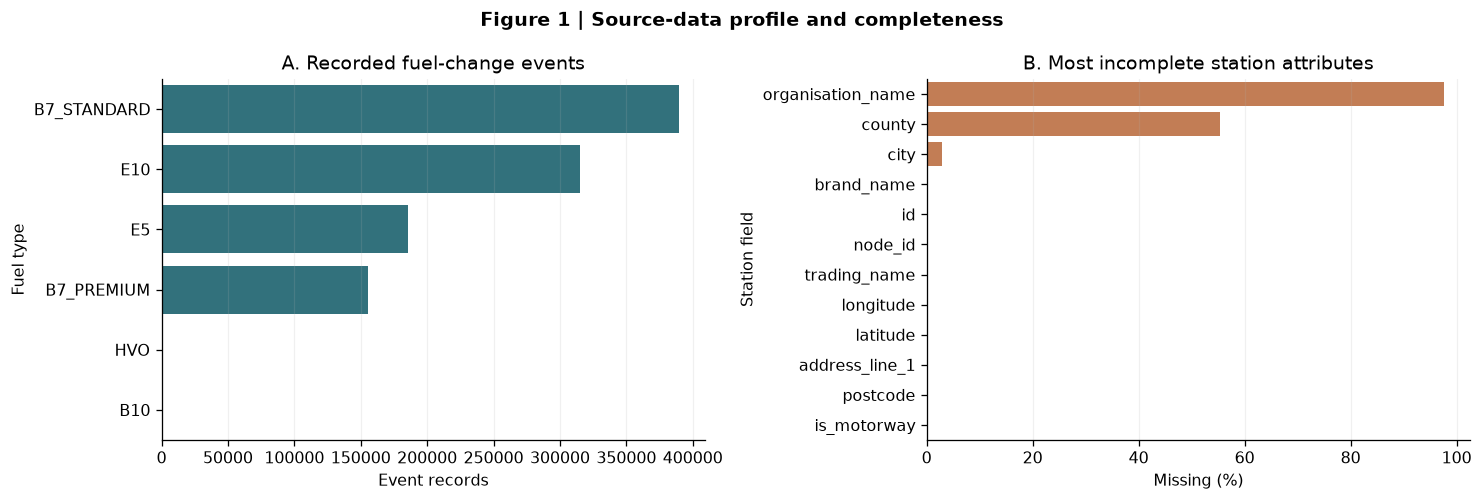

In [5]:
# Visualise which fuel types dominate and which station attributes are missing.
fig,axs=plt.subplots(1,2,figsize=(13,4.4))

sns.barplot(x=fuel_counts.values,y=fuel_counts.index.astype(str), color='#267A88', ax=axs[0]);axs[0].set(title='A. Recorded fuel-change events', xlabel='Event records', ylabel='Fuel type')
sns.barplot(x=missing_pct.head(12).values,y=missing_pct.head(12).index, color='#D47843', ax=axs[1]);axs[1].set(title='B. Most incomplete station attributes', xlabel='Missing (%)', ylabel='Station field')

fig.suptitle('Figure 1 | Source-data profile and completeness', fontweight='bold');fig.tight_layout();plt.show()

## 2. Clean the price observations

I have kept E10 petrol and B7 standard diesel, convert timestamps to UTC, and screen prices outside 80–350 pence per litre. That numerical range is a **data-quality choice**, not an economic law; it should be varied in a robustness check. Records with inconsistent collection/source times are removed, and multiple records for a station/fuel/day are reduced to the latest observation.

The station ID stays in the dataset for matching. Missing city or county information does not make an otherwise valid price unusable.

For the daily reconstruction, an observed price may be carried forward for at most **six additional days**. This is an assumption about available information, not evidence that the forecourt left its price unchanged.

### 2.1. Standardising timestamps and assessing data quality

Convert the original timestamp and price fields into usable data types and count flagged observations. The screening categories can overlap.

In [6]:
# Converting source timestamps and prices before applying filters.
raw['recorded_at'] = pd.to_datetime(raw['recorded_at'], utc=True, errors='coerce')
raw['source_updated_at'] = pd.to_datetime(raw['source_updated_at'], utc=True, errors='coerce')
raw['price_pence'] = pd.to_numeric(raw['price_pence'], errors='coerce')

cut_reason=pd.Series({
    'Not E10 or B7 standard':int((~raw.fuel_type.isin(FUELS)).sum()),
    'Invalid/missing price':int(raw.price_pence.isna().sum()),
    'Outside 80–350p screen':int((~raw.price_pence.between(80,350)).sum()),
    'Missing recorded timestamp':int(raw.recorded_at.isna().sum()),
    'Source timestamp later than recorded':int((raw.source_updated_at>raw.recorded_at).sum())
})

display(cut_reason.to_frame('Rows flagged (categories overlap)'))

,Rows flagged (categories overlap)
Not E10 or B7 standard,343463
Invalid/missing price,0
Outside 80–350p screen,1084
Missing recorded timestamp,0
Source timestamp later than recorded,24168


### 2.2. Filtering and deduplicating fuel-price events

Retain valid E10 and B7 observations, keep the latest station-fuel-day record and add station attributes for later descriptive analysis.

In [7]:
# Remove invalid observations, without discarding rows for missing county or city.
valid=raw[
    raw.fuel_type.isin(FUELS) & raw.price_pence.between(80,350) &
    raw.recorded_at.notna() & raw.source_updated_at.notna() &
    (raw.source_updated_at<=raw.recorded_at)
].copy()

# Resolve multiple updates on one date to the last recorded station value.
valid['date'] = valid.recorded_at.dt.tz_convert(None).dt.floor('D')
valid = valid.sort_values(['recorded_at','id']).drop_duplicates(['fuel_type','node_id','date'], keep='last')
valid = valid.merge(stations[['node_id','brand_name','city','county','is_motorway','is_supermarket']],
                  on='node_id', how='left', validate='many_to_one')

# Print the relevant data
print(f'Rows retained after cleaning/daily event deduplication: {len(valid):,}')
print('Latest date after cleaning:',valid.date.max().date())
print('Missing station link after merge:',valid.brand_name.isna().sum())

Rows retained after cleaning/daily event deduplication: 648,928
Latest date after cleaning: 2026-09-23
Missing station link after merge: 385


## 3. Reconstructing the daily station-matched price index

A simple daily mean of newly reported prices can move simply because a different mix of stations reported that day. To reduce this composition effect, I have compared a station with **its own price on the previous day**, using only pairs with sufficiently recent observations. I then have averaged those changes and added them to a starting value on **23 February 2026**.

### 3.1. Setting up the daily reconstruction

Prepare the full calendar and containers for the station-level matrices and reconstructed indices.

In [8]:
# Constructing a daily price index from matched station-to-station changes.
all_frames = []; matrices = {}

# Constructing an explicit daily calendar; missing reporting days remain visible.
calendar = pd.date_range('2026-02-07', INDEX_END, freq='D')

### 3.2. Calculating the matched-station price indices

Use last-known station prices within the stated freshness rule, average paired changes and chain-link those changes into a daily index for each fuel.

In [9]:
# Reconstruct each fuel index from matched station prices
for fuel in FUELS:
    events = valid.loc[valid.fuel_type == fuel,['date','node_id','price_pence']]
    obs = events.pivot(index='date', columns='node_id', values='price_pence').reindex(calendar)

    # Carry known prices forward for no more than the configured freshness window.
    asof = obs.ffill(limit=FRESH_DAYS-1)
    paired = (asof-asof.shift(1)).where(asof.notna() & asof.shift(1).notna())

    ix = pd.DataFrame(index=calendar)
    ix['observed_event_mean']=obs.mean(axis=1)
    ix['last_known_station_mean']=asof.mean(axis=1)
    ix['spatial_std']=asof.std(axis=1)
    ix['observed_stations']=obs.count(axis=1)
    ix['active_stations']=asof.count(axis=1)
    ix['paired_stations']=paired.notna().sum(axis=1)
    ix['mean_paired_change']=paired.mean(axis=1)
    ix = ix.loc[INDEX_START:INDEX_END].copy()

    increments = ix.mean_paired_change.iloc[1:].fillna(0)

    # Chain daily matched-station changes from the first usable mean price.
    ix['matched_price_index'] = ix.last_known_station_mean.iloc[0]+pd.concat([
        pd.Series([0.],index=[INDEX_START]), increments]).cumsum()
    ix['fuel_type'] = fuel
    ix.index.name = 'date'
    matrices[fuel] = asof.loc[INDEX_START:INDEX_END]
    all_frames.append(ix.reset_index())

panel = pd.concat(all_frames,ignore_index=True)

### 3.3. Checking the reconstructed indices

Summarise daily observations and reporting coverage and confirm that both reconstructed price series contain usable values.

In [10]:
# Check the typical number of observed and usable stations for both fuels.
summary = panel.groupby('fuel_type').agg(days=('date','size'), mean_index=('matched_price_index','mean'),
   median_reporting_stations = ('observed_stations','median'), min_active=('active_stations','min'),
   median_active = ('active_stations','median'), median_paired=('paired_stations','median'),
   mean_spatial_sd = ('spatial_std','mean')).round(2)
display(summary)

assert panel.matched_price_index.notna().all()

,days,mean_index,median_reporting_stations,min_active,median_active,median_paired,mean_spatial_sd
fuel_type,,,,,,,
B7_STANDARD,203,175.56,1343.0,3183,6026.0,5854.0,5.45
E10,203,153.20,1049.0,2639,5224.0,4711.0,5.19


### 3.4. Visualising index construction and station coverage

Figure 2 contrasts the matched-station index, recent station coverage, raw event means and across-station price dispersion.

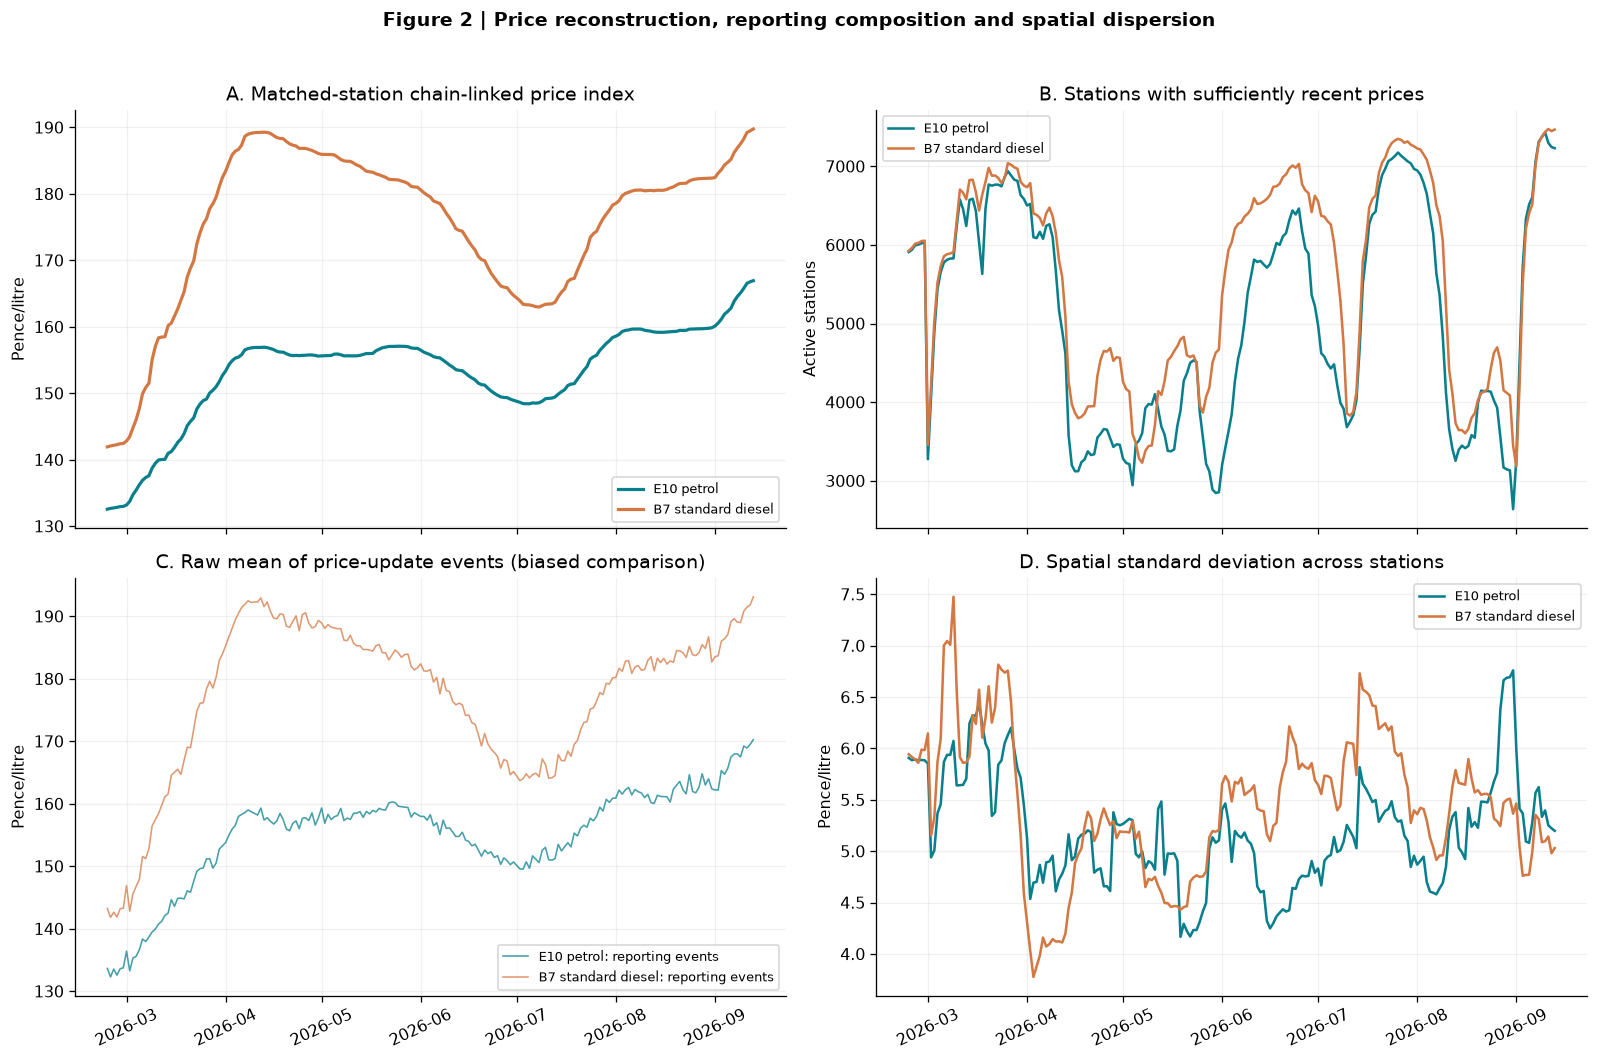

In [11]:
# The two coverage plots help show whether the changing number of reporting stations matters.
fig,axs = plt.subplots(2, 2, figsize=(14,9), sharex='col')

# Each plot answers a different data-coverage or price-construction question.
for fuel in FUELS:
    z = panel[panel.fuel_type==fuel].set_index('date'); c=PAL[fuel]
    axs[0,0].plot(z.index,z.matched_price_index, label=LABELS[fuel], color=c, lw=2)
    axs[0,1].plot(z.index,z.active_stations, label=LABELS[fuel], color=c, lw=1.6)
    axs[1,0].plot(z.index,z.observed_event_mean, label=f'{LABELS[fuel]}: reporting events', lw=1, alpha=.75, color=c)
    axs[1,1].plot(z.index,z.spatial_std, label=LABELS[fuel], lw=1.6, color=c)

axs[0,0].set(title='A. Matched-station chain-linked price index', ylabel='Pence/litre')
axs[0,1].set(title='B. Stations with sufficiently recent prices', ylabel='Active stations')
axs[1,0].set(title='C. Raw mean of price-update events (biased comparison)', ylabel='Pence/litre')
axs[1,1].set(title='D. Spatial standard deviation across stations', ylabel='Pence/litre')

for ax in axs.ravel():ax.legend(fontsize=8);ax.tick_params(axis='x', rotation=25)

fig.suptitle('Figure 2 | Price reconstruction, reporting composition and spatial dispersion', fontweight='bold', y=1.02)
fig.tight_layout();plt.show()

### 3.5. Comparing forecourt groups

I also have looked at supermarkets and motorway stations because the station file includes those classifications. The charts compare observed price levels and show how many stations contribute to each line. They are **descriptive comparisons only**: a difference between groups is not proof that one group's pricing strategy caused it. County coverage is too incomplete to justify a comprehensive county ranking.

**Supermarket and motorway price comparisons**

Compare the observed last-known station prices by forecourt type. These are descriptive groups rather than verified historical causal effects.

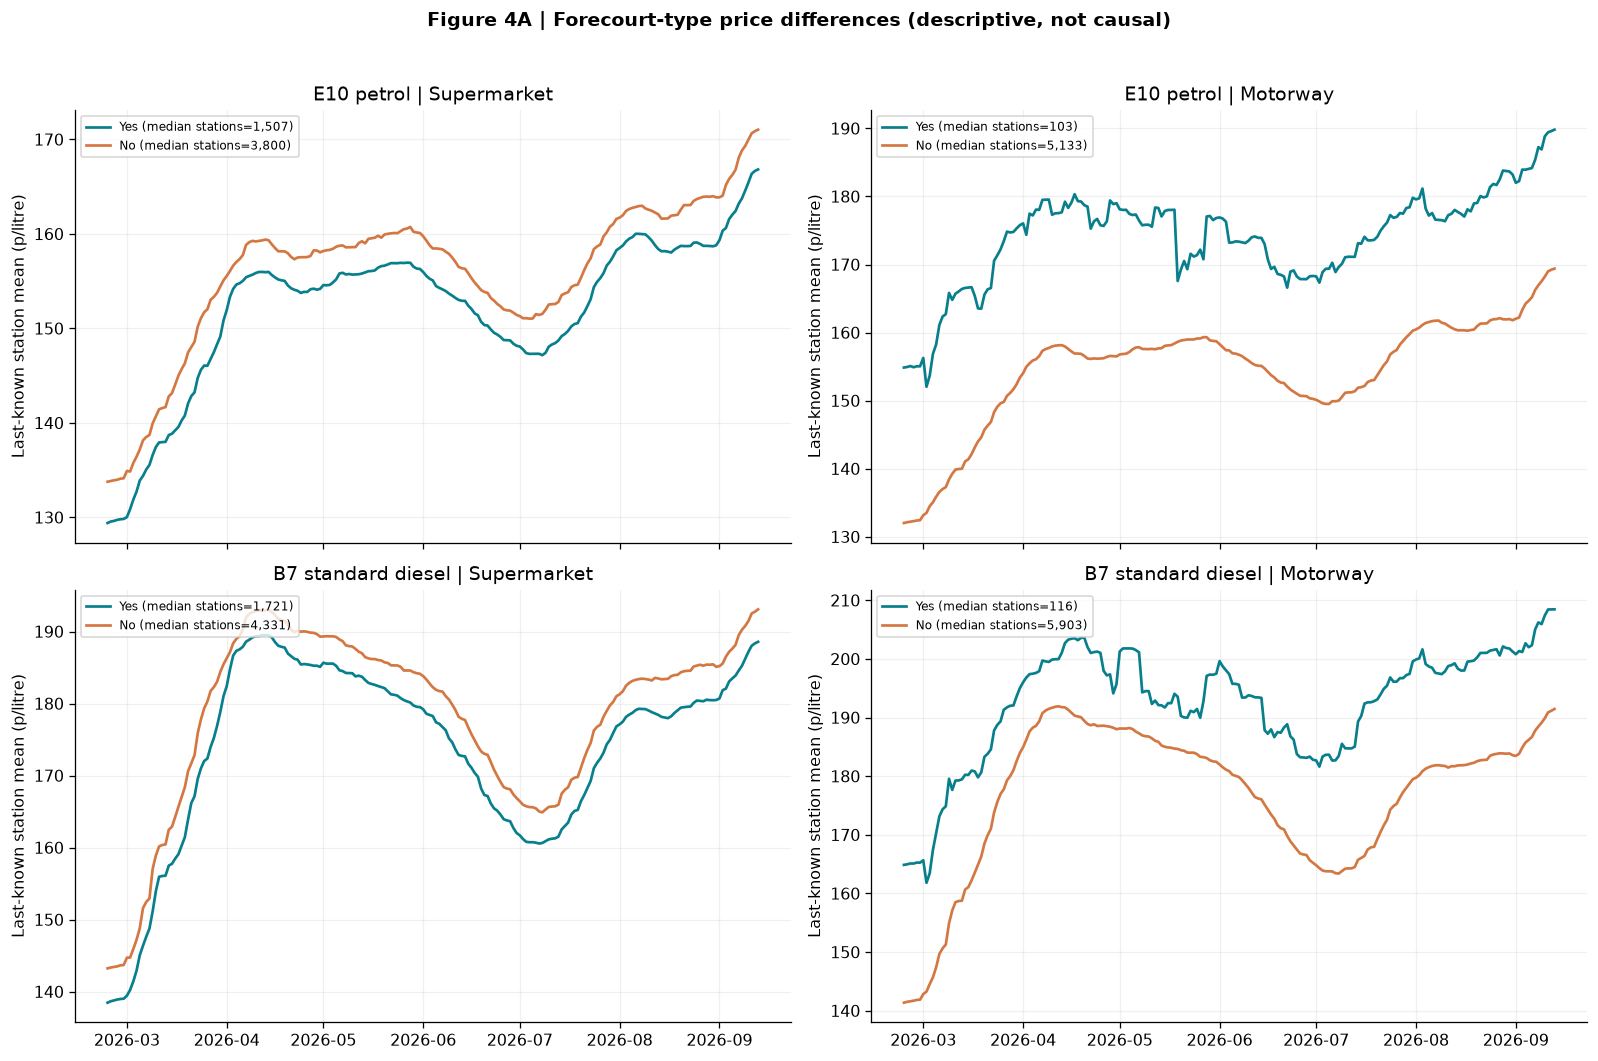

,fuel_type,category,value,median_stations,mean_price_pence
0,E10,is_supermarket,True,1507,152.16
1,E10,is_supermarket,False,3800,155.99
2,E10,is_motorway,True,103,174.06
3,E10,is_motorway,False,5133,154.52
4,B7_STANDARD,is_supermarket,True,1721,173.81
5,B7_STANDARD,is_supermarket,False,4331,178.38
6,B7_STANDARD,is_motorway,True,116,192.56
7,B7_STANDARD,is_motorway,False,5903,176.79


In [12]:
# Compare supermarket and motorway groups using the available station metadata.
metadata = stations.set_index('node_id')
fig,axs = plt.subplots(2, 2, figsize=(14,9), sharex=True)
subgroup_rows = []

# Comparing the observed subgroup means, retaining sample sizes in the labels.
for i,fuel in enumerate(FUELS):
    matrix = matrices[fuel]
    for j,flag in enumerate(['is_supermarket','is_motorway']):
        ax = axs[i,j]
        for value,color,lab in [(True,'#087F8C','Yes'),(False,'#D47843','No')]:
            nodes=metadata.index[metadata[flag].fillna(False).astype(bool)==value]
            columns=matrix.columns.intersection(nodes)
            vals=matrix[columns].mean(axis=1)
            counts=matrix[columns].count(axis=1)
            ax.plot(vals.index,vals,color=color, lw=1.7, label=f'{lab} (median stations={int(counts.median()):,})')
            subgroup_rows.append({'fuel_type':fuel,'category':flag,'value':value,'median_stations':int(counts.median()),
                                  'mean_price_pence':float(vals.mean())})
        ax.set(title=f'{LABELS[fuel]} | {flag.replace("is_","").replace("_"," ").title()}', ylabel='Last-known station mean (p/litre)')
        ax.legend(fontsize=7.5, loc='upper left')

fig.suptitle('Figure 4A | Forecourt-type price differences (descriptive, not causal)',fontweight='bold',y=1.02)
fig.tight_layout();plt.show()
display(pd.DataFrame(subgroup_rows).round(2))

**Representation of station brands**

Figure 4B shows the brands most frequently represented in the station metadata, which helps contextualise the sample.

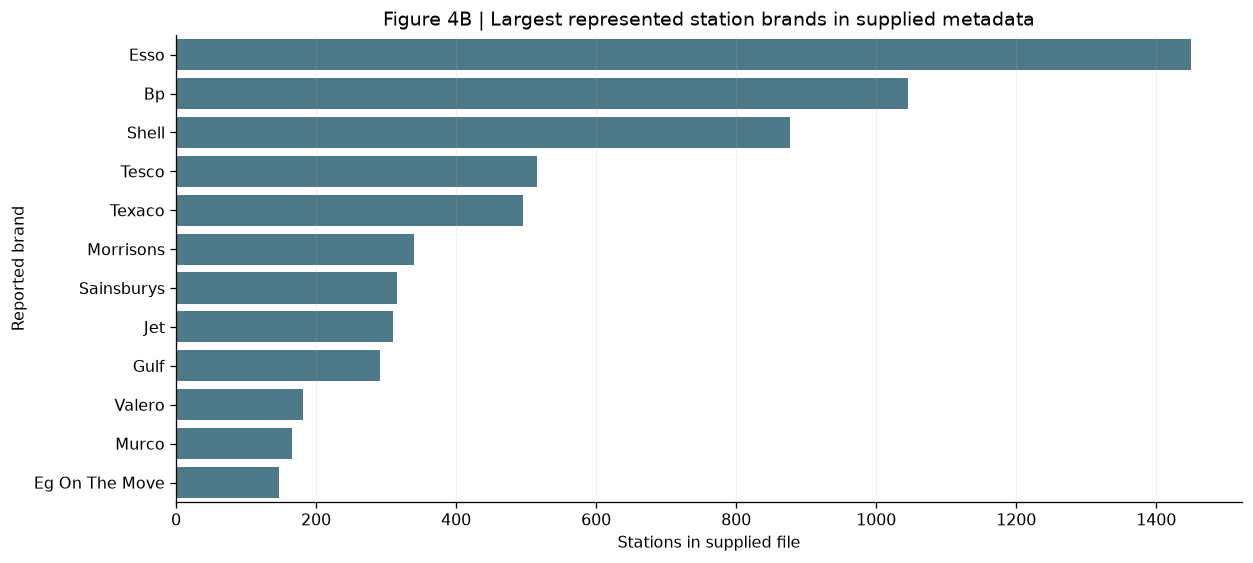

In [13]:
# Summarise the leading station brands in the metadata
brands = stations.brand_name.fillna('Unknown').astype(str).str.strip().replace('','Unknown').value_counts().head(12)

# Plotting the graphs
fig,ax = plt.subplots(figsize=(11,5))
sns.barplot(x=brands.values,y=brands.index,ax=ax,color='#437E92')
ax.set(title='Figure 4B | Largest represented station brands in supplied metadata',xlabel='Stations in supplied file',ylabel='Reported brand')
fig.tight_layout();plt.show()

## 4. Examining the price movements and dispersion

I have used two different measures here. **Temporal volatility** to describe the variation in the index's daily changes over a recent window and **Spatial dispersion** to describe how widely the prices of different stations vary on the same day. They answer different questions, so I have keept their graphs and interpretation separate.

### 4.1. Calculating daily changes and trailing volatility

Create daily changes and rolling standard deviations for the reconstructed price indices. These describe temporal movement, not geographical differences.

In [14]:
# Keep price movements over time separate from differences between stations.
panel = panel.sort_values(['fuel_type','date']).copy()

# First calculate daily changes; then measure their trailing variability.
panel['daily_price_change'] = panel.groupby('fuel_type').matched_price_index.diff()
panel['rolling_volatility_7d'] = panel.groupby('fuel_type').daily_price_change.transform(lambda s:s.rolling(7,min_periods=7).std())
panel['rolling_volatility_14d'] = panel.groupby('fuel_type').daily_price_change.transform(lambda s:s.rolling(14,min_periods=14).std())

### 4.2. Comparing temporal and spatial measures

Figure 3 contrasts daily movements, rolling temporal volatility, across-station price dispersion and reporting coverage.

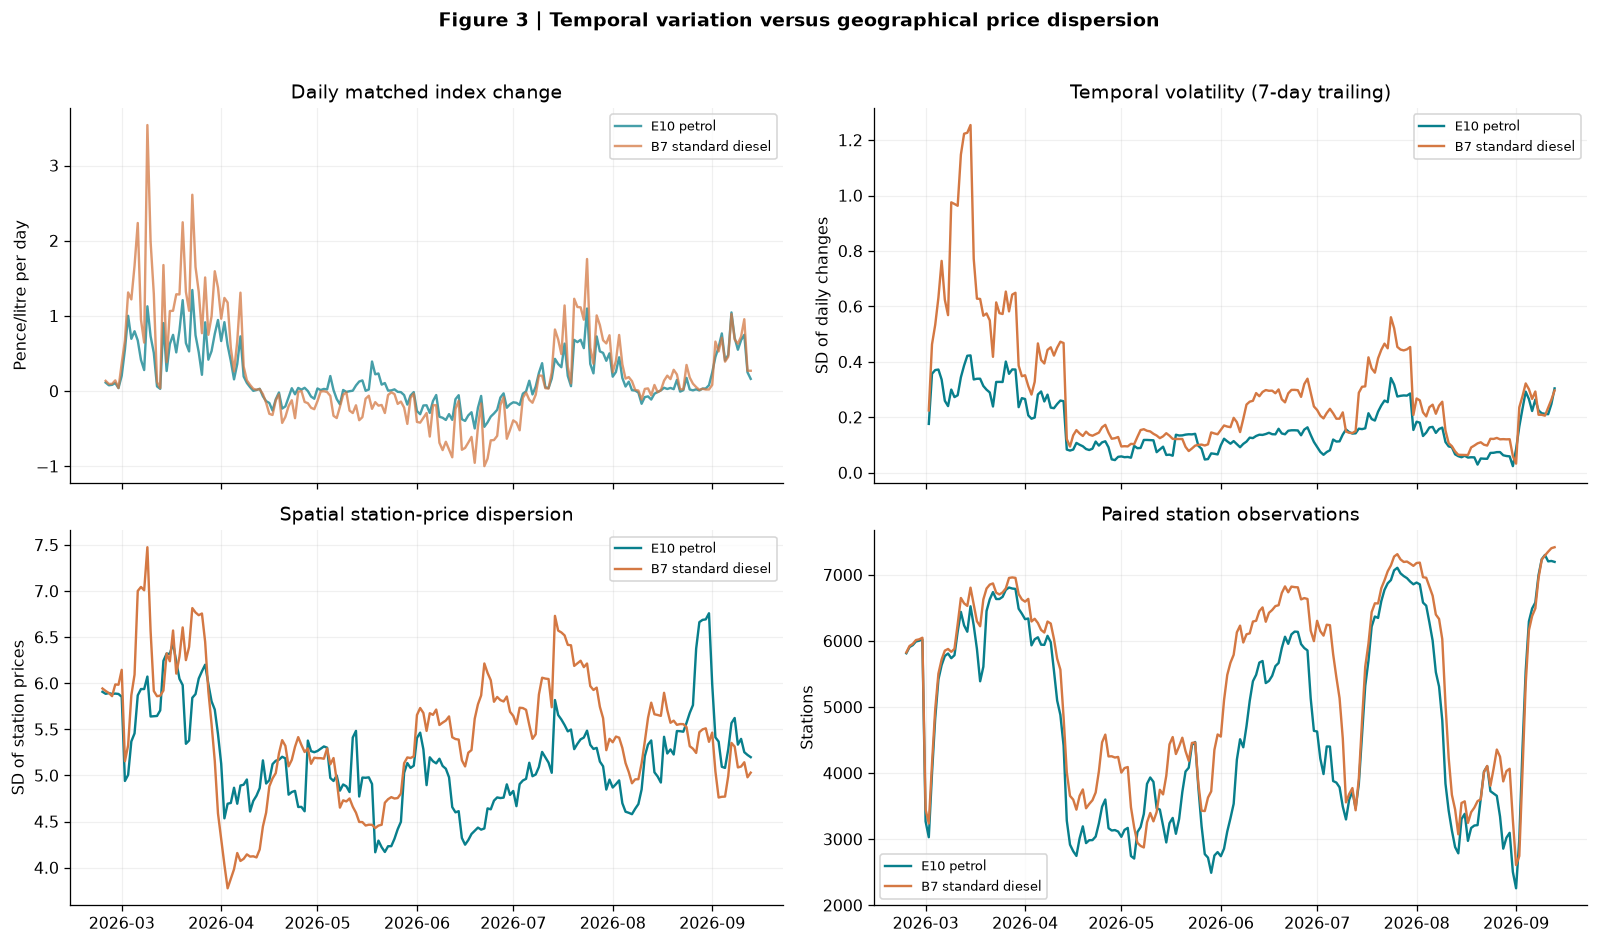

In [15]:
# Contrast movement over time with across-station price dispersion.
fig,axes = plt.subplots(2, 2, figsize=(14,8), sharex=True)

for fuel in FUELS:
    z = panel[panel.fuel_type==fuel].set_index('date'); c=PAL[fuel]
    axes[0,0].plot(z.index,z.daily_price_change, label=LABELS[fuel], color=c, alpha=.75)
    axes[0,1].plot(z.index,z.rolling_volatility_7d, label=LABELS[fuel], color=c)
    axes[1,0].plot(z.index,z.spatial_std, label=LABELS[fuel], color=c)
    axes[1,1].plot(z.index,z.paired_stations, label=LABELS[fuel], color=c)

# Plotting the graphs
for ax,title,ylabel in zip(axes.flat,['Daily matched index change','Temporal volatility (7-day trailing)','Spatial station-price dispersion','Paired station observations'],['Pence/litre per day','SD of daily changes','SD of station prices','Stations']):
    ax.set(title=title,ylabel=ylabel);ax.legend(fontsize=8)
    
fig.suptitle('Figure 3 | Temporal variation versus geographical price dispersion',fontweight='bold',y=1.02)
fig.tight_layout();plt.show()

## 5. Preparing the forecasting features and dates

For each fuel type, the task is to predict the price **1-day, 7-days or 14 calendar days ahead**. Inputs include the price observed at the forecast date, older prices, changes and rolling summaries. Future prices never enter those inputs.

I have fitted models on records whose targets were already observable by the training cutoff. Validation runs on **1-14 June, 22 June-5 July and 13-26 July 2026**; the separate holdout begins on **3 August 2026**. Forecasts may use observations newly available at later origins within a block, but the fitted model is not given unknown future targets.

The first 29 days are dropped where lagged features are incomplete.

### 5.1. Engineering historical forecasting features

Define the same lagged price, change, rolling-statistic, calendar and station-coverage inputs for each fuel. All inputs precede or coincide with the forecast origin.

In [16]:
# Building predictors that would have been known on each forecast date.

# I have used earlier prices, changes and rolling summaries rather than future observations.

# Creating the same predictor set for each fuel; the future label is added separately.
def feature_matrix(frame):
    s = frame.set_index('date').sort_index().matched_price_index.asfreq('D').astype(float)
    coverage = frame.set_index('date').active_stations.reindex(s.index)
    X = pd.DataFrame(index=s.index)
    X['price_t'] = s
    for lag in [1,2,3,7,14,21,28]: X[f'price_lag_{lag}']=s.shift(lag)
    for lag in [1,3,7,14,28]: X[f'change_{lag}']=s.diff(lag)
    
    d = s.diff()
    for w in [7,14,28]:
        X[f'avg_change_{w}']=d.rolling(w).mean()
        X[f'sd_change_{w}']=d.rolling(w).std()
        X[f'rolling_level_{w}']=s.rolling(w).mean()

    X['weekday_sin']=np.sin(2*np.pi*s.index.dayofweek/7)
    X['weekday_cos']=np.cos(2*np.pi*s.index.dayofweek/7)
    X['active_stations_t']=coverage.astype(float)
    X['delta_station_coverage_7d']=coverage.diff(7)

    return s,X.dropna()

### 5.2. Preparing fuel-specific feature matrices

Build the E10 and diesel feature sets used consistently by the model-comparison experiments.

In [17]:
# Prepare the fuel-specific forecasting feature matrices
series_features = {fuel:feature_matrix(panel[panel.fuel_type==fuel]) for fuel in FUELS}
split_plot = panel[panel.fuel_type=='E10'].set_index('date').matched_price_index

### 5.3. Visualising chronological evaluation windows

Figure 4 shows the three validation windows and later holdout period on the observed E10 and B7 price indices.

**Plotting each fuel and its evaluation periods**

Define the chart for one fuel, including its reconstructed index, three validation periods and the final holdout.

In [18]:
# Shading the same three validation windows and one final holdout period as in the original figure.
def _shade_price_evaluation_periods(ax):
    for i, start in enumerate(VAL_STARTS):
        ax.axvspan(start, start + pd.Timedelta(days=13),
                   color='#D3A039', alpha=0.20,
                   label='Validation period' if i == 0 else None)
    ax.axvspan(TEST_START, INDEX_END, color='#C44F52',
               alpha=0.15, label='Holdout test period')

In [19]:
# Plotting the reconstructed price index, overlay the evaluation periods and keep the original axis styling.
def _plot_evaluation_periods_for_fuel(ax, fuel):
    fuel_data = (panel[panel['fuel_type'] == fuel]
                 .set_index('date').sort_index())
    ax.plot(fuel_data.index, fuel_data['matched_price_index'],
            linewidth=2, color=PAL[fuel], label=LABELS[fuel])
    _shade_price_evaluation_periods(ax)
    ax.set_title(f'{LABELS[fuel]} — Forecast evaluation periods')
    ax.set_ylabel('Price index (pence/litre)')
    ax.grid(alpha=0.2)
    ax.legend(loc='upper left')

**Displaying both chronological evaluation panels**

Generate the E10 and B7 panels with the same dates, lines, highlighting and chart title as the original figure.

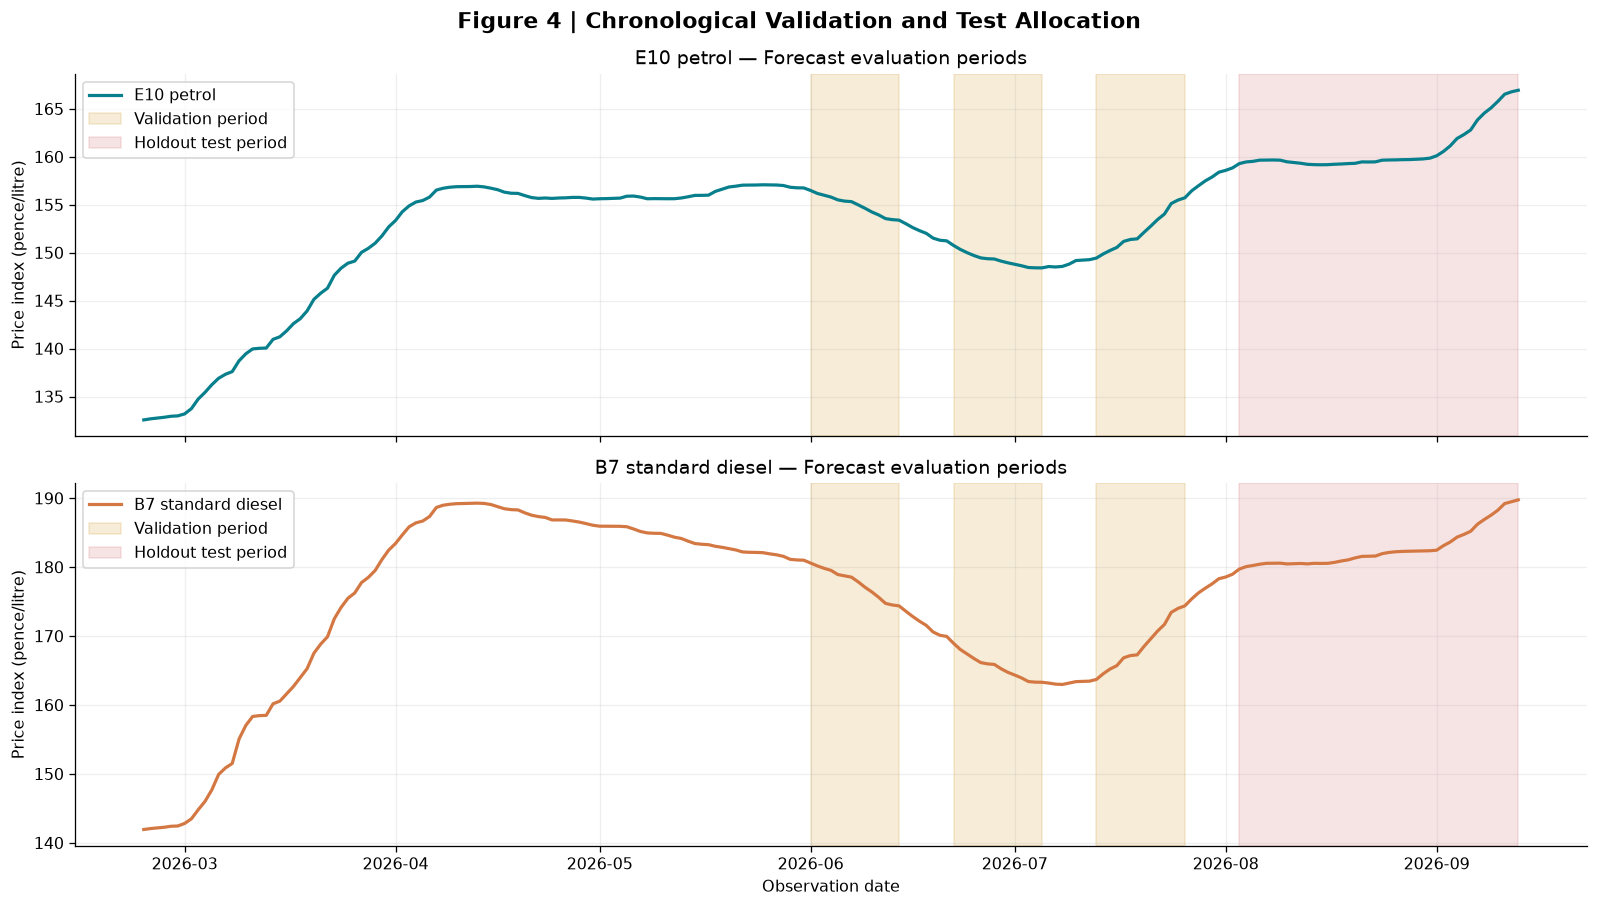

In [20]:
# Create the same two-panel evaluation-period figure.
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
for ax, fuel in zip(axes, ['E10', 'B7_STANDARD']):
    _plot_evaluation_periods_for_fuel(ax, fuel)
axes[-1].set_xlabel('Observation date')
fig.suptitle('Figure 4 | Chronological Validation and Test Allocation',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## 6. Train the four price-forecasting models

I have compared **LSTM, XGBoost, LightGBM and SARIMAX** on the same forecasting dates. XGBoost and LightGBM predict the change from the current index to the chosen horizon. The LSTM learns patterns from 28 days of previous changes; its scaling and training decisions use training observations only. SARIMAX uses the initial ARIMA(1,1,0) specification in this first comparison, without economic variables.

I have also included persistence and a seasonal-naive forecast as checks: a more complex model should earn its place by beating a simple reference. Parameters are fixed for this benchmark and are **not claimed to be optimally tuned**.

**6.1. XGBoost Model**

XGBoost is used to capture nonlinear relationships between historical fuel prices and the features created earlier. The model uses relatively shallow trees and regularisation, to help control overfitting on the available time-series data.

Hyperparameters are kept fixed across both fuel types and all forecasting horizons for a consistent comparison.

In [21]:
# Define the fixed XGBoost price-level model
def xgboost_model():

    model = XGBRegressor(
        n_estimators=160,
        max_depth=2,
        learning_rate=0.035,
        min_child_weight=4,
        subsample=0.9,
        colsample_bytree=0.9,
        reg_lambda=8,
        objective='reg:squarederror',
        n_jobs=2,
        random_state=SEED
    )

    return model


**6.2. LightGBM Model**

LightGBM provides a second tree-based forecasting approach. Unlike XGBoost, LightGBM uses leaf-wise tree growth. The number of leaves and maximum tree depth are restricted to reduce the risk of fitting unnecessary complexity.

The same settings are applied to E10 petrol and B7 diesel to maintain consistency in the model comparison.


In [22]:
# Define the fixed LightGBM price-level model
def lightgbm_model():

    model = LGBMRegressor(
        n_estimators=130,
        num_leaves=7,
        max_depth=3,
        min_child_samples=7,
        learning_rate=0.035,
        reg_lambda=8,
        verbosity=-1,
        random_state=SEED,
        n_jobs=2
    )

    return model

**6.3. Selecting the tree-model implementation**

This helper preserves the common interface used in later forecast loops without changing the two model specifications.

In [23]:
# Managing both tree models under same umbrella

def tree_model(name):

    if name == 'XGBoost':
        return xgboost_model()

    if name == 'LightGBM':
        return lightgbm_model()

    raise ValueError(name)


**6.4. LSTM Model**

The LSTM model learns patterns from sequences of historical daily fuel-price changes. A 28-day lookback window is used to capture recent movements before forecasting the selected horizon.

Unlike the tree-based methods, the LSTM learns directly from sequential observations rather than engineered tabular features.

In [24]:
# Extracting one historical LSTM sequence and label
def _one_lstm_training_pair(series, changes, dt, h, lookback):
    j = series.index.get_loc(dt)
    if j < lookback - 1 or j + h >= len(series):
        return None
    seq = changes.iloc[j - lookback + 1:j + 1].to_numpy()
    label = float(series.iloc[j + h] - series.iloc[j])
    return seq, label

In [25]:
# Assembling all LSTM training sequences
def _prepare_lstm_training_arrays(series, h, train_origins, lookback):
    changes = series.diff().fillna(0)
    seqs, labels = [], []
    for dt in train_origins:
        sample = _one_lstm_training_pair(series, changes, dt, h, lookback)
        if sample is None:
            continue
        seq, label = sample
        seqs.append(seq)
        labels.append(label)
    seqs = np.asarray(seqs)
    labels = np.asarray(labels)
    if len(labels) < 30:
        raise ValueError('Insufficient LSTM training samples')
    return seqs, labels

In [26]:
# Define the neural network architecture.
class _LSTMNetwork(nn.Module):

    def __init__(self):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=1,
            hidden_size=12,
            batch_first=True
        )

        self.out = nn.Linear(12, 1)

    def forward(self, x):

        lstm_output, _ = self.lstm(x)

        return self.out(
            lstm_output[:, -1, :]
        )

In [27]:
# Fitting the network with early stopping
def _lstm_train_epoch(net, optimizer, loss_fn, xx, yy, split):
    net.train()
    optimizer.zero_grad()
    loss = loss_fn(net(xx[:split]), yy[:split])
    loss.backward()
    optimizer.step()
    return loss

In [28]:
# Determining Internal LSTM Validation Loss
def _lstm_internal_loss(net, loss_fn, xx, yy, split, train_loss):
    net.eval()
    with torch.no_grad():
        if split < len(xx):
            return float(loss_fn(net(xx[split:]), yy[split:]))
        return float(train_loss)

In [29]:
# Fitting the LSTM and restoring the best weights
def _train_lstm_network(xx, yy):
    net = _LSTMNetwork()
    optimizer = torch.optim.Adam(net.parameters(), lr=0.008, weight_decay=0.003)
    loss_fn = nn.MSELoss()
    split = max(18, int(len(xx) * 0.85))
    best, stall, best_weights = float('inf'), 0, None

    for epoch in range(95):
        loss = _lstm_train_epoch(net, optimizer, loss_fn, xx, yy, split)
        v = _lstm_internal_loss(net, loss_fn, xx, yy, split, loss)
        if v < best - 1e-4:
            best = v
            best_weights = {k: w.clone() for k, w in net.state_dict().items()}
            stall = 0
        else:
            stall += 1
            if stall > 14:
                break

    if best_weights:
        net.load_state_dict(best_weights)
    return net

In [30]:
# Scaling training sequences using training-only statistics, fit the network and convert predicted price changes back to price-level forecasts.
def _scale_lstm_inputs(seqs, labels):
    mu = float(seqs.mean())
    sd = max(float(seqs.std()), 0.01)
    y_mu = float(labels.mean())
    y_sd = max(float(labels.std()), 0.05)
    xx = torch.tensor((seqs - mu) / sd, dtype=torch.float32).unsqueeze(-1)
    yy = torch.tensor((labels - y_mu) / y_sd, dtype=torch.float32).view(-1, 1)
    return mu, sd, y_mu, y_sd, xx, yy

In [31]:
# Predicting one future price from its historical sequence
def _lstm_forecast_origin(forecaster, changes, dt):
    j = forecaster.s.index.get_loc(dt)
    seq = changes.iloc[j - forecaster.window + 1:j + 1].to_numpy()
    x = torch.tensor((seq - forecaster.mu) / forecaster.sd,
                     dtype=torch.float32).view(1, -1, 1)
    delta = float(forecaster.net(x)[0, 0]) * forecaster.y_sd + forecaster.y_mu
    return float(forecaster.s.loc[dt]) + delta

In [32]:
# LSTM forecasting interface
class LSTMForecaster:
    def __init__(self, series, h, train_origins, lookback=28):
        torch.manual_seed(SEED)
        self.s, self.h, self.window = series, h, lookback
        seqs, labels = _prepare_lstm_training_arrays(series, h, train_origins, lookback)
        (self.mu, self.sd, self.y_mu, self.y_sd,
         xx, yy) = _scale_lstm_inputs(seqs, labels)
        self.net = _train_lstm_network(xx, yy)

    def predict(self, origins):
        changes = self.s.diff().fillna(0)
        result = []
        self.net.eval()
        with torch.no_grad():
            for dt in origins:
                result.append(_lstm_forecast_origin(self, changes, dt))
        return np.asarray(result)

### 6.5. SARIMAX Model

SARIMAX provides a statistical forecasting benchmark against the machine-learning approaches. The initial specification uses an ARIMA(1,1,0) structure, with first-order differencing to model changes in prices.

No external predictors are included at this stage. Brent crude oil and exchange-rate variables are added separately in the later exogenous-factor experiment.

In [33]:
# Estimating the fixed baseline SARIMAX parameters

# Fitting the same nonseasonal ARIMA(1,1,0) model on observations available at the training cutoff.
def _fit_baseline_sarimax(history):
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        fit = SARIMAX(
            history, order=(1, 1, 0), trend='n',
            enforce_stationarity=False,
            enforce_invertibility=False
        ).fit(disp=False, maxiter=70)
    return fit

In [34]:
# Forecasting from the filtered SARIMAX state
def _forecast_sarimax_from_origin(s, dt, h, params):
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        state = SARIMAX(
            s.loc[:dt], order=(1, 1, 0), trend='n',
            enforce_stationarity=False,
            enforce_invertibility=False
        ).filter(params)
        forecast = state.forecast(steps=h)
    return float(forecast.iloc[-1])

In [35]:
# Predicting all requested origins
def sarimax_preds(s, cutoff, origins, h):
    fit = _fit_baseline_sarimax(s.loc[:cutoff])
    preds = [_forecast_sarimax_from_origin(s, dt, h, fit.params) for dt in origins]
    return np.asarray(preds)

## 7. Fitting each model on the same chronological splits

The next cell runs each candidate for both fuels at all three horizons. It saves the forecast origin, observed future price, model prediction and error. Keeping this table makes the later comparison auditable and ensures every model is judged on the same dates.

### 7.1. Defining one chronological forecasting fold

Apply the same forecast dates to all price-level models and simple baselines. Training labels must mature by the fold cutoff.

**Build a matched set of price-level forecasts**

Fit both tree models, LSTM and SARIMAX and include the same persistence/seasonal-naive baselines.

In [36]:
# Generating matched price-level model forecasts for a chronological fold
def _price_level_fold_forecasts(fuel, h, origins, cutoff):
    s, X = series_features[fuel]
    train_origins = X.index[X.index + pd.Timedelta(days=h) <= cutoff]
    origins = pd.DatetimeIndex(origins)
    origins = origins[origins.isin(X.index) &
                      (origins + pd.Timedelta(days=h) <= s.index.max())]
    assert len(train_origins) >= 30 and len(origins) > 0
    y_train = (s.shift(-h) - s).loc[train_origins]
    p_t = s.loc[origins].values
    pred = {'Persistence': p_t,
            'SeasonalNaive': s.reindex(origins - pd.Timedelta(days=7)).values}
    for name in ['XGBoost', 'LightGBM']:
        model = tree_model(name)
        model.fit(X.loc[train_origins], y_train)
        pred[name] = p_t + model.predict(X.loc[origins])
    pred['LSTM'] = LSTMForecaster(s, h, train_origins).predict(origins)
    pred['SARIMAX'] = sarimax_preds(s, cutoff, origins, h)
    return s, origins, pred

**Save observed and predicted prices by model**

Keep forecast origins, future target dates, actual prices and all model predictions in one consistent record format.

In [37]:
# Formating price-level forecasts as auditable evaluation records
def _price_fold_result_rows(fuel, h, fold_name, origins, s, pred):
    truth = s.reindex(origins + pd.Timedelta(days=h)).values
    output = []
    for name, forecast in pred.items():
        for dt, y, p in zip(origins, truth, forecast):
            output.append({
                'fuel_type': fuel, 'horizon_days': h, 'fold': fold_name,
                'origin_date': dt, 'target_date': dt + pd.Timedelta(days=h),
                'model': name, 'actual': float(y), 'prediction': float(p)
            })
    return output

**Run a chronological forecasting fold**

Retain the existing run_fold interface used by the validation and holdout experiment.

In [38]:
# Running a complete price-level forecasting fold
def run_fold(fuel, h, origins, cutoff, fold_name):
    s, valid_origins, pred = _price_level_fold_forecasts(fuel, h, origins, cutoff)
    return _price_fold_result_rows(fuel, h, fold_name, valid_origins, s, pred)

### 7.2. Running the validation and holdout experiments

Execute the three validation periods and final holdout for each fuel and horizon, and retain actual values, predictions and residuals.

In [39]:
# Generating price-level forecasts for validation and holdout periods
valid_rows=[];test_rows=[]

for fuel in FUELS:
    for h in HORIZONS:
        for fold_num,start in enumerate(VAL_STARTS,1):
            origins=pd.date_range(start,periods=14,freq='D')
            valid_rows+=run_fold(fuel,h,origins,start-pd.Timedelta(days=1),f'V{fold_num}')
        origins=pd.date_range(TEST_START,INDEX_END-pd.Timedelta(days=h),freq='D')
        test_rows+=run_fold(fuel,h,origins,TEST_START-pd.Timedelta(days=1),'TEST')
        print(f'Completed {LABELS[fuel]:17s} | {h:2d}-day | validation origins 42 | test origins {len(origins)}')
val_preds=pd.DataFrame(valid_rows);test_preds=pd.DataFrame(test_rows)

for d in [val_preds,test_preds]:
    d['error']=d.prediction-d.actual
    d['absolute_error']=abs(d.error)
    d['squared_error']=d.error**2

assert not val_preds[['actual','prediction']].isna().any().any()
assert not test_preds[['actual','prediction']].isna().any().any()
print('Real predictions generated:',len(val_preds),'validation /',len(test_preds),'test')

Completed E10 petrol        |  1-day | validation origins 42 | test origins 41
Completed E10 petrol        |  7-day | validation origins 42 | test origins 35
Completed E10 petrol        | 14-day | validation origins 42 | test origins 28
Completed B7 standard diesel |  1-day | validation origins 42 | test origins 41
Completed B7 standard diesel |  7-day | validation origins 42 | test origins 35
Completed B7 standard diesel | 14-day | validation origins 42 | test origins 28
Real predictions generated: 1512 validation / 1248 test


### 7.3. Visualising Individual Model Forecasting Behaviour

Following model training, the next step is to examine how each forecasting approach responds to observed fuel-price movements.

Although MAE, RMSE and R² provide numerical measures of forecasting accuracy, visual comparisons can help identify systematic overprediction, underprediction and differences in the ability of each model to follow price fluctuations.

The following analysis compares actual and predicted prices for E10 petrol and B7 standard diesel using the 7-day forecasting horizon. Prediction residuals are also examined to identify variations in forecasting errors.

Only predictions from the chronological validation periods are used in this section. The final holdout dataset remains reserved for the subsequent model evaluation.

In [40]:
# Plotting actual prices, predicted prices and residuals for each fold
def _plot_validation_fold_points(price_ax, residual_ax, model_data, fuel):
    for fold, fold_data in model_data.groupby('fold'):
        fold_data = fold_data.sort_values('target_date')
        price_ax.plot(
            fold_data['target_date'], fold_data['actual'],
            color='#263B59', linewidth=2.2, marker='o', markersize=3,
            label='Actual price' if fold == 'V1' else None
        )
        price_ax.plot(
            fold_data['target_date'], fold_data['prediction'],
            color=PAL[fuel], linewidth=1.8, linestyle='--', marker='.',
            label='Predicted price' if fold == 'V1' else None
        )
        residual_ax.scatter(
            fold_data['target_date'], fold_data['error'],
            color=PAL[fuel], alpha=0.75, s=28
        )

In [41]:
# Formatting fuel-price and residual diagnostic axes
def _style_validation_fuel_axes(price_ax, residual_ax, fuel):
    price_ax.set_title(f'{LABELS[fuel]} - Actual vs Predicted')
    price_ax.set_ylabel('Price index (pence/litre)')
    price_ax.legend(loc='best')
    price_ax.grid(alpha=0.2)
    residual_ax.axhline(y=0, color='black', linestyle='--', linewidth=1)
    residual_ax.set_title(f'{LABELS[fuel]} - Prediction Residuals')
    residual_ax.set_ylabel('Prediction error (pence/litre)')
    residual_ax.set_xlabel('Target date')
    residual_ax.grid(alpha=0.2)
    residual_ax.tick_params(axis='x', rotation=30)

In [42]:
# Combining price and residual diagnostic plotting helpers
def _plot_validation_fuel_panels(price_ax, residual_ax, model_data, fuel):
    _plot_validation_fold_points(price_ax, residual_ax, model_data, fuel)
    _style_validation_fuel_axes(price_ax, residual_ax, fuel)

In [43]:
# Building the four-panel validation diagnostic for a model
def plot_model_forecast_behaviour(model_name, forecast_horizon=7):
    # Four panels per model: observed/predicted index and residuals for both fuels.
    fig, axes = plt.subplots(2, 2, figsize=(15, 8), sharex='col')

    for col, fuel in enumerate(FUELS):
        model_data = val_preds[
            (val_preds['model'] == model_name) &
            (val_preds['fuel_type'] == fuel) &
            (val_preds['horizon_days'] == forecast_horizon)
        ].copy()
        model_data = model_data.sort_values('target_date')

        price_ax = axes[0, col]
        residual_ax = axes[1, col]
        _plot_validation_fuel_panels(price_ax, residual_ax, model_data, fuel)

    fig.suptitle(
        f'{model_name} - Seven-Day Forecasting Behaviour',
        fontsize=15,
        fontweight='bold'
    )
    plt.tight_layout()
    plt.show()

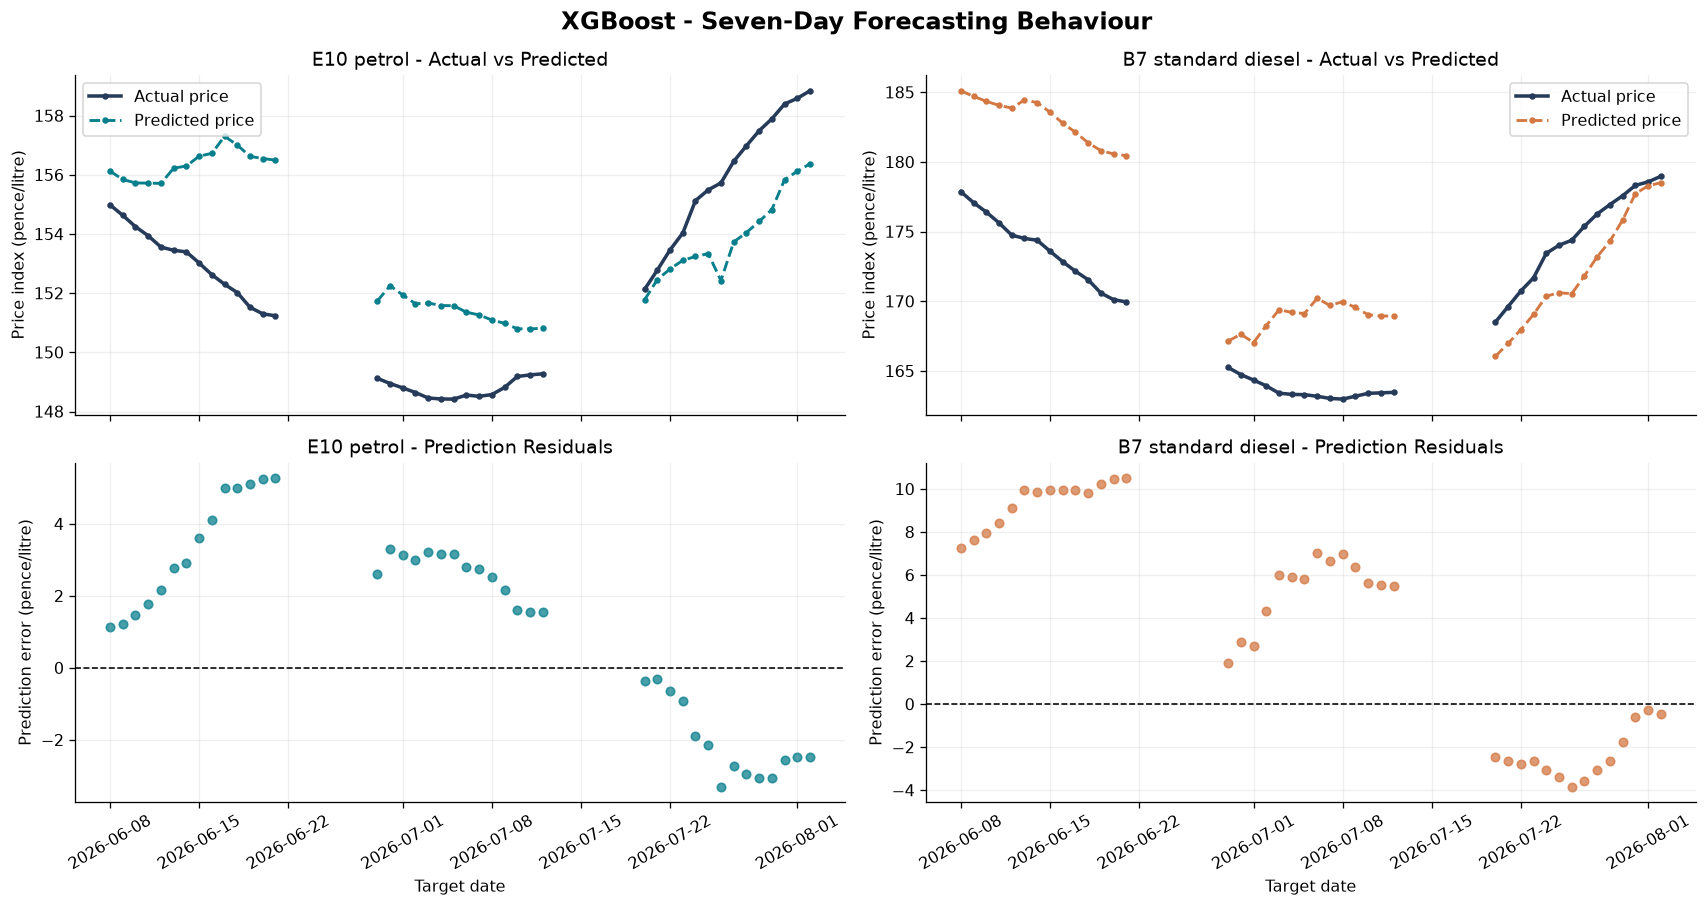

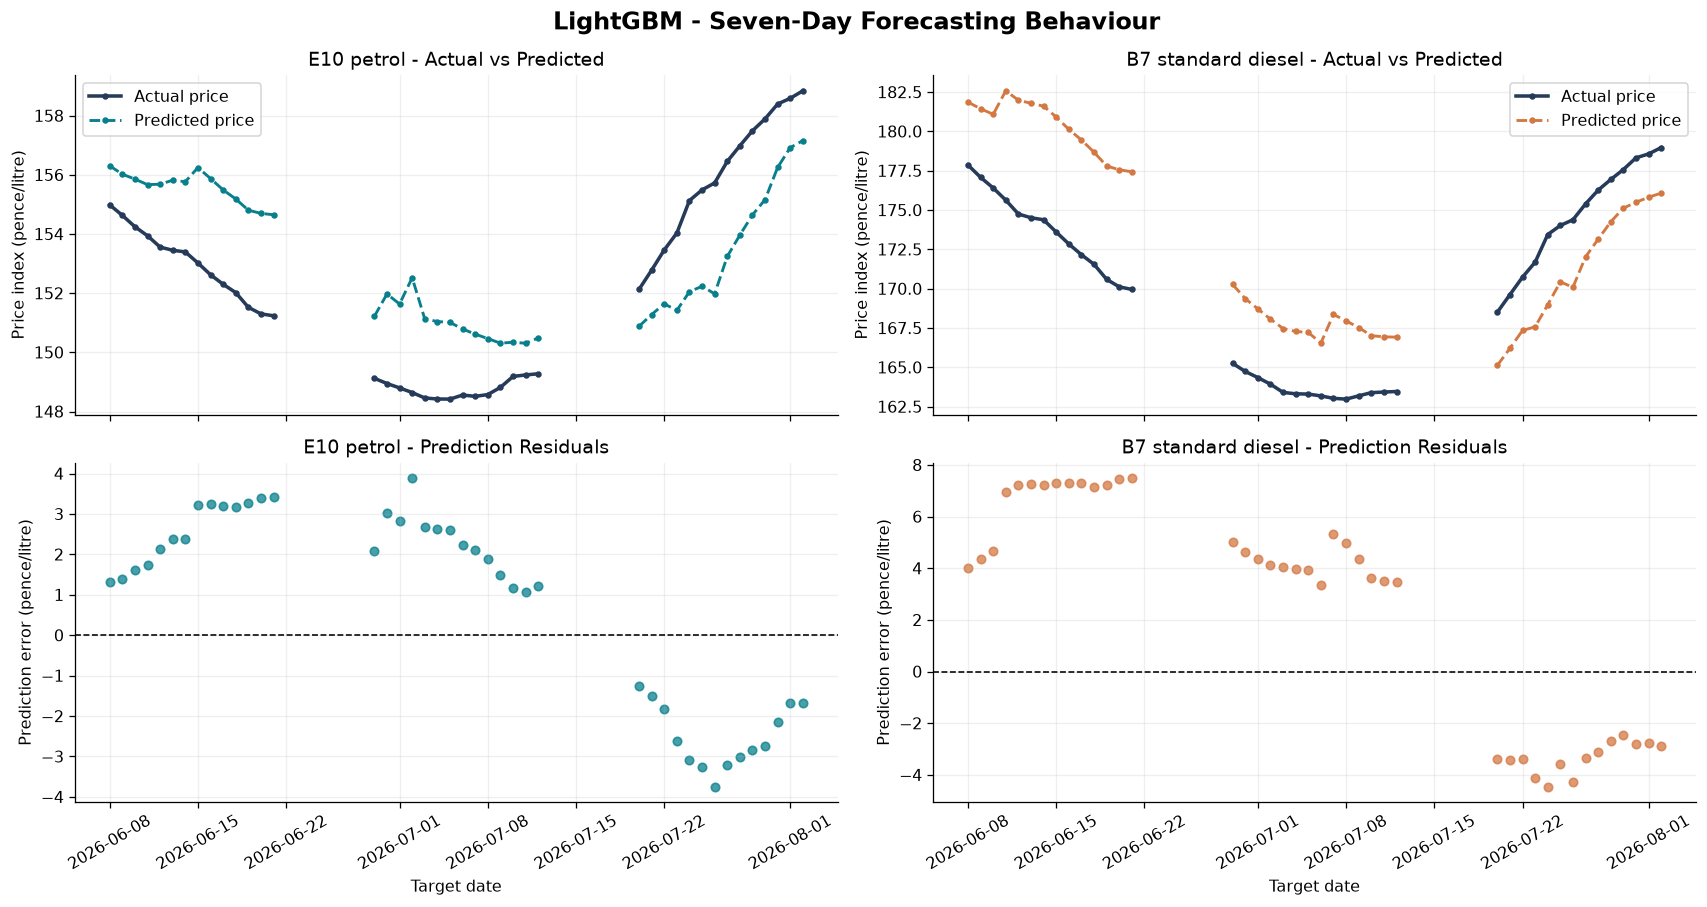

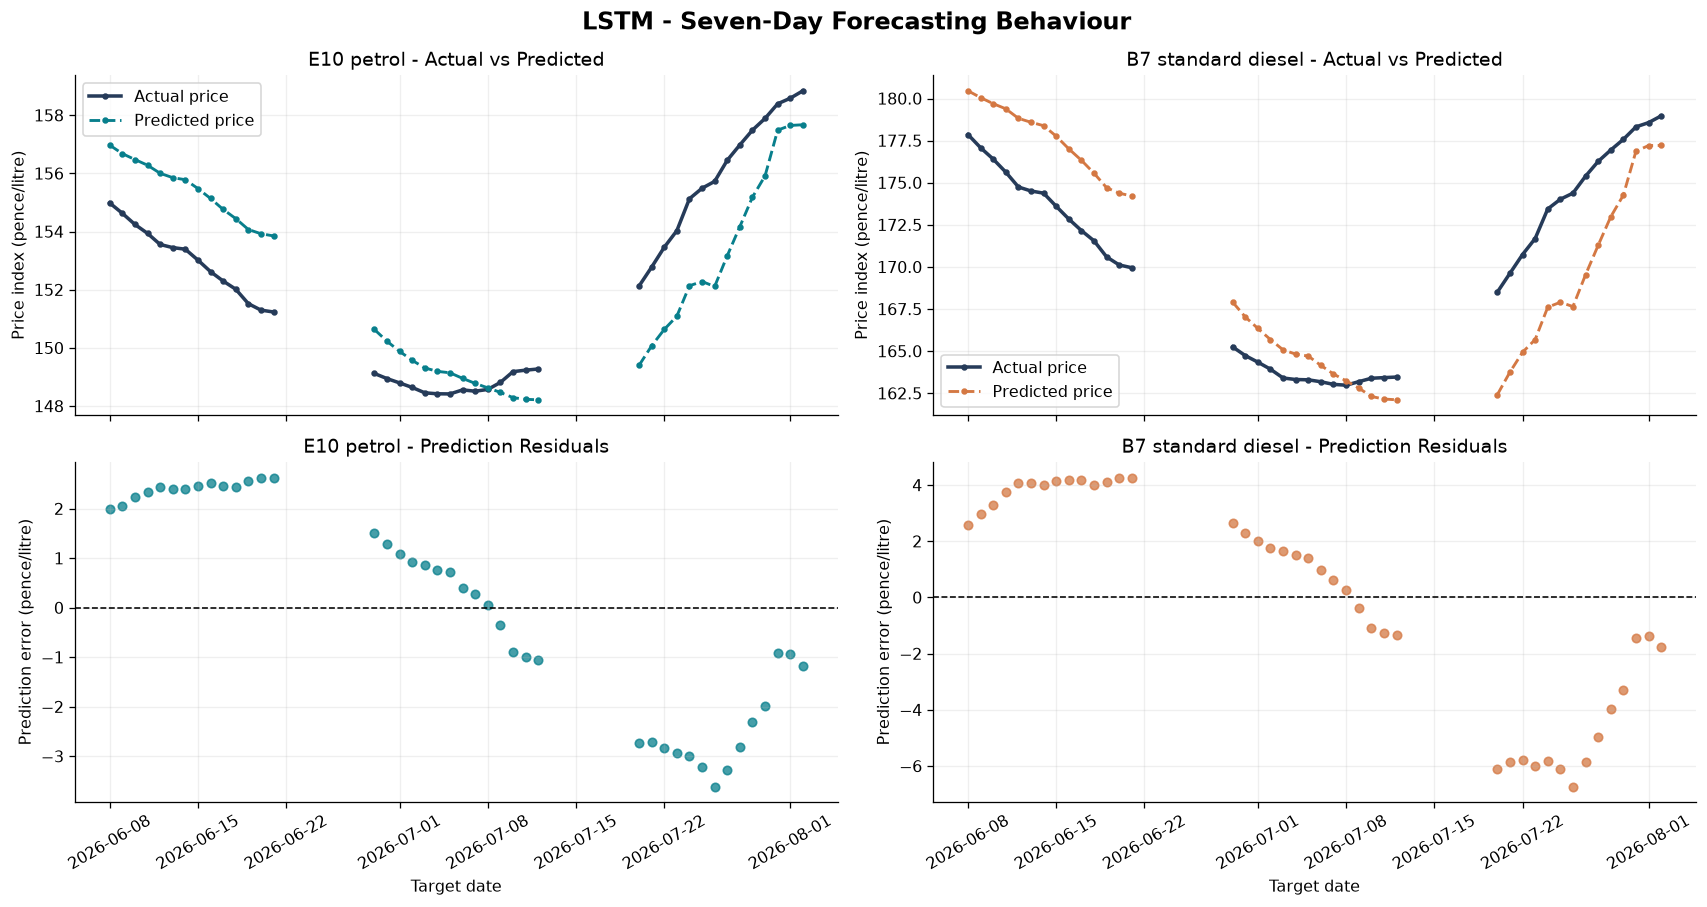

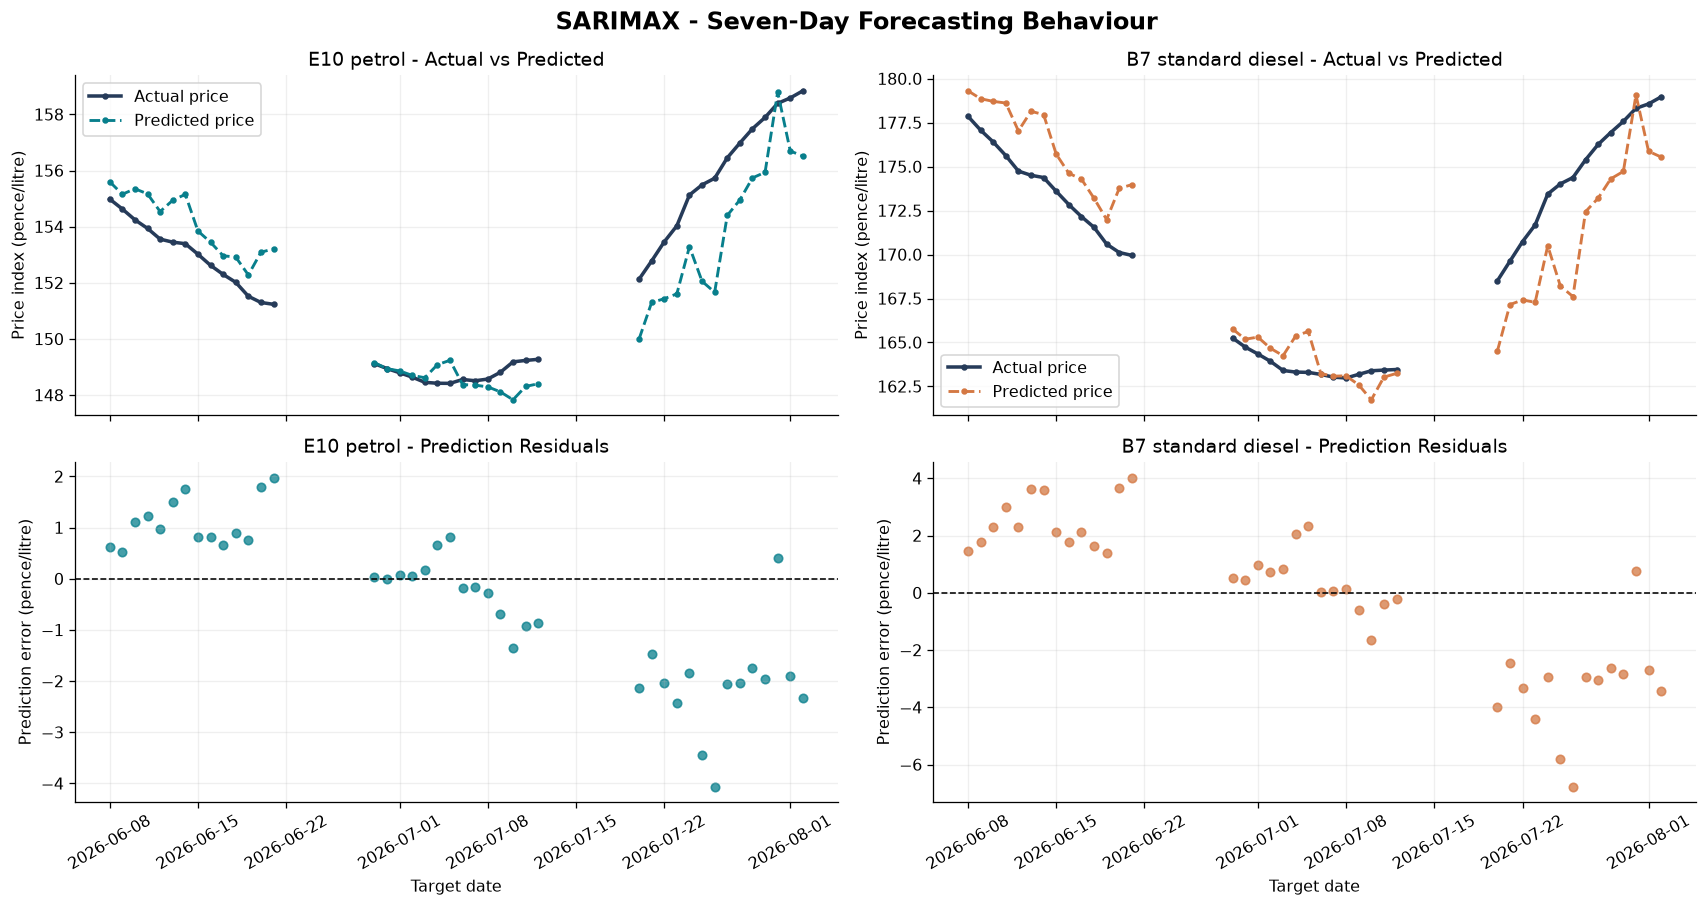

In [44]:
# Displaying all four price-level model diagnostics
models_to_plot = [
    'XGBoost',
    'LightGBM',
    'LSTM',
    'SARIMAX'
]

forecast_horizon = 7

for model_name in models_to_plot:
    plot_model_forecast_behaviour(model_name, forecast_horizon)

## 8. Comparing MAE, RMSE and R²

MAE is the average absolute miss; RMSE gives more weight to large mistakes. Both are measured in **pence per litre** and are better when smaller. R² is unitless and is better when larger; it can be negative when forecasts perform poorly.

Because this dataset covers a short and changing market period, R² depends on the variation in the evaluation segment. I therefore look at all three metrics and compare against simple forecasts rather than judging on R² alone.

### 8.1. Computing comparable forecast scores

Calculate MAE, RMSE, R² and signed bias separately for each fuel, horizon and fitted model.

In [45]:
# Calculating the forecast errors from the saved actual and predicted prices.
# MAE and RMSE are in pence per litre; R² measures explained variation on each evaluation set.

# Score each model separately for fuel type and forecasting horizon.
def score_predictions(d):
    rows=[]
    for (fuel,h,name),g in d.groupby(['fuel_type','horizon_days','model']):
        rows.append({'fuel_type':fuel,'horizon_days':h,'model':name,'n':len(g),
          'MAE':mean_absolute_error(g.actual,g.prediction),
          'RMSE':np.sqrt(mean_squared_error(g.actual,g.prediction)),
          'R2':r2_score(g.actual,g.prediction),
          'bias':float((g.prediction-g.actual).mean())})
    return pd.DataFrame(rows)

### 8.2. Reporting validation and holdout scores

Save the score tables and display the four model families for both chronological evaluation stages.

In [46]:
# Score the price-level forecasts on validation and holdout
validation_scores=score_predictions(val_preds)
test_scores=score_predictions(test_preds)

# Plotting the table
for title,tbl in [('VALIDATION - used for selecting the champion',validation_scores),
                  ('HELD-OUT TEST - only for reporting after selection',test_scores)]:
    display(Markdown('### '+title))
    display(tbl[tbl.model.isin(MODELS)].sort_values(['fuel_type','horizon_days','MAE']).round(4))

### VALIDATION - used for selecting the champion

,fuel_type,horizon_days,model,n,MAE,RMSE,R2,bias
3,B7_STANDARD,1,SARIMAX,42,0.2818,0.4051,0.9947,-0.0181
0,B7_STANDARD,1,LSTM,42,0.4594,0.5507,0.9903,0.0869
1,B7_STANDARD,1,LightGBM,42,0.5355,0.6886,0.9848,0.2046
5,B7_STANDARD,1,XGBoost,42,0.5470,0.6397,0.9869,0.2593
9,B7_STANDARD,7,SARIMAX,42,2.2341,2.6997,0.7609,-0.1554
6,B7_STANDARD,7,LSTM,42,3.2916,3.7622,0.5357,-0.0026
7,B7_STANDARD,7,LightGBM,42,4.7216,4.9967,0.1811,2.4963
11,B7_STANDARD,7,XGBoost,42,5.6532,6.4670,-0.3718,4.0734
15,B7_STANDARD,14,SARIMAX,42,5.3249,6.0534,0.0748,-0.4350
13,B7_STANDARD,14,LightGBM,42,7.8621,9.3074,-1.1872,3.9607


### HELD-OUT TEST - only for reporting after selection

,fuel_type,horizon_days,model,n,MAE,RMSE,R2,bias
3,B7_STANDARD,1,SARIMAX,41,0.1336,0.2049,0.9946,-0.0385
0,B7_STANDARD,1,LSTM,41,0.1403,0.2101,0.9943,-0.0683
1,B7_STANDARD,1,LightGBM,41,0.2912,0.3954,0.9799,-0.2085
5,B7_STANDARD,1,XGBoost,41,0.3162,0.4158,0.9778,-0.2585
9,B7_STANDARD,7,SARIMAX,35,1.2733,1.7247,0.6283,-1.0058
6,B7_STANDARD,7,LSTM,35,1.4652,1.9771,0.5115,-1.4371
11,B7_STANDARD,7,XGBoost,35,3.0460,3.3907,-0.4366,-2.7095
7,B7_STANDARD,7,LightGBM,35,3.0741,3.3656,-0.4155,-2.8953
15,B7_STANDARD,14,SARIMAX,28,2.4754,3.2236,-0.3343,-2.2950
12,B7_STANDARD,14,LSTM,28,4.9212,5.4013,-2.7461,-4.9212


## 9. Selecting a price model from validation results

To make a consistent selection, I have ranked the four requested models on **MAE (lowest first), RMSE (lowest first) and R² (highest first)** for each fuel/horizon task. I also have averaged those ranks across the six tasks. If ranks tie, average MAE relative to the persistence baseline decides the order.

I have used **validation scores only** for this choice. The holdout below tests whether the choice generalises; it is not used to swap models after seeing the outcome.

### 9.1. Ranking models using validation only

Rank MAE and RMSE from low to high and R² from high to low within each fuel-horizon task. Freeze the selected model before inspecting the holdout.

In [47]:
# Rank within each E10/diesel and 1/7/14-day task first.
ranks=validation_scores[validation_scores.model.isin(MODELS)].copy()

for metric,ascending in [('MAE',True),('RMSE',True),('R2',False)]:
    ranks[metric+'_rank']=ranks.groupby(['fuel_type','horizon_days'])[metric].rank(ascending=ascending,method='average')
base=validation_scores[validation_scores.model=='Persistence'][['fuel_type','horizon_days','MAE']].rename(columns={'MAE':'Persistence_MAE'})
ranks=ranks.merge(base,on=['fuel_type','horizon_days'])
ranks['relative_MAE']=ranks.MAE/ranks.Persistence_MAE
league=(ranks.groupby('model',as_index=False)
        .agg(avg_metric_rank=('MAE_rank','mean'),avg_RMSE_rank=('RMSE_rank','mean'),avg_R2_rank=('R2_rank','mean'),
             relative_MAE=('relative_MAE','mean')))
league['overall_rank']=(league.avg_metric_rank+league.avg_RMSE_rank+league.avg_R2_rank)/3
league=league.sort_values(['overall_rank','relative_MAE','model']).reset_index(drop=True)

# Freezing the selected model before examining the final holdout.
CHAMPION=str(league.iloc[0].model)
display(league.round(3))
display(Markdown(f'### Validation-selected champion: **{CHAMPION}**'))
assert CHAMPION in MODELS

,model,avg_metric_rank,avg_RMSE_rank,avg_R2_rank,relative_MAE,overall_rank
0,SARIMAX,1.000,1.000,1.000,0.601,1.000
1,LSTM,2.167,2.167,2.167,0.907,2.167
2,LightGBM,3.000,3.167,3.167,1.114,3.111
3,XGBoost,3.833,3.667,3.667,1.213,3.722


### Validation-selected champion: **SARIMAX**

### 9.2. Comparing validation MAE

Figure 5 displays the validation errors that support the selection decision across both fuels and all three horizons.

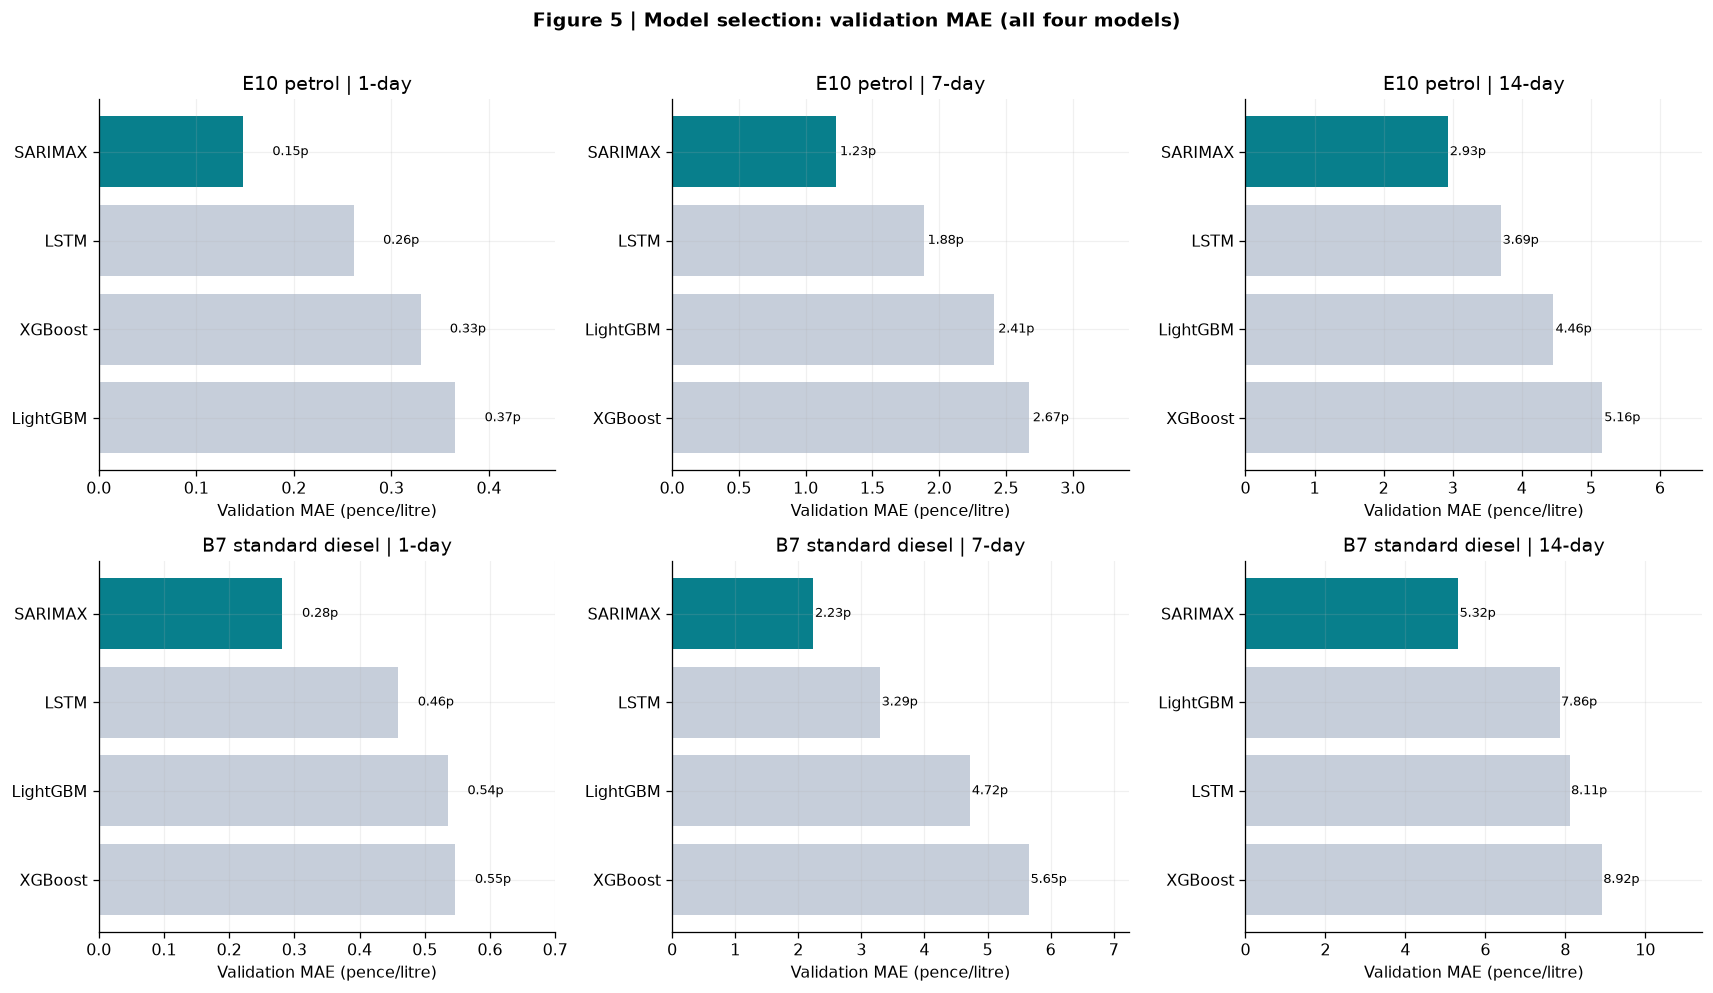

In [48]:
# Plotting the validation comparisons used to select the model.
fig,axs = plt.subplots(2,3,figsize=(15,8.5))

for i,fuel in enumerate(FUELS):
    for j,h in enumerate(HORIZONS):
        ax=axs[i,j]; sub=validation_scores[(validation_scores.fuel_type==fuel)&(validation_scores.horizon_days==h)&
                                             validation_scores.model.isin(MODELS)].sort_values('MAE')
        colors=['#087F8C' if m==CHAMPION else '#C6CEDA' for m in sub.model]
        ax.barh(sub.model,sub.MAE,color=colors);ax.invert_yaxis()
        for p,r in zip(ax.patches,sub.itertuples()):ax.text(p.get_width()+.03,p.get_y()+p.get_height()/2,f'{r.MAE:.2f}p',va='center',fontsize=8)
        ax.set(title=f'{LABELS[fuel]} | {h}-day',xlabel='Validation MAE (pence/litre)')
        ax.set_xlim(0,float(sub.MAE.max()*1.28))

fig.suptitle('Figure 5 | Model selection: validation MAE (all four models)',fontweight='bold',y=1.01)
fig.tight_layout();plt.show()

### 9.3. Inspecting all three validation metrics

Figure 6 retains MAE, RMSE and R² together rather than relying on a single accuracy measure.

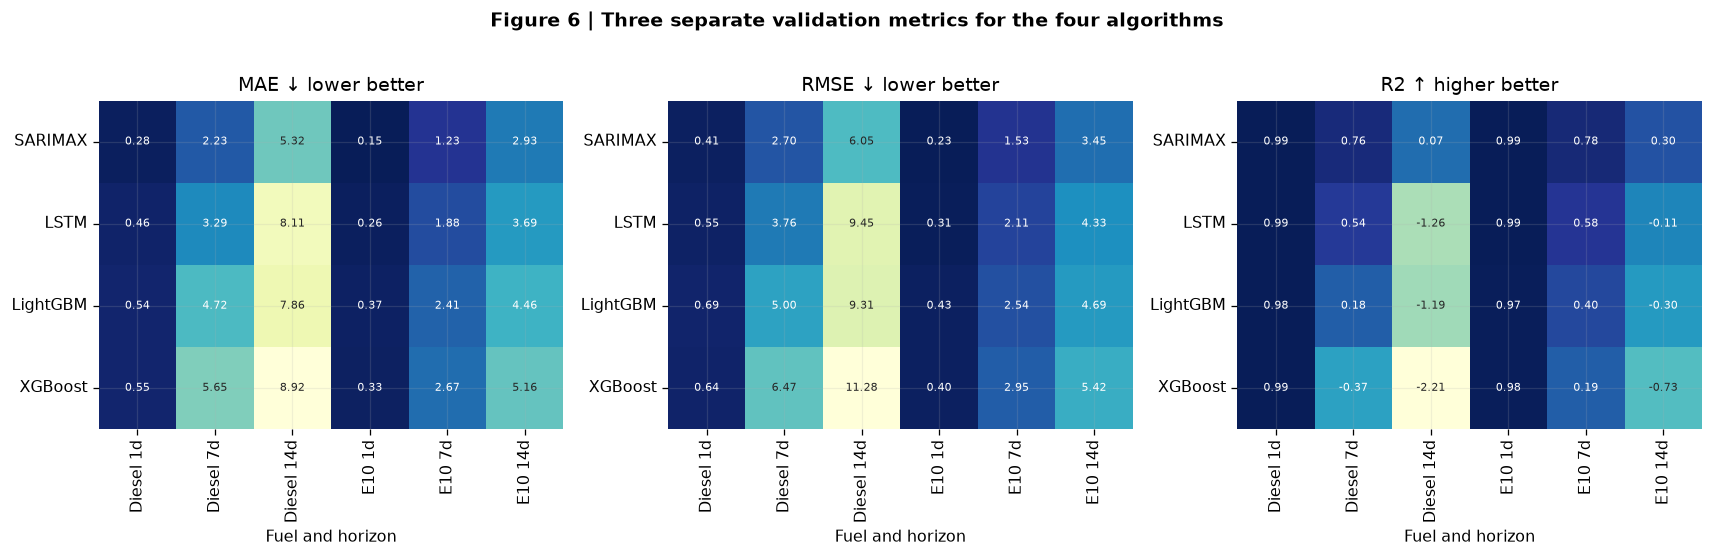

In [49]:
# Plotting the Heatmaps also retaining all three metrics, rather than presenting only MAE.
fig,axes = plt.subplots(1,3,figsize=(15,4.7))

for ax,metric,better in zip(axes,['MAE','RMSE','R2'],['↓ lower better','↓ lower better','↑ higher better']):
    z=validation_scores[validation_scores.model.isin(MODELS)].pivot_table(index='model',columns=['fuel_type','horizon_days'],values=metric).reindex(league.model)
    sns.heatmap(z,annot=True,fmt='.2f',cmap='YlGnBu_r' if metric!='R2' else 'YlGnBu',ax=ax,cbar=False,
                xticklabels=[f'{"Diesel" if f=="B7_STANDARD" else "E10"} {h}d' for f,h in z.columns],annot_kws={'fontsize':7})
    ax.set(title=f'{metric} {better}',ylabel='',xlabel='Fuel and horizon')
    ax.set_yticklabels(ax.get_yticklabels(),rotation=0)

fig.suptitle('Figure 6 | Three separate validation metrics for the four algorithms',fontweight='bold',y=1.02)
fig.tight_layout();plt.show()

## 10. Examining the final holdout

Now I can inspect performance on the later dates. The plots show how closely each model followed the observed index and whether errors lean positive or negative. A model other than the validation winner may be best on a particular holdout task; that is worth reporting, not hiding.

### 10.1. Comparing holdout MAE

Figure 7 reports holdout error by fuel and horizon, highlighting the validation-selected model without re-selecting it.

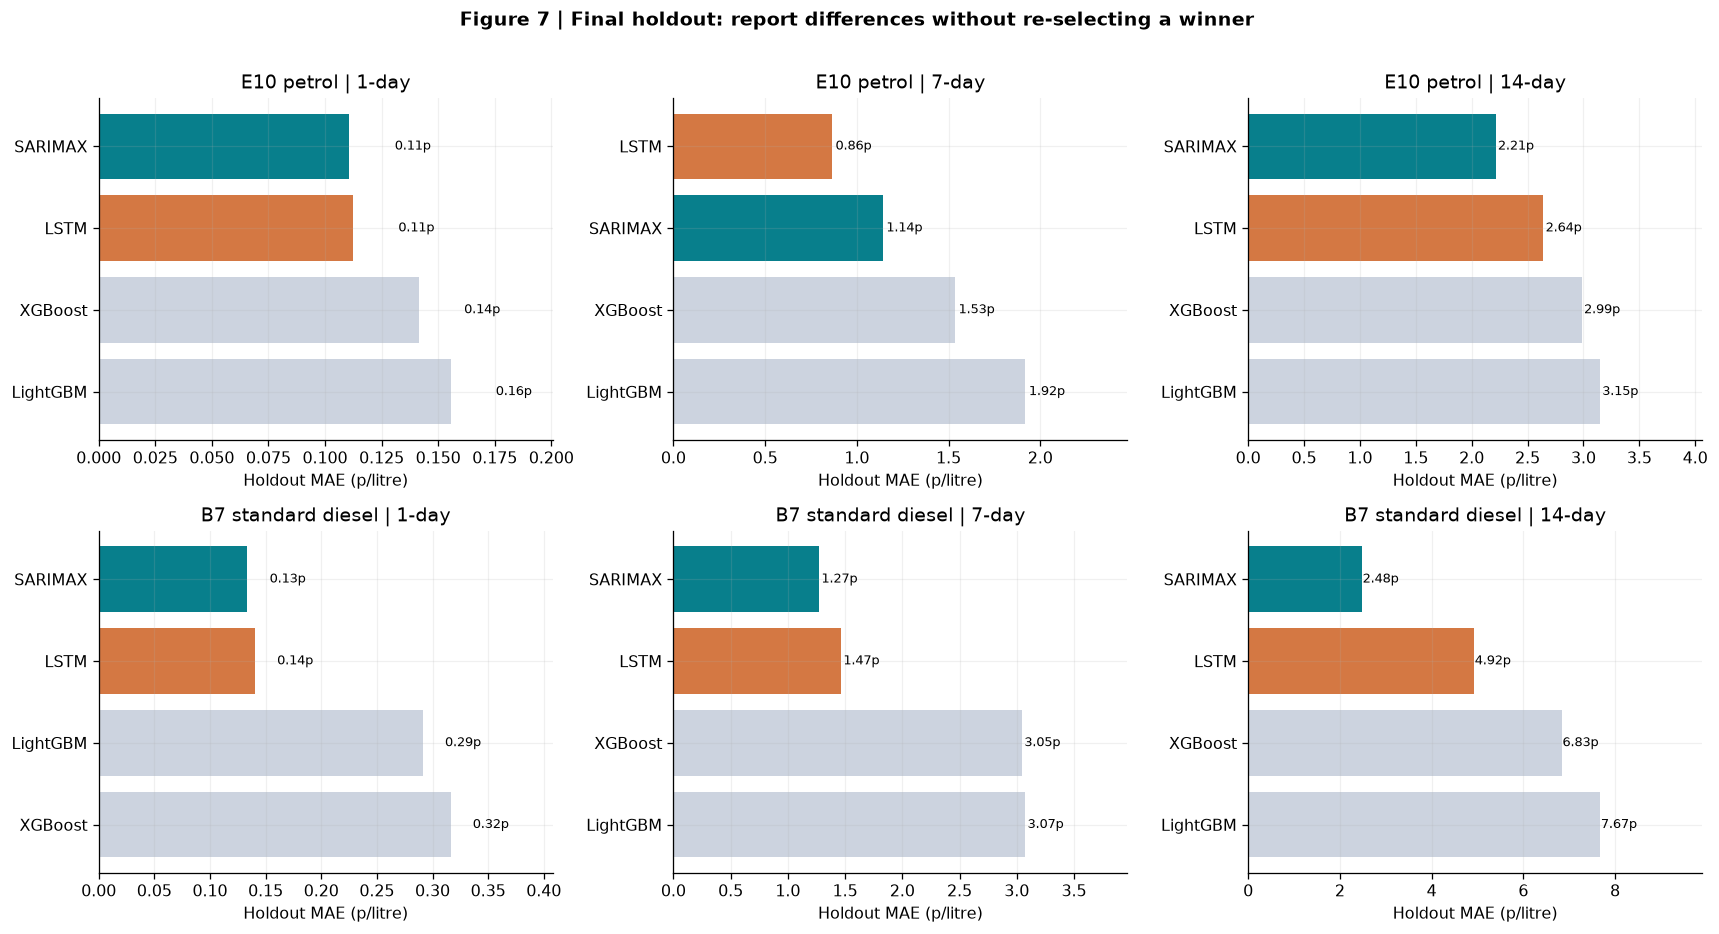

In [50]:
# Inspect the final holdout after the model-selection decision has been made.

# The line plots show actual prices and forecasts on the same dates.
fig,axs = plt.subplots(2,3,figsize=(15,8))
for i,fuel in enumerate(FUELS):
    for j,h in enumerate(HORIZONS):
        z=test_scores[(test_scores.fuel_type==fuel)&(test_scores.horizon_days==h)&test_scores.model.isin(MODELS)].sort_values('MAE')
        ax=axs[i,j]
        ax.barh(z.model,z.MAE,color=['#087F8C' if m==CHAMPION else '#D47843' if m=='LSTM' else '#CCD3DF' for m in z.model])
        ax.invert_yaxis();ax.set(title=f'{LABELS[fuel]} | {h}-day',xlabel='Holdout MAE (p/litre)')
        for p,row in zip(ax.patches,z.itertuples()):ax.text(p.get_width()+.02,p.get_y()+p.get_height()/2,f'{row.MAE:.2f}p',fontsize=8,va='center')
        ax.set_xlim(0,float(z.MAE.max()*1.29))
fig.suptitle('Figure 7 | Final holdout: report differences without re-selecting a winner',fontweight='bold',y=1.01)
fig.tight_layout();plt.show()

### 10.2. Inspecting seven-day holdout predictions

Figure 8 compares the actual matched-station index with all four predictions on common target dates.

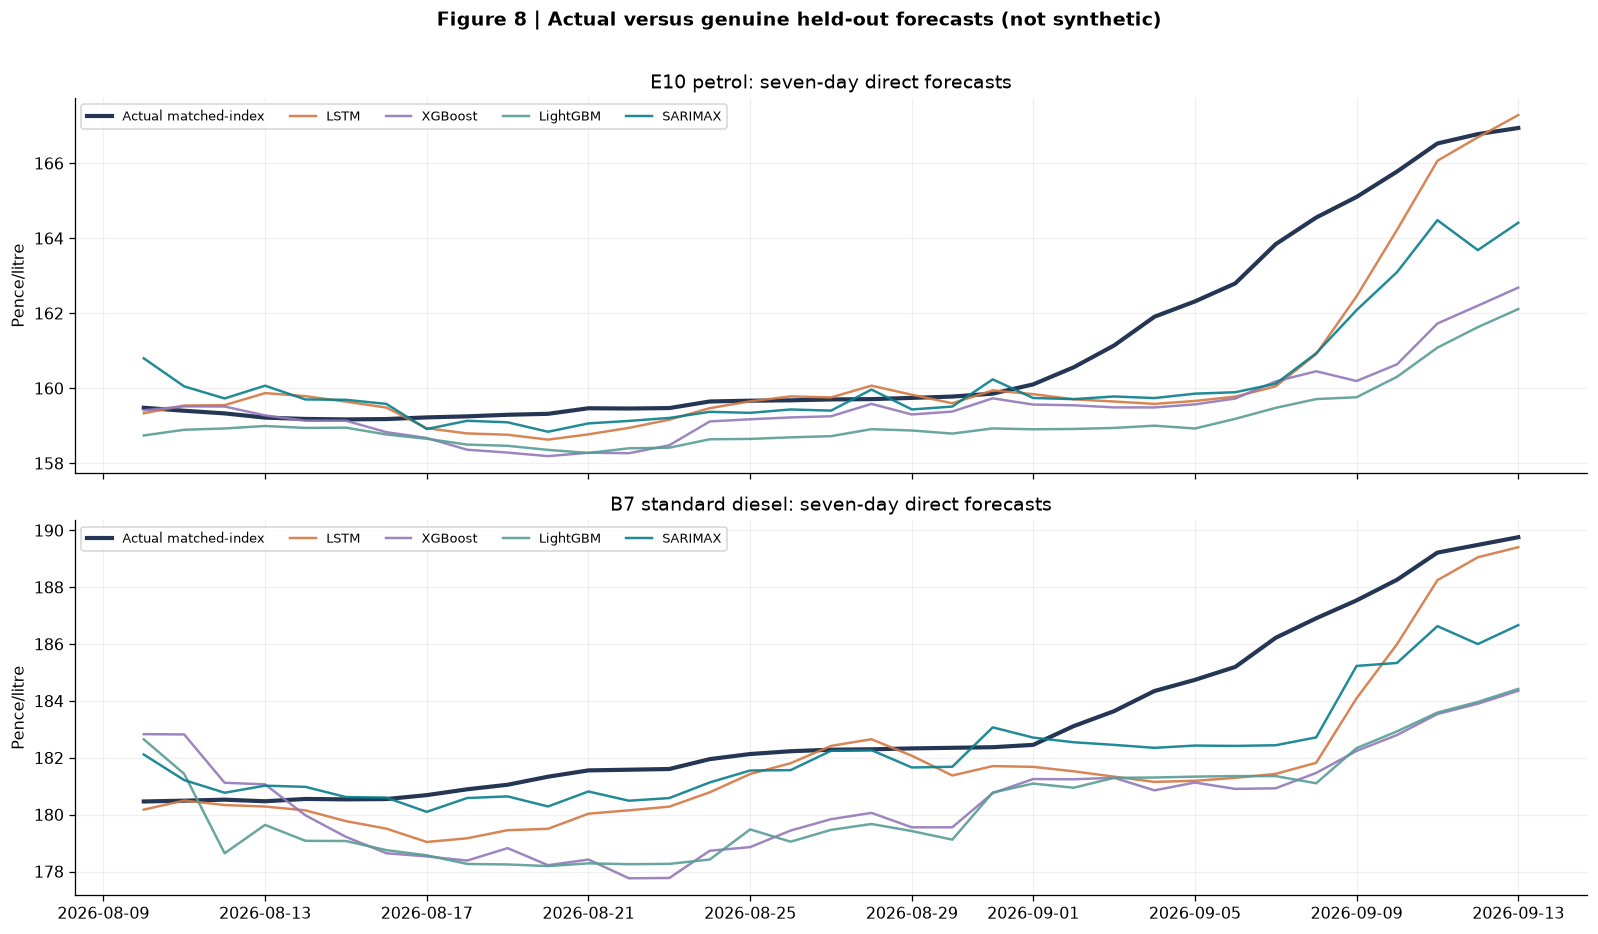

In [51]:
# Put all four model forecasts against the same observed seven-day targets.
fig,axs = plt.subplots(2,1,figsize=(14,8),sharex=True)

for fuel,ax in zip(FUELS,axs):
    z=test_preds[(test_preds.fuel_type==fuel)&(test_preds.horizon_days==7)]
    actual=z[z.model==CHAMPION].sort_values('target_date')
    ax.plot(actual.target_date,actual.actual,color='#243653',label='Actual matched-index',lw=2.6)
    for model,color in zip(MODELS,['#D47843','#9278B9','#579C95','#087F8C']):
        g=z[z.model==model].sort_values('target_date')
        ax.plot(g.target_date,g.prediction,color=color,lw=1.55,label=model,alpha=.9)
    ax.set(ylabel='Pence/litre',title=f'{LABELS[fuel]}: seven-day direct forecasts')
    ax.legend(ncol=5,fontsize=8,loc='upper left')

fig.suptitle('Figure 8 | Actual versus genuine held-out forecasts (not synthetic)',fontweight='bold',y=1.01)
fig.tight_layout();plt.show()

### 10.3. Examining residual distributions

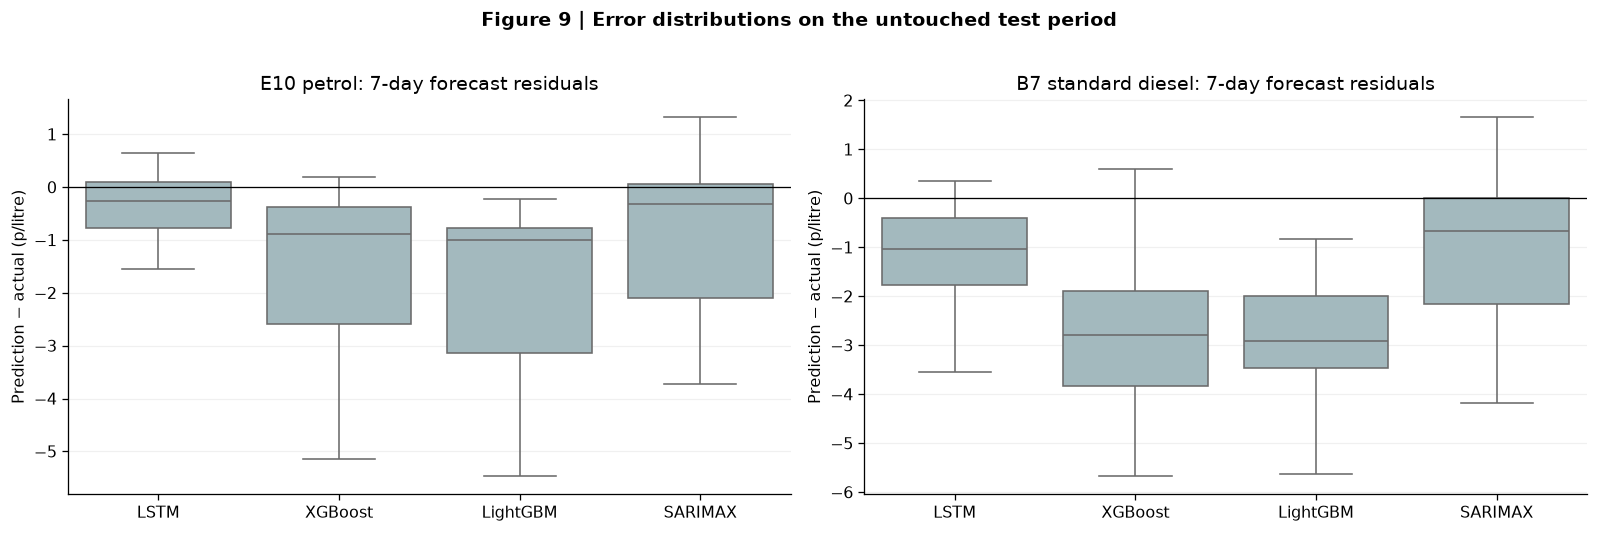

In [52]:
# Look for systematic overprediction or underprediction on the holdout period.

# Also report when another model beats the validation-selected choice for a specific task.
fig,axs=plt.subplots(1,2,figsize=(14,4.5))

for fuel,ax in zip(FUELS,axs):
    z=test_preds[(test_preds.fuel_type==fuel)&(test_preds.horizon_days==7)&test_preds.model.isin(MODELS)]
    sns.boxplot(x='model',y='error',data=z,order=MODELS,ax=ax,color='#9FBCC2',showfliers=False)
    ax.axhline(0,color='black',lw=.8);ax.set(title=f'{LABELS[fuel]}: 7-day forecast residuals',ylabel='Prediction − actual (p/litre)',xlabel='')
fig.suptitle('Figure 9 | Error distributions on the untouched test period',fontweight='bold',y=1.02);fig.tight_layout();plt.show()

### 10.4. Summarising the selected model against holdout winners

Display the validation-selected model beside the lowest-error model in each holdout task, without changing the original selection rule.

In [53]:
# A compact table by fuel × horizon for the validation-selected champion, alongside the test winner.

# Reporting the best test model as a diagnostic, without changing the chosen champion.
test_best=(test_scores[test_scores.model.isin(MODELS)].sort_values('MAE')
           .groupby(['fuel_type','horizon_days']).head(1)
           [['fuel_type','horizon_days','model','MAE']].rename(columns={'model':'lowest_test_MAE_model','MAE':'lowest_test_MAE'}))
selected_test=test_scores[test_scores.model==CHAMPION].merge(test_best,on=['fuel_type','horizon_days'])

display(selected_test[['fuel_type','horizon_days','model','MAE','RMSE','R2','lowest_test_MAE_model','lowest_test_MAE']].round(3))

,fuel_type,horizon_days,model,MAE,RMSE,R2,lowest_test_MAE_model,lowest_test_MAE
0,B7_STANDARD,1,SARIMAX,0.134,0.205,0.995,SARIMAX,0.134
1,B7_STANDARD,7,SARIMAX,1.273,1.725,0.628,SARIMAX,1.273
2,B7_STANDARD,14,SARIMAX,2.475,3.224,-0.334,SARIMAX,2.475
3,E10,1,SARIMAX,0.111,0.167,0.995,SARIMAX,0.111
4,E10,7,SARIMAX,1.141,1.608,0.587,LSTM,0.864
5,E10,14,SARIMAX,2.214,3.157,-0.455,SARIMAX,2.214


## 11. Adding Brent crude oil and GBP/USD from local files

This part uses the economic files stored beside the notebook.

- `DCOILBRENTEU.csv`: Brent crude oil price in **USD per barrel**.
- `DEXUSUK.csv`: exchange rate in **USD per GBP**.

The code checks the dates and converts Brent to GBP per barrel by dividing the dollar price by the USD/GBP rate. Missing market-day observations are retained in the raw series; the lagged feature step may use the last earlier available observation.

I have used an initial **21-calendar-day lag** for both factors, longer than the 14-day price horizon. This avoids using future-*dated* observations, although the CSV files do not tell us when every historical revision was published. Wholesale petrol/diesel prices, duty changes and VAT changes are **not** included in this particular experiment. The next results therefore address *Brent and FX forecasting value*, not their causal effect on pump prices.

### 11.1. Preparing offline economic inputs

Locate the existing Brent and exchange-rate CSVs and retain the 21-calendar-day lag used later for the external-factor comparison.

In [54]:
# Calendar days; larger than max forecasting horizon
MACRO_LAG = 21

# Loading the Datasets to the Notebook
BRENT_CSV = DATA_DIR/'DCOILBRENTEU.csv'
FX_CSV = DATA_DIR/'DEXUSUK.csv'

### 11.2. Parsing the local FRED files

Read date/value pairs, preserve missing market days and verify the required columns in each source.

In [55]:
# Parsing the FRED CSV layout and preserve missing trading/holiday observations.
def load_fred_local(path, value_column, output_column):
    if not path.is_file():
        raise FileNotFoundError(f'Missing {path.name}. Place it beside this notebook (DATA_DIR={DATA_DIR}).')
    f=pd.read_csv(path, low_memory=False)
    expected={'observation_date',value_column}
    
    if not expected.issubset(f.columns):
        raise ValueError(f'{path.name} requires columns {sorted(expected)}; found {f.columns.tolist()}')
    
    f = f[['observation_date',value_column]].copy()
    f['observation_date']=pd.to_datetime(f['observation_date'], errors='coerce')
    f[output_column]=pd.to_numeric(f[value_column],errors='coerce')
    f.loc[f[output_column]<=0,output_column]=np.nan
    f = f.dropna(subset=['observation_date']).sort_values('observation_date')
    f = f.drop_duplicates('observation_date',keep='last').rename(columns={'observation_date':'date'})
    f = f[['date',output_column]]
    
    print(f'{path.name}: {len(f):,} dated rows; '
          f'{f[output_column].notna().sum():,} valid numeric observations; '
          f'{f.date.min().date()} to {f.date.max().date()}')
    
    return f

### 11.3. Aligning Brent prices and exchange rates

Load the two observed economic series, convert Brent USD/barrel to GBP/barrel and retain the date range needed for lagged predictors.

In [56]:
# Aligning historical Brent and foreign-exchange observations
brent = load_fred_local(BRENT_CSV,'DCOILBRENTEU','brent_usd_bbl')
fx = load_fred_local(FX_CSV,'DEXUSUK','fx_usd_per_gbp')

# Combining the two observed economic series by date before engineering any lags.
macro = (brent.merge(fx,on='date',how='outer',validate='one_to_one')
       .sort_values('date').set_index('date'))
macro['brent_gbp_bbl']=macro['brent_usd_bbl']/macro['fx_usd_per_gbp']

# Restricting to the relevant vicinity for computation; preserve observations prior to study start for lags.
macro = macro.loc[(macro.index>=INDEX_START-pd.Timedelta(days=75)) &
                (macro.index<=INDEX_END)].copy()
assert (macro.index.is_unique and macro.index.is_monotonic_increasing)
assert macro[['brent_usd_bbl','fx_usd_per_gbp']].notna().sum().min()>=100, 'Insufficient macro history'

DCOILBRENTEU.csv: 10,295 dated rows; 9,122 valid numeric observations; 1987-05-20 to 2026-11-03
DEXUSUK.csv: 14,565 dated rows; 14,000 valid numeric observations; 1971-01-04 to 2026-10-30


### 11.4. Auditing the aligned economic histories

Summarise available observations and units. The downloaded CSVs are not treated as historical release-vintage archives.

In [57]:
# Auditing the date alignment and missing economic observations
print('Offline macro data loaded. No external API access was used.')
print('WARNING: historical values are NOT point-in-time release-vintage verified.')
macro_audit=pd.DataFrame({
    'Available numeric rows':macro.notna().sum(),
    'First valid date':[macro[col].first_valid_index().date() for col in macro.columns],
    'Last valid date':[macro[col].last_valid_index().date() for col in macro.columns],
    'Unit':['USD/barrel','USD/GBP','GBP/barrel']
},index=macro.columns)

display(macro_audit)
display(macro.loc[INDEX_START:INDEX_END].describe().round(3))

Offline macro data loaded. No external API access was used.


,Available numeric rows,First valid date,Last valid date,Unit
brent_usd_bbl,190,2025-12-10,2026-09-11,USD/barrel
fx_usd_per_gbp,190,2025-12-10,2026-09-11,USD/GBP
brent_gbp_bbl,185,2025-12-10,2026-09-11,GBP/barrel


,brent_usd_bbl,fx_usd_per_gbp,brent_gbp_bbl
count,140.000,141.000,137.000
mean,97.067,1.343,72.442
std,15.918,0.012,11.753
min,68.530,1.316,51.280
25%,86.605,1.336,64.561
50%,95.880,1.344,71.458
75%,109.232,1.352,81.568
max,138.210,1.365,104.388


### 11.5. Visualising the external economic series

Figure 10 shows Brent crude oil and the USD-per-GBP exchange rate over the fuel-index sample. These plots are descriptive only.

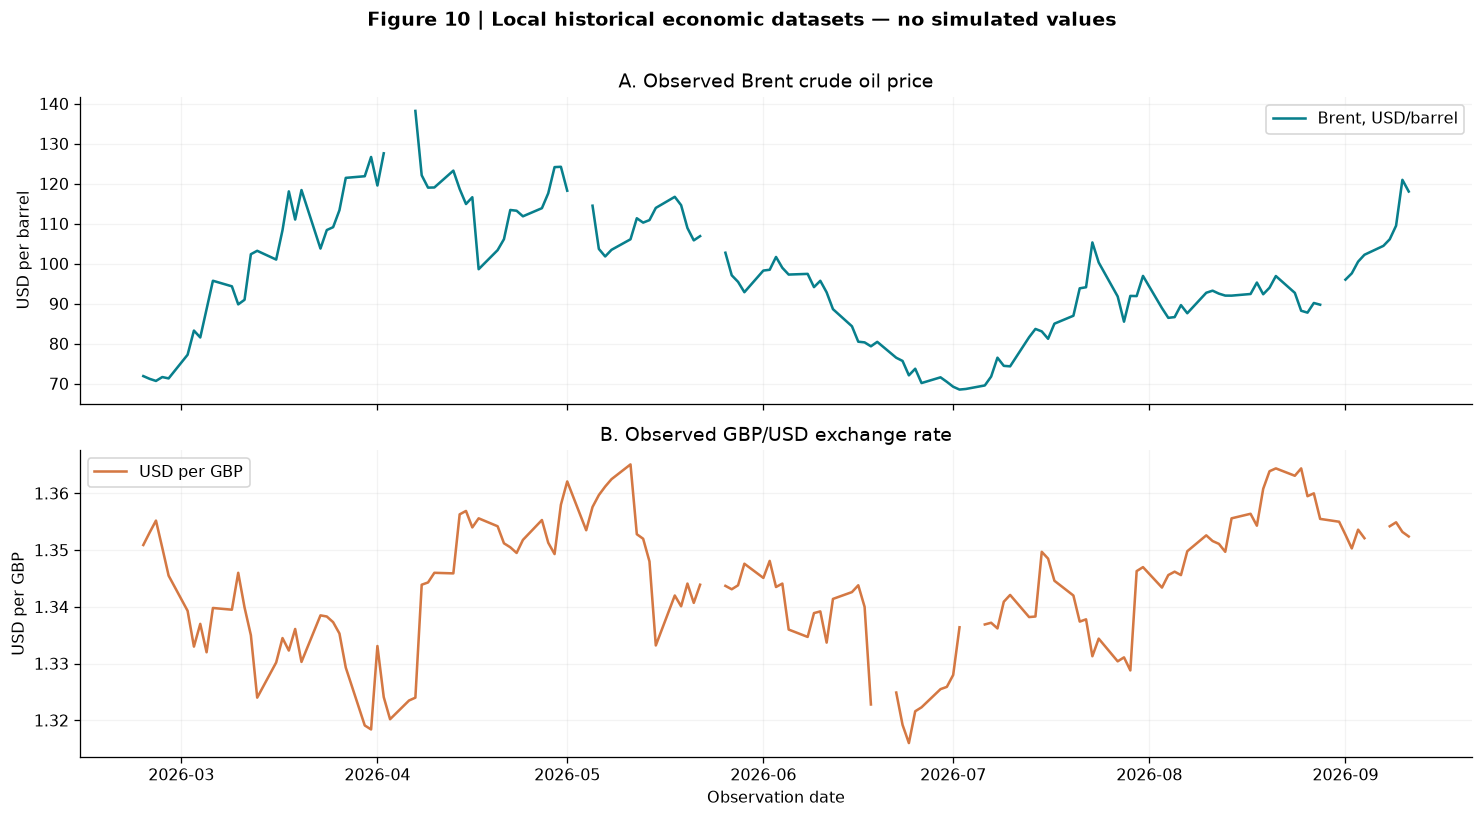

Missing business days/holidays remain absent in raw files; only past values are carried forward in feature construction.


In [58]:
# Plotting the observed oil-price and exchange-rate series over the fuel-data period.

# Restricting the display to the period covered by the fuel-price index.
plot_macro = macro.loc[INDEX_START:INDEX_END].copy()
fig,axes = plt.subplots(2, 1, figsize=(13,7), sharex=True)

axes[0].plot(plot_macro.index,plot_macro['brent_usd_bbl'], lw=1.6, color='#087F8C', label='Brent, USD/barrel')
axes[0].set(ylabel='USD per barrel', title='A. Observed Brent crude oil price')
axes[1].plot(plot_macro.index,plot_macro['fx_usd_per_gbp'], lw=1.6, color='#D47843', label='USD per GBP')
axes[1].set(ylabel='USD per GBP', title='B. Observed GBP/USD exchange rate', xlabel='Observation date')

for ax in axes:ax.legend(loc='best');ax.grid(alpha=.15)
fig.suptitle('Figure 10 | Local historical economic datasets — no simulated values', fontweight='bold', y=1.01)
fig.tight_layout();plt.show()

# An unlagged Pearson correlation is descriptive only, NOT evidence of predictability or causation.
view = macro_lagged_features(macro,panel[panel.fuel_type=='E10'].date) if 'macro_lagged_features' in globals() else None
print('Missing business days/holidays remain absent in raw files; only past values are carried forward in feature construction.')

## 12. Compare SARIMAX with and without external inputs

The baseline and economic-factor versions are fitted on **matching training dates** and evaluated at the **same forecast origins**. At horizon \(h\), the economic value comes from no later than date \(t+h-21\), which precedes forecast origin \(t\) for the horizons used here. Any scaling is fitted on the relevant training block.

This extension is implemented for SARIMAX because it was selected on the current validation sample. If a different algorithm wins after new data are added, it would need a corresponding exogenous model; the notebook should not silently switch the selected family.


**12.1. Preparing Exogenous Economic Variables**

This function prepares the historical Brent crude oil and GBP/USD exchange-rate information for SARIMAX. A 21-day lag is applied to avoid using economic data that would not have been available at the forecast date. Missing weekends and holidays are handled using forward filling, limited to five consecutive calendar days.

In [59]:
def macro_lagged_features(macro, dates):

    # Selecting the two external economic variables.
    m = macro[
        ['brent_gbp_bbl', 'fx_usd_per_gbp']
    ].sort_index().copy()

    # Moving each requested date back by the specified lag.
    lagged_dates = (
        pd.DatetimeIndex(dates)
        - pd.Timedelta(days=MACRO_LAG)
    )

    # Creating a continuous daily calendar.
    daily_index = pd.date_range(
        m.index.min(),
        max(m.index.max(), lagged_dates.max()),
        freq='D'
    )

    # Carryign forward previous observations, without filling values from future dates.
    full = m.reindex(daily_index).ffill(limit=5)

    # Matching the lagged economic observations to the original forecasting dates.
    feat = full.reindex(lagged_dates)

    feat.index = pd.DatetimeIndex(dates)

    # Name the features used during model training.
    feat.columns = [
        'brent_gbp_21day_lag',
        'usd_per_gbp_21day_lag'
    ]

    return feat


**12.2. SARIMAX with Exogenous Variables**

Compare the original SARIMAX model with a second version that includes Brent crude oil and GBP/USD information. Both models use the same training and evaluation dates. This allows us to investigate whether external economic factors provide additional forecasting value.


In [60]:
def sarimax_exog_pair(s, macro, h, cutoff, origins):

    # Preparing and aligning the economic features

    Xall = macro_lagged_features(macro, s.index)

    # Identifying dates with complete external information.
    allowed = Xall.notna().all(axis=1)

    first_date = (
        allowed[allowed].index.min()
        if allowed.any()
        else None
    )

    if first_date is None:
        raise ValueError(
            'No verified macro overlap with the fuel sample.'
        )

    start = max(first_date, s.index.min())

    # Selecting historical observations available up to the training cutoff.
    train = s.loc[start:cutoff]
    ex_train = Xall.loc[train.index]

    if len(train) < 50 or not ex_train.notna().all().all():
        raise ValueError(
            'Insufficient complete lagged macro history '
            'before validation cutoff'
        )

    # Standardizing the economic variables
    scale = StandardScaler().fit(ex_train)

    Xtr = pd.DataFrame(
        scale.transform(ex_train),
        index=train.index,
        columns=ex_train.columns
    )

    # Fitting the two SARIMAX specifications
    with warnings.catch_warnings():

        warnings.simplefilter('ignore')

        # Baseline: historical fuel prices only.
        base = SARIMAX(
            train,
            order=(1, 1, 0),
            trend='n',
            enforce_stationarity=False
        ).fit(
            disp=False,
            maxiter=70
        )

        # Extended model: fuel prices and economic factors.
        exfit = SARIMAX(
            train,
            exog=Xtr,
            order=(1, 1, 0),
            trend='n',
            enforce_stationarity=False
        ).fit(
            disp=False,
            maxiter=70
        )

    rows = []

    # Generating forecasts at each evaluation date
    for origin in origins:

        # Use the available fuel-price history.
        hist = s.loc[start:origin]

        # Identify the dates being forecast.
        future_dates = pd.date_range(
            origin + pd.Timedelta(days=1),
            periods=h,
            freq='D'
        )

        # Preparing past and forecast-period economic features.
        hX = Xall.loc[hist.index]
        fX = macro_lagged_features(macro, future_dates)

        # Skipping observations with incomplete economic inputs.
        if hX.isna().any().any() or fX.isna().any().any():
            continue

        # Applying the original training-data scaling.
        histX = pd.DataFrame(
            scale.transform(hX),
            index=hist.index,
            columns=hX.columns
        )

        futX = pd.DataFrame(
            scale.transform(fX),
            index=future_dates,
            columns=fX.columns
        )

        # Forecasting using both models
        with warnings.catch_warnings():

            warnings.simplefilter('ignore')

            # Updating the baseline model's state using the available observations.
            base_state = SARIMAX(
                hist,
                order=(1, 1, 0),
                trend='n',
                enforce_stationarity=False
            ).filter(base.params)

            # Updating the model containing economic features.
            ex_state = SARIMAX(
                hist,
                exog=histX,
                order=(1, 1, 0),
                trend='n',
                enforce_stationarity=False
            ).filter(exfit.params)

            # Generating forecasts for the specified horizon.
            p0 = float(
                base_state.forecast(h).iloc[-1]
            )

            p1 = float(
                ex_state.forecast(
                    h,
                    exog=futX
                ).iloc[-1]
            )

        # Storing the actual and predicted prices
        target_date = origin + pd.Timedelta(days=h)

        actual = float(s.loc[target_date])

        rows.extend([
            {
                'origin_date': origin,
                'target_date': target_date,
                'actual': actual,
                'prediction': p0,
                'model': 'SARIMAX matched baseline'
            },
            {
                'origin_date': origin,
                'target_date': target_date,
                'actual': actual,
                'prediction': p1,
                'model': 'SARIMAX + Brent/FX'
            }
        ])

    return rows


**12.3. Exogenous Model Evaluation**

Evaluate SARIMAX with and without external economic factors for E10 petrol and B7 standard diesel.

Forecasting horizons: 1 day, 7 days and 14 days. Three chronological validation periods are followed by a separate final holdout test. The experiment proceeds only if SARIMAX was selected as the best model during the earlier validation stage.

In [61]:
exog_rows = []

exog_status = (
    'Not run: real dated macroeconomic data unavailable.'
)

# Checking whether the experiment can proceed
if macro is not None and CHAMPION == 'SARIMAX':

    try:

        # Evaluating each fuel type independently.
        for fuel in FUELS:

            s, X = series_features[fuel]

            # Testing the existing forecasting horizons.
            for h in HORIZONS:

                # Chronological validation
                for i, start in enumerate(VAL_STARTS, 1):

                    cutoff = start - pd.Timedelta(days=1)

                    origins = pd.date_range(
                        start,
                        periods=14
                    )

                    chunk = sarimax_exog_pair(
                        s,
                        macro,
                        h,
                        cutoff,
                        origins
                    )

                    # Record the fuel, horizon and
                    # validation period for each prediction.
                    for r in chunk:

                        r.update(
                            fuel_type=fuel,
                            horizon_days=h,
                            split=f'Validation {i}'
                        )

                    exog_rows.extend(chunk)

                # Final holdout evaluation
                test_cutoff = (
                    TEST_START - pd.Timedelta(days=1)
                )

                test_origins = pd.date_range(
                    TEST_START,
                    INDEX_END - pd.Timedelta(days=h)
                )

                chunk = sarimax_exog_pair(
                    s,
                    macro,
                    h,
                    test_cutoff,
                    test_origins
                )

                for r in chunk:

                    r.update(
                        fuel_type=fuel,
                        horizon_days=h,
                        split='Test'
                    )

                exog_rows.extend(chunk)

        # Reporting successful completion
        exog_status = (
            'Completed paired real-data experiment: '
            f'{len(exog_rows)} predictions.'
        )

    except Exception as err:

        exog_rows = []

        exog_status = (
            f'Exogenous stage not run: '
            f'{type(err).__name__}: {err}'
        )

# SARIMAX-X is not treated as an extension of a different model if another algorithm wins the validation comparison.
elif CHAMPION != 'SARIMAX':

    exog_status = (
        f'Validation chose {CHAMPION}. '
        'SARIMAX-X is not presented as an extension '
        'of a different winner.'
    )

print(exog_status)


Completed paired real-data experiment: 920 predictions.



**12.4. Model Performance Evaluation**

Evaluate the original SARIMAX model and the version incorporating Brent crude oil and GBP/USD exchange rates.

Both models are compared using the same forecasting dates.

MAE  - Average magnitude of prediction errors.
RMSE - Penalises larger forecasting errors more heavily.
R²   - Measures predictive fit relative to the sample mean.

In [62]:
if exog_rows:

    # Converting the stored predictions into a DataFrame.
    exog_predictions = pd.DataFrame(exog_rows)

    # Calculating the evaluation metrics separately for each fuel type, forecasting horizon and split.
    exog_scores = (
        exog_predictions
        .groupby([
            'fuel_type',
            'horizon_days',
            'split',
            'model'
        ])
        .apply(
            lambda g: pd.Series({
                'n': len(g),

                'MAE': mean_absolute_error(
                    g.actual,
                    g.prediction
                ),

                'RMSE': np.sqrt(
                    mean_squared_error(
                        g.actual,
                        g.prediction
                    )
                ),

                'R2': r2_score(
                    g.actual,
                    g.prediction
                )
            }),
            include_groups=False
        )
        .reset_index()
    )

    # Displaying the numerical performance comparison.
    display(
        Markdown(
            '### SARIMAX Model Performance Comparison'
        )
    )

    display(exog_scores.round(3))

else:

    exog_predictions = pd.DataFrame()
    exog_scores = pd.DataFrame()

    display(
        Markdown(
            '**Exogenous model evaluation unavailable.** '
            'The required paired forecasts have not been generated.'
        )
    )

### SARIMAX Model Performance Comparison

,fuel_type,horizon_days,split,model,n,MAE,RMSE,R2
0,B7_STANDARD,1,Test,SARIMAX + Brent/FX,41.0,0.138,0.206,0.995
1,B7_STANDARD,1,Test,SARIMAX matched baseline,41.0,0.134,0.205,0.995
2,B7_STANDARD,1,Validation 1,SARIMAX + Brent/FX,14.0,0.228,0.319,0.978
3,B7_STANDARD,1,Validation 1,SARIMAX matched baseline,14.0,0.239,0.315,0.979
4,B7_STANDARD,1,Validation 2,SARIMAX + Brent/FX,14.0,0.143,0.208,0.982
5,B7_STANDARD,1,Validation 2,SARIMAX matched baseline,14.0,0.150,0.210,0.982
6,B7_STANDARD,1,Validation 3,SARIMAX + Brent/FX,14.0,0.467,0.600,0.971
7,B7_STANDARD,1,Validation 3,SARIMAX matched baseline,14.0,0.456,0.591,0.972
8,B7_STANDARD,7,Test,SARIMAX + Brent/FX,35.0,1.281,1.719,0.631
9,B7_STANDARD,7,Test,SARIMAX matched baseline,35.0,1.273,1.725,0.628


**12.5. Impact of Exogenous Economic Factors**

Compare forecasting errors between the two SARIMAX models. The objective is to identify whether introducing Brent and GBP/USD information improves predictive performance.

Positive MAE/RMSE reduction = improvement.
Positive R² difference      = improvement.

In [63]:
if not exog_scores.empty:

    # Arranging the model results side by side.
    comparative = (
        exog_scores
        .pivot_table(
            index=[
                'fuel_type',
                'horizon_days',
                'split'
            ],
            columns='model',
            values=['MAE', 'RMSE', 'R2']
        )
        .sort_index()
    )

    # Creating a separate table to store the differences.
    delta = pd.DataFrame(
        index=comparative.index
    )

    # Calculating the reduction in forecasting errors.
    for metric in ['MAE', 'RMSE']:

        delta[
            f'{metric} reduction from adding Brent/FX'
        ] = (
            comparative[
                (metric, 'SARIMAX matched baseline')
            ]
            -
            comparative[
                (metric, 'SARIMAX + Brent/FX')
            ]
        )

    # Calculating the difference in R² performance.
    delta[
        'R2 improvement from adding Brent/FX'
    ] = (
        comparative[
            ('R2', 'SARIMAX + Brent/FX')
        ]
        -
        comparative[
            ('R2', 'SARIMAX matched baseline')
        ]
    )

    # Displaying the comparative results.
    display(
        Markdown(
            '### Incremental Impact of Brent and GBP/USD'
        )
    )

    display(delta.round(3))

    print(
        'Positive MAE/RMSE reduction indicates lower '
        'forecasting error after adding external factors.'
    )

    print(
        'Positive R² improvement indicates better '
        'predictive performance.'
    )

else:

    print(
        'Performance scores are unavailable. '
        'Run Section 12.4 first.'
    )

### Incremental Impact of Brent and GBP/USD

MAE reduction from adding Brent/FX  \
fuel_type   horizon_days split                                              
B7_STANDARD 1            Test                                      -0.005   
                         Validation 1                               0.011   
                         Validation 2                               0.007   
                         Validation 3                              -0.011   
            7            Test                                      -0.008   
                         Validation 1                               0.053   
                         Validation 2                              -0.014   
                         Validation 3                               0.045   
            14           Test                                       0.024   
                         Validation 1                               0.116   
                         Validation 2                              -0.036   
                         Validation 3                               0.133   
E10         1            Test                                      -0.005   
                         Validation 1                               0.007   
                         Validation 2                              -0.006   
                         Validation 3                              -0.008   
            7            Test                                       0.003   
                         Validation 1                               0.043   
                         Validation 2                              -0.069   
                         Validation 3                               0.042   
            14           Test                                       0.024   
                         Validation 1                               0.096   
                         Validation 2                              -0.136   
                         Validation 3                               0.098   

                                       RMSE reduction from adding Brent/FX  \
fuel_type   horizon_days split                                               
B7_STANDARD 1            Test                                       -0.002   
                         Validation 1                               -0.005   
                         Validation 2                                0.001   
                         Validation 3                               -0.008   
            7            Test                                        0.005   
                         Validation 1                                0.036   
                         Validation 2                               -0.032   
                         Validation 3                                0.044   
            14           Test                                        0.027   
                         Validation 1                                0.110   
                         Validation 2                               -0.109   
                         Validation 3                                0.117   
E10         1            Test                                       -0.002   
                         Validation 1                               -0.013   
                         Validation 2                               -0.004   
                         Validation 3                               -0.006   
            7            Test                                        0.007   
                         Validation 1                                0.020   
                         Validation 2                               -0.078   
                         Validation 3                                0.043   
            14           Test                                        0.030   
                         Validation 1                                0.085   
                         Validation 2                               -0.147   
                         Validation 3                                0.107   

       

Positive MAE/RMSE reduction indicates lower forecasting error after adding external factors.
Positive R² improvement indicates better predictive performance.


**12.6. Comparative Forecasting Accuracy**

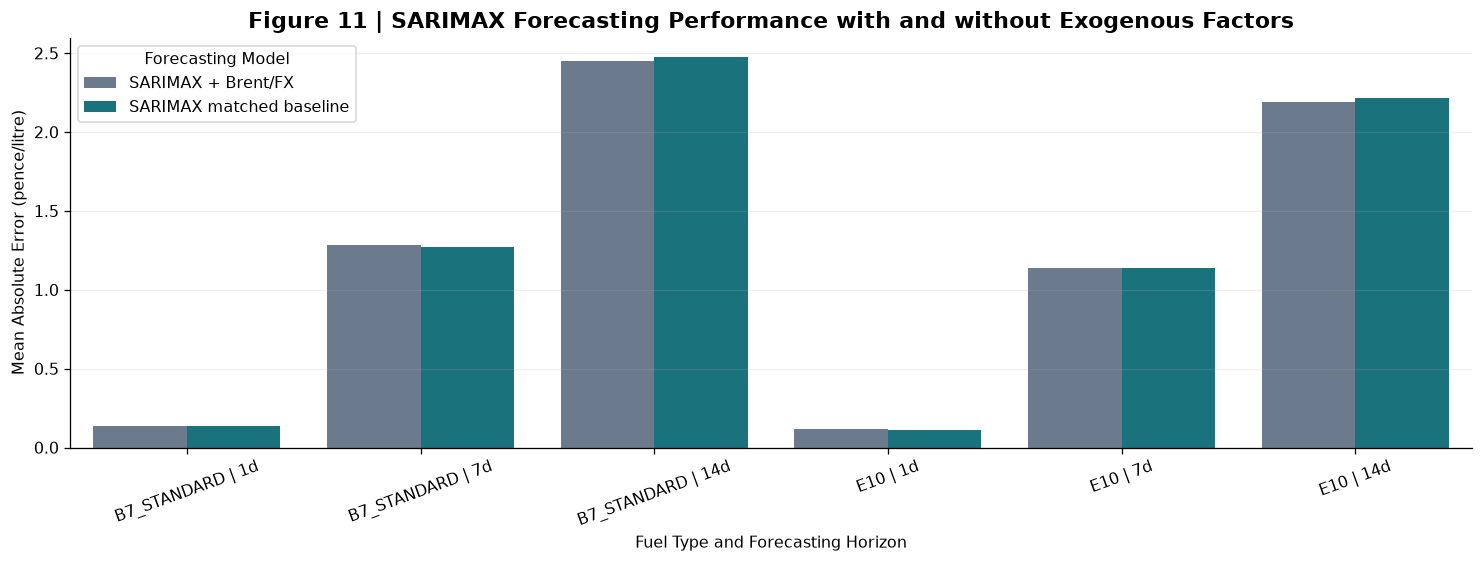

In [64]:
# Visualizing the forecasting accuracy of SARIMAX with and without external economic variables.
if not exog_scores.empty:

    # Selecting results from the final test period.
    selected = exog_scores[
        exog_scores['split'] == 'Test'
    ].copy()

    # Creating labels for each fuel and forecast horizon.
    selected['task'] = (
        selected['fuel_type']
        + ' | '
        + selected['horizon_days'].astype(str)
        + 'd'
    )

    # Plotting the forecasting errors side by side.
    fig, ax = plt.subplots(
        figsize=(13, 5)
    )

    sns.barplot(
        data=selected,
        x='task',
        y='MAE',
        hue='model',
        ax=ax,
        palette=['#667A91', '#087F8C']
    )

    # Formatting the figure for easier interpretation.
    ax.set_title(
        'Figure 11 | SARIMAX Forecasting Performance '
        'with and without Exogenous Factors',
        fontsize=14,
        fontweight='bold'
    )

    ax.set_ylabel(
        'Mean Absolute Error (pence/litre)'
    )

    ax.set_xlabel(
        'Fuel Type and Forecasting Horizon'
    )

    ax.grid(
        axis='y',
        alpha=0.2
    )

    ax.legend(
        title='Forecasting Model'
    )

    plt.xticks(rotation=20)

    fig.tight_layout()
    plt.show()

else:

    print(
        'No forecasting results available for visualisation.'
    )

**12.7. Actual vs Predicted Fuel Prices**

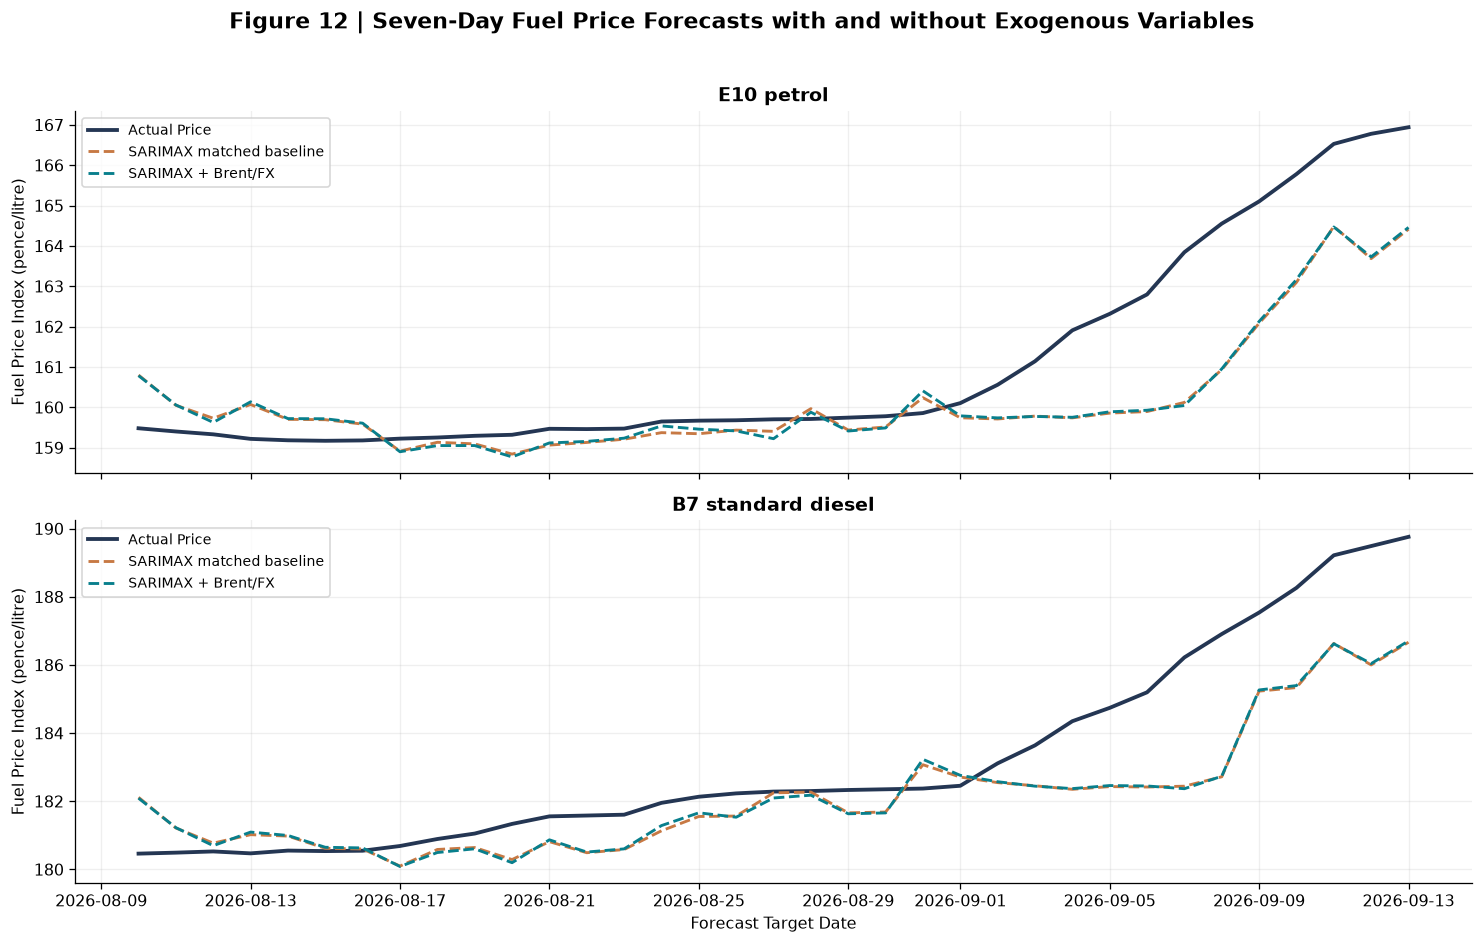

In [65]:

# Compare the observed fuel-price index with predictions generated by SARIMAX and SARIMAX + Brent/FX.
if not exog_predictions.empty:

    # Creating separate graphs for petrol and diesel.
    fig, axes = plt.subplots(
        2, 1,
        figsize=(13, 8),
        sharex=True
    )

    for fuel, ax in zip(FUELS, axes):

        # Selecting seven-day final holdout predictions.
        fuel_data = exog_predictions[
            (exog_predictions['fuel_type'] == fuel) &
            (exog_predictions['horizon_days'] == 7) &
            (exog_predictions['split'] == 'Test')
        ].copy()

        fuel_data['target_date'] = pd.to_datetime(
            fuel_data['target_date']
        )

        fuel_data = fuel_data.sort_values(
            'target_date'
        )

        if fuel_data.empty:
            ax.set_title(
                f'{LABELS[fuel]} - No test predictions'
            )
            continue

        # Plotting the actual observed fuel prices once.
        actual_data = fuel_data[
            fuel_data['model'] == 'SARIMAX + Brent/FX'
        ]

        ax.plot(
            actual_data['target_date'],
            actual_data['actual'],
            linewidth=2.4,
            color='#243653',
            label='Actual Price'
        )

        # Plotting both SARIMAX variants.
        model_colours = {
            'SARIMAX matched baseline': '#C77944',
            'SARIMAX + Brent/FX': '#087F8C'
        }

        for model_name, colour in model_colours.items():

            model_data = fuel_data[
                fuel_data['model'] == model_name
            ]

            ax.plot(
                model_data['target_date'],
                model_data['prediction'],
                linewidth=1.8,
                linestyle='--',
                color=colour,
                label=model_name
            )

        # Formatting the graphs consistently.
        ax.set_title(
            LABELS[fuel],
            fontsize=12,
            fontweight='bold'
        )

        ax.set_ylabel(
            'Fuel Price Index (pence/litre)'
        )

        ax.grid(alpha=0.2)
        ax.legend(fontsize=9)

    axes[-1].set_xlabel(
        'Forecast Target Date'
    )

    fig.suptitle(
        'Figure 12 | Seven-Day Fuel Price Forecasts '
        'with and without Exogenous Variables',
        fontsize=14,
        fontweight='bold',
        y=1.02
    )

    fig.tight_layout()
    plt.show()

else:

    print(
        'No exogenous model predictions available.'
    )

## 13. Make forecasts from the historical dataset endpoint

The daily index stops at **13 September 2026**, where reporting is more complete than in the last raw export days. The forecasts here are anchored to **that historical date**. They are not today's fuel-price forecasts. Results from the exogenous version are shown as a comparison even if the earlier experiment did not show a reliable benefit.

In [66]:
# Generating forecasts from the last complete historical date in this dataset. These are examples anchored in September 2026, not live predictions for today.

# One-off historical as-of baseline projections. These do not use actual future target prices.
projection_rows=[]
if CHAMPION=='SARIMAX':
    for fuel in FUELS:
        s,X=series_features[fuel]
        for h in HORIZONS:
            
            # A single 1/7/14-day forecast from the final *complete* index date
            with warnings.catch_warnings():
                warnings.simplefilter('ignore')
                fitted=SARIMAX(s,order=(1,1,0),trend='n',enforce_stationarity=False).fit(disp=False,maxiter=70)
            pred=float(fitted.forecast(steps=h).iloc[-1])
            projection_rows.append({'fuel':LABELS[fuel], 'as_of_date':INDEX_END.date(),
                'forecast_date':(INDEX_END+pd.Timedelta(days=h)).date(),
                'horizon_days':h,'predicted_matched_station_index_ppl':pred,
                'model':CHAMPION})
    projections=pd.DataFrame(projection_rows)
    
    display(projections.round(3))

else:
    display(Markdown(f'Historical endpoint forecast helper currently shown for SARIMAX. Validation chose **{CHAMPION}**; do not silently replace it.'))

,fuel,as_of_date,forecast_date,horizon_days,predicted_matched_station_index_ppl,model
0,E10 petrol,2026-09-13,2026-09-14,1,167.076,SARIMAX
1,E10 petrol,2026-09-13,2026-09-20,7,167.506,SARIMAX
2,E10 petrol,2026-09-13,2026-09-27,14,167.651,SARIMAX
3,B7 standard diesel,2026-09-13,2026-09-14,1,189.979,SARIMAX
4,B7 standard diesel,2026-09-13,2026-09-20,7,190.636,SARIMAX
5,B7 standard diesel,2026-09-13,2026-09-27,14,190.829,SARIMAX


### 13.1. Compare the historical SARIMAX forecast paths

This figure refits the baseline and economic-factor SARIMAX models using observations through **13 September 2026**, then projects the following 14 days. It is a demonstration from a past information cutoff, not a live price outlook. The lagged macro predictors are taken from information dated before that cutoff, rather than from unknown future oil or currency prices.

**Historical fuel-price forecasting**

In [67]:
# Generating 14-day forecasts using the SARIMAX baseline and SARIMAX with Brent crude oil and GBP/USD.
hist_forecasts = []

# Define the forecast period based on the final observation available in the fuel-price dataset.
forecast_dates = pd.date_range(
    INDEX_END + pd.Timedelta(days=1),
    periods=14,
    freq='D'
)

# Initializing the results table.
asof_predictions = pd.DataFrame()

# Continuing only if SARIMAX was selected during validation and the historical economic data are available.
if CHAMPION == 'SARIMAX' and macro is not None:

    # Forecasting petrol and diesel separately.
    for fuel in FUELS:

        # Retrieving the reconstructed historical price index.
        s, _ = series_features[fuel]

        # Preparing lagged Brent and GBP/USD observatin for both the historical and forecast dates.
        Xhistorical = macro_lagged_features(
            macro,
            s.index
        )

        Xfuture = macro_lagged_features(
            macro,
            forecast_dates
        )

        # Skipping the fuel type if the required historical economic information is incomplete.
        if (
            Xhistorical.isna().any().any()
            or Xfuture.isna().any().any()
        ):
            print(
                'Missing lagged macro covariates; '
                'skip historical projection for',
                fuel
            )
            continue

        # Standardizing the economic variables using the historical observations only.
        xscaler = StandardScaler().fit(Xhistorical)

        xh = pd.DataFrame(
            xscaler.transform(Xhistorical),
            index=s.index,
            columns=Xhistorical.columns
        )

        xf = pd.DataFrame(
            xscaler.transform(Xfuture),
            index=forecast_dates,
            columns=Xfuture.columns
        )

        # Fitting the two SARIMAX specifications (Both use the same ARIMA(1,1,0) structure)
        with warnings.catch_warnings():

            warnings.simplefilter('ignore')

            # Model 1: Fuel-price history only.
            model_base = SARIMAX(
                s,
                order=(1, 1, 0),
                trend='n',
                enforce_stationarity=False
            ).fit(
                disp=False,
                maxiter=80
            )

            # Model 2: Historical fuel prices together with lagged Brent and exchange-rate inputs.
            model_ex = SARIMAX(
                s,
                exog=xh,
                order=(1, 1, 0),
                trend='n',
                enforce_stationarity=False
            ).fit(
                disp=False,
                maxiter=80
            )

            # Generating the next 14 daily forecasts.
            pb = model_base.forecast(14)

            px = model_ex.forecast(
                14,
                exog=xf
            )

        # Storing predictions from both models so they can be compared in the following sections.
        for d, a, b in zip(forecast_dates, pb, px):

            hist_forecasts.append({
                'fuel_type': fuel,
                'forecast_date': d,
                'as_of_date': INDEX_END,
                'horizon_days': (d - INDEX_END).days,
                'SARIMAX baseline': float(a),
                'SARIMAX + Brent/FX': float(b)
            })

    # Converting the generated forecasts into a DataFrame.
    asof_predictions = pd.DataFrame(hist_forecasts)

    print(
        f'Forecasting completed: '
        f'{len(asof_predictions)} model comparison rows.'
    )

else:

    print(
        'Forecasting requires SARIMAX to be the selected '
        'model and valid historical macroeconomic data.'
    )

Forecasting completed: 28 model comparison rows.


**13.2. Displaying the Fuel-Price Forecasts**

In [68]:
# Display the forecasts generated by both SARIMAX models.
if not asof_predictions.empty:

    # Selecting the three forecasting horizons used throughout the model-comparison experiments.
    forecast_summary = asof_predictions[
        asof_predictions['horizon_days'].isin(HORIZONS)
    ].copy()

    # Arranging the results by fuel type and horizon.
    forecast_summary = forecast_summary.sort_values(
        ['fuel_type', 'horizon_days']
    )

    display(
        Markdown(
            '### Fuel-Price Forecasts: '
            'SARIMAX vs SARIMAX + Brent/FX'
        )
    )

    display(
        forecast_summary.round({'SARIMAX baseline': 3, 'SARIMAX + Brent/FX': 3})
    )

### Fuel-Price Forecasts: SARIMAX vs SARIMAX + Brent/FX

,fuel_type,forecast_date,as_of_date,horizon_days,SARIMAX baseline,SARIMAX + Brent/FX
14,B7_STANDARD,2026-09-14,2026-09-13,1,189.979,189.965
20,B7_STANDARD,2026-09-20,2026-09-13,7,190.636,190.595
27,B7_STANDARD,2026-09-27,2026-09-13,14,190.829,190.815
0,E10,2026-09-14,2026-09-13,1,167.076,167.061
6,E10,2026-09-20,2026-09-13,7,167.506,167.466
13,E10,2026-09-27,2026-09-13,14,167.651,167.639


**13.3. Visualising Future Fuel-Price Forecasts**

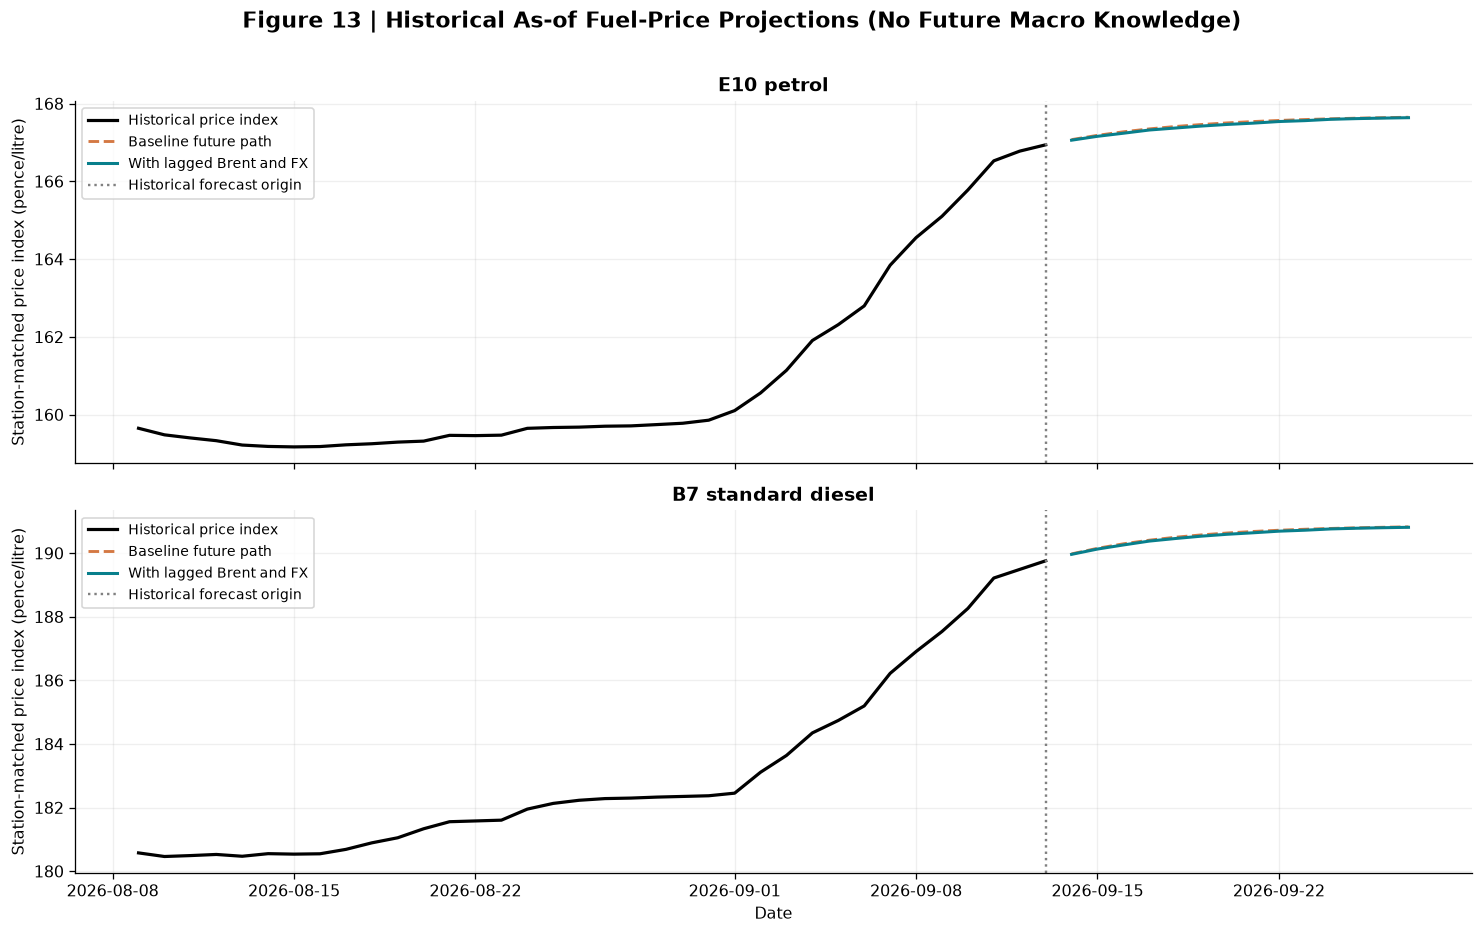

In [69]:
if not asof_predictions.empty:

    # Creating separate panels for petrol and diesel.
    fig, axes = plt.subplots(
        2, 1,
        figsize=(13, 8),
        sharex=True
    )

    for ax, fuel in zip(axes, FUELS):

        # Retrieving the historical price index.
        s, _ = series_features[fuel]

        # Selecting forecasts for the current fuel type.
        z = asof_predictions[
            asof_predictions['fuel_type'] == fuel
        ].copy()

        if z.empty:
            ax.set_title(
                f'{LABELS[fuel]} - No forecast available'
            )
            continue

        z = z.sort_values('forecast_date')

        # Plotting the observed price index for the 35 days preceding the forecast origin.
        historical_prices = s.loc[
            INDEX_END - pd.Timedelta(days=35):
        ]

        ax.plot(
            historical_prices.index,
            historical_prices.values,
            color='black',
            linewidth=2,
            label='Historical price index'
        )

        # Plotting the baseline SARIMAX predictions.
        ax.plot(
            z['forecast_date'],
            z['SARIMAX baseline'],
            linewidth=1.8,
            linestyle='--',
            color='#D47843',
            label='Baseline future path'
        )

        # Plotting forecasts incorporating the lagged
        # Brent crude oil and GBP/USD variables.
        ax.plot(
            z['forecast_date'],
            z['SARIMAX + Brent/FX'],
            linewidth=1.9,
            color='#087F8C',
            label='With lagged Brent and FX'
        )

        # Separatting observed data from future forecasts.
        ax.axvline(
            INDEX_END,
            color='gray',
            linestyle=':',
            linewidth=1.5,
            label='Historical forecast origin'
        )

        # Formatting each fuel-type comparison.
        ax.set_title(
            LABELS[fuel],
            fontsize=12,
            fontweight='bold'
        )

        ax.set_ylabel(
            'Station-matched price index (pence/litre)'
        )

        ax.grid(alpha=0.2)
        ax.legend(fontsize=9)

    # Displaying the forecast origin in the overall title.
    fig.suptitle(
        'Figure 13 | Historical As-of Fuel-Price Projections '
        '(No Future Macro Knowledge)',
        fontsize=14,
        fontweight='bold',
        y=1.01
    )

    axes[-1].set_xlabel('Date')

    fig.tight_layout()
    plt.show()


## 14. Main findings and limitations of the price-forecast experiment

The comparison uses real uploaded data, a clearly defined chain-linked station index and common chronological origins for all four models. The MAE, RMSE and R² tables are calculated before the validation-selected winner is chosen. The later holdout is then used to assess the decision. Results from adding Brent and exchange-rate information should be reported whether they improve performance or not.


## 15. Forecasting Future Fuel-Price Volatility

While the previous sections focused on predicting future fuel-price levels, this part of the research investigates whether the magnitude of short-term price fluctuations can also be forecast. Understanding these variations is particularly important during periods of economic uncertainty, when fuel prices may experience sudden increases or decreases.

The analysis examines the predictive value of historical price movements, station reporting activity and external economic indicators, particularly Brent crude oil prices and GBP/USD exchange rates. Using the reconstructed E10 petrol and B7 diesel price indices, future realised volatility is estimated over 7-day and 14-day forecasting horizons.

Four forecasting approaches—Persistence, Ridge Regression, XGBoost and LightGBM—are evaluated to determine how effectively they capture future price fluctuations. Their performance is assessed through chronological validation and holdout testing, followed by an investigation of whether incorporating exogenous economic information improves forecasting accuracy.

This extension builds upon the existing price-forecasting research without modifying its original models or results. The objective is to establish whether external economic factors provide additional predictive information about fuel-price volatility, beyond their contribution to forecasting price levels.



**15.1. Volatility Forecasting Configuration**

The earlier models predict future fuel-price levels. Here, the objective is to forecast the magnitude of daily price movements over the next 7 or 14 days.

Four models are considered:

1. Persistence - a simple historical volatility baseline.
2. Ridge - a regularised linear regression model.
3. XGBoost - gradient-boosted regression trees.
4. LightGBM - leaf-wise gradient boosting.

The economic variables retain the same historical availability lag used in the earlier forecasting analysis.

In [70]:
VOL_HORIZONS = [7, 14]

VOL_MODELS = [
    'Persistence',
    'Ridge',
    'XGBoost',
    'LightGBM'
]

VOL_MACRO_LAG = MACRO_LAG

# Storing the predictor names and prepared datasets.
VOL_FEAT_COLS = []
VOL_MACRO_COLS = []

vol_inputs = {}
vol_deltas = {}
vol_pairs = {}
vol_frames = {}


**15.2. Historical Volatility Feature Engineering**

Prepare historical features separately for E10 and B7.

The aim is to understand whether recent price changes, historical volatility and station reporting activity contain information about future price fluctuations.

Brent crude oil and GBP/USD variables are also included, using the historical lag already established.

No future price movements are included as predictors.

In [71]:
for fuel in FUELS:

    # Retrieving the historical fuel-price index
    z = (
        panel.loc[panel.fuel_type.eq(fuel)]
        .set_index('date')
        .sort_index()
    )

    price = (
        z['matched_price_index']
        .asfreq('D')
        .astype(float)
    )

    # Calculating the change in price between consecutive calendar days.
    delta = price.diff()

    # Creating a DataFrame to store the model features.
    X = pd.DataFrame(index=price.index)

    # Historical price movements
    X['price_level_t'] = price
    X['price_change_t'] = delta
    X['abs_change_t'] = delta.abs()

    # Include earlier price movements to capture short-term dependence in the series.
    for lag in [1, 2, 3, 7, 14]:

        X[f'change_lag{lag}'] = delta.shift(lag)


    # Historical volatility indicators

    # Rolling RMS measures the typical magnitude of daily price changes within a historical window.
    # Rolling standard deviation measures variability around the average historical price change.
    # These are different but complementary measures.

    for window in [7, 14, 28]:

        X[f'hist_rms_change_{window}d'] = (
            delta.pow(2)
            .rolling(window, min_periods=window)
            .mean()
            .pow(0.5)
        )

        X[f'hist_sd_change_{window}d'] = (
            delta
            .rolling(window, min_periods=window)
            .std(ddof=0)
        )

        X[f'hist_mean_change_{window}d'] = (
            delta
            .rolling(window, min_periods=window)
            .mean()
        )

    # Station reporting and price dispersion
    # These features help the model account for variation in available forecourt observations.

    X['active_stations_t'] = (
        z['active_stations'].reindex(price.index)
    )

    X['paired_stations_t'] = (
        z['paired_stations'].reindex(price.index)
    )

    X['spatial_dispersion_t'] = (
        z['spatial_std'].reindex(price.index)
    )

    X['paired_change_7d'] = (
        X['paired_stations_t'].diff(7)
    )

    # Calendar and time features
    # Sine and cosine represent the weekly calendar cycle without a discontinuity between Sunday and Monday.
    X['weekday_sin'] = np.sin(
        2 * np.pi * price.index.dayofweek / 7
    )

    X['weekday_cos'] = np.cos(
        2 * np.pi * price.index.dayofweek / 7
    )

    X['time_trend'] = np.arange(len(price))

    # Save the non-economic predictor names once.
    # Both fuel types use the same feature definitions.
    if not VOL_FEAT_COLS:
        VOL_FEAT_COLS = X.columns.tolist()

    # Step 6 - Adding historical economic information
    # Reuse the lagged Brent and exchange-rate function developed in the previous research section.
    macro_known = macro_lagged_features(
        macro,
        X.index
    )

    # Clearly identifying economic predictors.
    macro_known = macro_known.rename(
        columns={
            col: 'macro_' + col
            for col in macro_known.columns
        }
    )

    # Calculating changes in already lagged economic observations over the previous 7 and 14 days.
    for col in list(macro_known.columns):

        macro_known[col + '_change_7d'] = (
            macro_known[col].diff(7)
        )

        macro_known[col + '_change_14d'] = (
            macro_known[col].diff(14)
        )

    # Combining the historical fuel-price features with the lagged economic indicators.
    X = X.join(macro_known)

    # Storing the prepared information

    vol_inputs[fuel] = X
    vol_deltas[fuel] = delta

    vol_pairs[fuel] = (
        z['paired_stations'].reindex(price.index)
    )

# Identifying the economic predictor columns.
VOL_MACRO_COLS = [
    col
    for col in vol_inputs[FUELS[0]].columns
    if col.startswith('macro_')
]

print('Historical volatility features prepared.')

print(
    'Fuel-price predictors:',
    len(VOL_FEAT_COLS)
)

print(
    'Economic predictors:',
    len(VOL_MACRO_COLS)
)

Historical volatility features prepared.
Fuel-price predictors: 24
Economic predictors: 6


**15.3. Constructing Future Volatility Targets**

The forecasting target is the magnitude of future daily fuel-price movements.

We calculate three descriptive future measures:

1. RMS volatility - primary prediction target.
2. Standard deviation of future daily changes.
3. Mean absolute daily price change.

Future changes are used only to construct labels. They are not included in the forecasting inputs.

In [72]:
for fuel in FUELS:

    # Retrieve the historical features and daily changes.
    X = vol_inputs[fuel]
    delta = vol_deltas[fuel]
    paired_stations = vol_pairs[fuel]

    for h in VOL_HORIZONS:

        # Collecting future daily price changes
        # For each forecast origin, identify the following h daily changes.
        
        # These observations define what actually happened after the forecast origin.
        fut = pd.concat(
            [
                delta.shift(-j)
                for j in range(1, h + 1)
            ],
            axis=1
        )

        # Only calculating a target when every future daily change in the forecast window exists.
        complete = fut.notna().all(axis=1)

        # Creating a separate dataset for each horizon.
        sample = X.copy()

        # Calculating future realised RMS volatility
        # RMS measures the magnitude of movements regardless of whether prices rise or fall.
        sample['future_rms_volatility'] = (
            fut.pow(2)
            .mean(axis=1)
            .pow(0.5)
            .where(complete)
        )

        # Calculating supplementary target measures
        sample['future_sd_changes'] = (
            fut.std(axis=1, ddof=0)
            .where(complete)
        )

        sample['future_abs_mean_change'] = (
            fut.abs()
            .mean(axis=1)
            .where(complete)
        )

        # Recording forecast dates
        sample['origin_date'] = sample.index

        sample['target_end_date'] = (
            sample.index + pd.Timedelta(days=h)
        )

        # Examining the future reporting coverage
        # This records the minimum number of paired stations observed within the future window.
        
        # It is retained for coverage diagnostics, not as a predictor of future volatility.
        future_paired = pd.concat(
            [
                paired_stations.shift(-j)
                for j in range(1, h + 1)
            ],
            axis=1
        )

        sample['min_future_paired'] = (
            future_paired.min(axis=1)
            .where(complete)
        )

        # Identifying fuel type and forecasting horizon
        sample['fuel_type'] = fuel
        sample['horizon_days'] = h

        # Storing each fuel-horizon dataset independently.
        vol_frames[(fuel, h)] = sample

print(
    'Future volatility targets created for '
    'E10 petrol and B7 standard diesel.'
)

Future volatility targets created for E10 petrol and B7 standard diesel.



**15.4. Volatility Data Quality Assessment**

Checking how many observations can be used for forecasting.

A valid observation must contain:
- Complete historical price features.
- Complete lagged economic predictors.
- An observed future RMS-volatility target.

I have also reported the first and last eligible dates, together with the average future RMS volatility.

In [73]:
vol_audit = []

for (fuel, h), d in vol_frames.items():

    # Identifying complete forecasting observations
    required_columns = (
        VOL_FEAT_COLS
        + VOL_MACRO_COLS
        + ['future_rms_volatility']
    )

    usable = (
        d[required_columns]
        .notna()
        .all(axis=1)
    )

    # Summarizing the available observations
    vol_audit.append({

        'fuel': LABELS[fuel],
        'horizon': h,
        'total_days': len(d),
        'eligible_complete_origins': int(
            usable.sum()
        ),

        'first_eligible': (
            str(d.index[usable][0].date())
            if usable.any()
            else 'None'
        ),

        'last_eligible': (
            str(d.index[usable][-1].date())
            if usable.any()
            else 'None'
        ),

        'mean_future_rms': float(
            d['future_rms_volatility'].mean()
        )
    })

# Displaying the data availability summary
print(
    'Prospective RMS-change volatility, '
    'measured using daily price movements.'
)

print(
    'Future target values are never included '
    'among the forecasting predictors.'
)

display(
    pd.DataFrame(vol_audit).round(4)
)

# Confirming that sufficient data are available
# Preserve the existing minimum requirement of 90 complete observations per fuel-horizon dataset.
assert all(
    row['eligible_complete_origins'] >= 90
    for row in vol_audit
), 'Insufficient complete target/macroeconomic overlap.'

print(
    'Volatility data quality checks completed.'
)

Prospective RMS-change volatility, measured using daily price movements.
Future target values are never included among the forecasting predictors.


,fuel,horizon,total_days,eligible_complete_origins,first_eligible,last_eligible,mean_future_rms
0,E10 petrol,7,203,168,2026-03-23,2026-09-06,0.3207
1,E10 petrol,14,203,161,2026-03-23,2026-08-30,0.3229
2,B7 standard diesel,7,203,168,2026-03-23,2026-09-06,0.5771
3,B7 standard diesel,14,203,161,2026-03-23,2026-08-30,0.5920


Volatility data quality checks completed.


## 16. Exploring Fuel-Price Volatility and Data Reliability

Before evaluating the volatility forecasting models, it is useful to examine the behaviour of historical price movements and the future volatility targets constructed in the previous section.

This exploratory analysis compares short-term price fluctuations in E10 petrol and B7 diesel, distinguishes volatility over time from price differences between stations, and examines the consistency of station reporting coverage.

These observations provide context for interpreting the subsequent forecasting results, particularly because the reconstructed price indices depend on the availability of historical forecourt price updates.

**16.1. Historical Price Movements and Future Volatility**

Examine how the reconstructed fuel-price index changes over time for E10 petrol and B7 standard diesel.

Compare historical 7-day RMS volatility with the realised RMS volatility over the following 7 days.

Future volatility is displayed for exploratory analysis. It is the prediction target, not an input to the models.



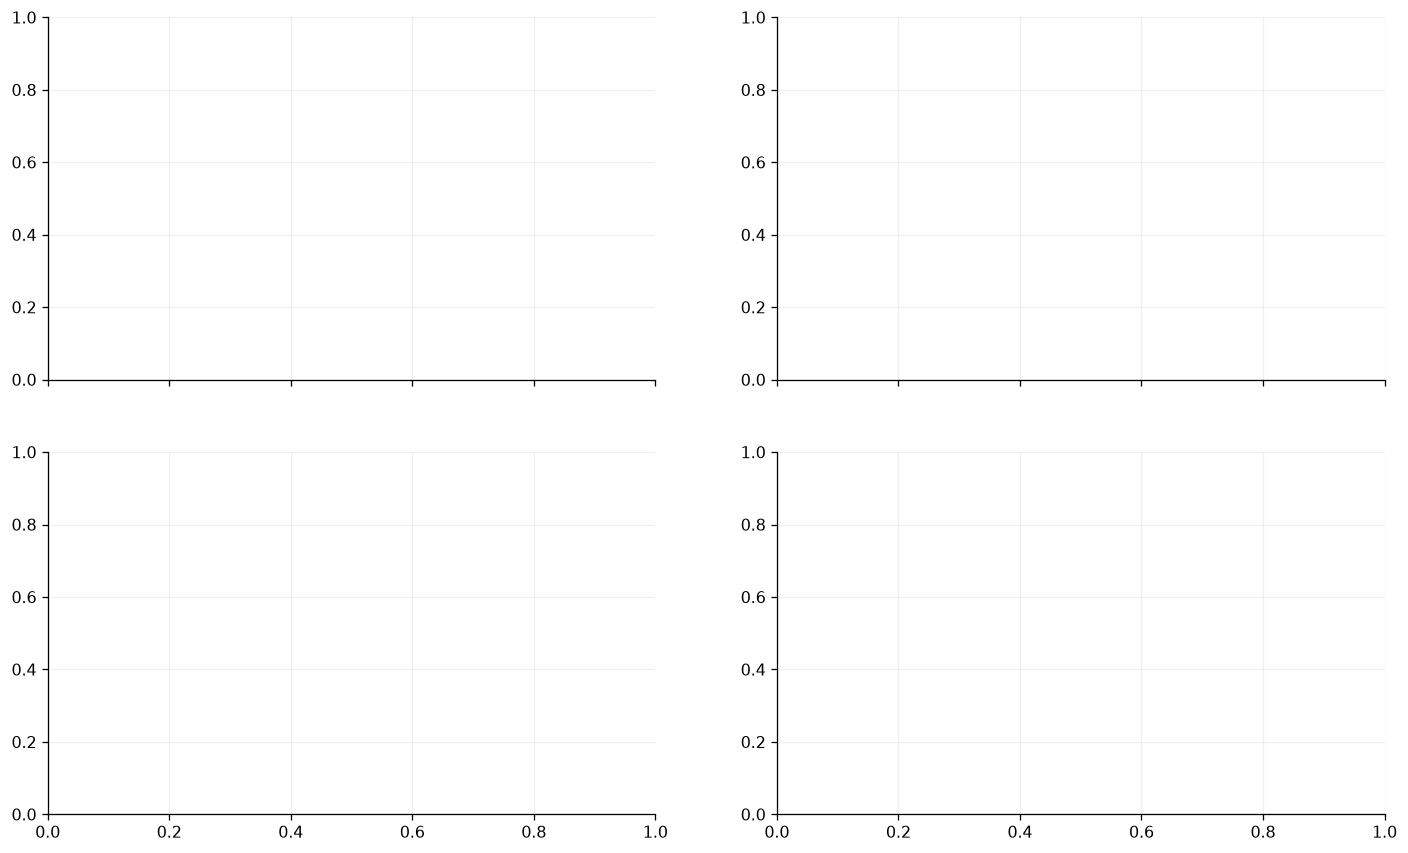

In [74]:
# Preparing the E10 and diesel volatility comparison panels
fig, axs = plt.subplots(
    2, 2,
    figsize=(15, 9),
    sharex='col'
)

In [75]:
# Plotting the observed daily index changes for E10 and diesel
for i, fuel in enumerate(FUELS):
    d = vol_frames[(fuel, 7)]
    color = PAL[fuel]

    axs[i, 0].plot(
        d.index,
        d['price_change_t'],
        color=color,
        alpha=0.65,
        linewidth=0.85,
        label='Observed daily price change'
    )
    axs[i, 0].axhline(0, color='grey', linewidth=0.8)
    axs[i, 0].set(
        ylabel='Daily price change (pence/litre)',
        title=f'{LABELS[fuel]} | Daily index movements'
    )

In [76]:
# Comparing past seven-day RMS change with the future realised target
# Future volatility is displayed in hindsight, never used as a predictor.
for i, fuel in enumerate(FUELS):
    d = vol_frames[(fuel, 7)]
    color = PAL[fuel]

    axs[i, 1].plot(
        d.index, d['hist_rms_change_7d'],
        color=color, linewidth=1.7,
        label='Previous 7 days: historical RMS'
    )
    axs[i, 1].plot(
        d.index, d['future_rms_volatility'],
        color='#263C5A', linewidth=1.25, alpha=0.7,
        label='Next 7 days: realised RMS (hindsight)'
    )
    axs[i, 1].set(
        ylabel='RMS of daily changes (pence/litre)',
        title=f'{LABELS[fuel]} | Historical vs future volatility'
    )

In [77]:
# Generating and displaying the figure
for i, fuel in enumerate(FUELS):
    for ax in axs[i]:
        ax.legend(fontsize=8)
        ax.grid(alpha=0.2)

fig.suptitle(
    'Figure 14 | Daily Price Movements and Future Volatility',
    fontsize=15, fontweight='bold', y=1.01
)
fig.tight_layout()
plt.show()

**16.2. Temporal Volatility vs Spatial Dispersion**

Compare two different characteristics of fuel prices:
1. Temporal volatility:
   How much daily price changes vary over time.
2. Spatial dispersion:
   How much prices differ between stations on a particular date.

Both measures are useful, but they describe different aspects of fuel-price behaviour.

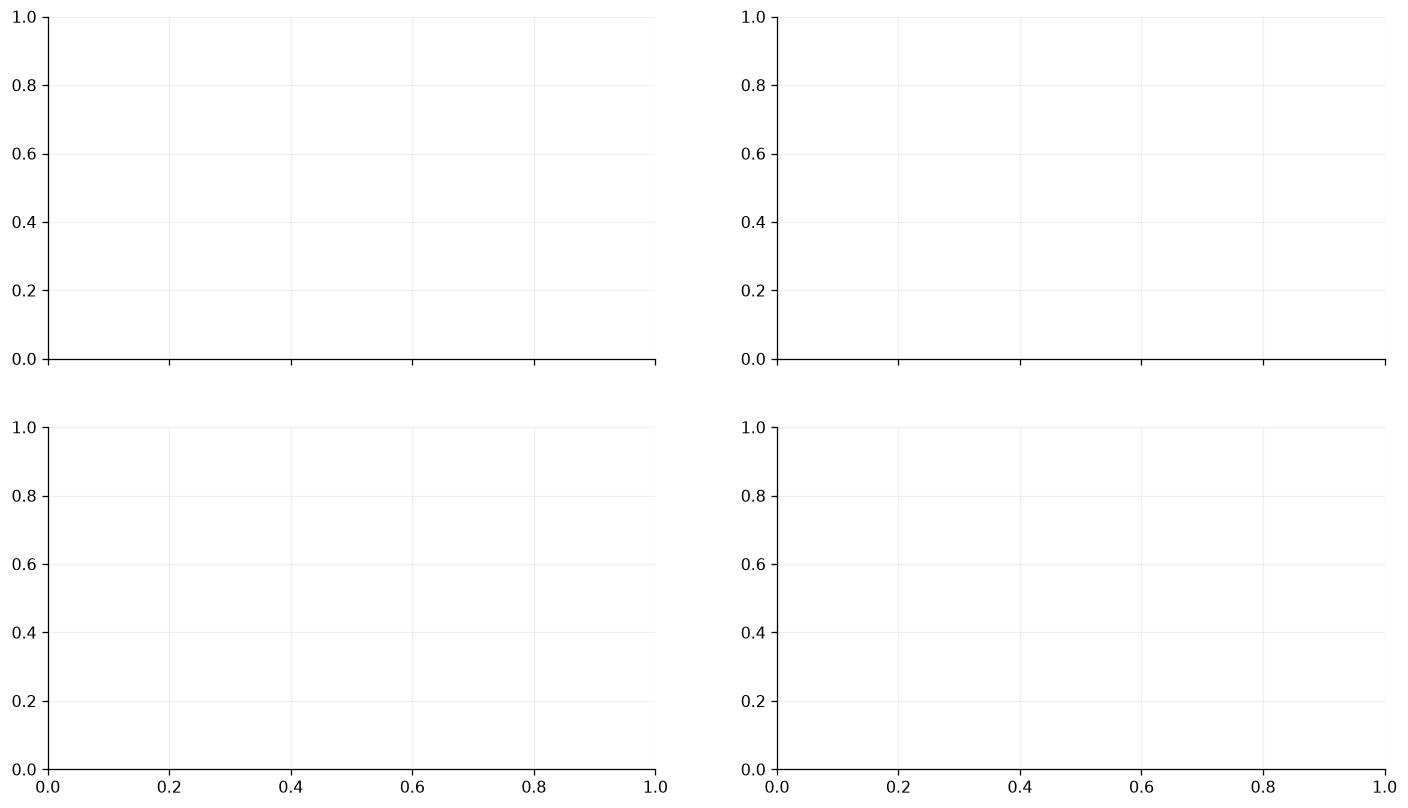

In [78]:
# Preparing the temporal-versus-spatial comparison panels
fig, axs = plt.subplots(
    2, 2,
    figsize=(15, 8.5),
    sharex=True
)

In [79]:
# Plotting the temporal variation in daily price-index changes
for i, fuel in enumerate(FUELS):
    d = vol_frames[(fuel, 7)]

    axs[i, 0].plot(
        d.index,
        d['hist_sd_change_7d'],
        color=PAL[fuel],
        linewidth=1.5,
        label='7-day SD of daily price changes'
    )
    axs[i, 0].set(
        ylabel='SD of price changes (pence/litre)',
        title=f'{LABELS[fuel]} | Temporal volatility'
    )

In [80]:
# Plotting the same-day differences in prices across stations
for i, fuel in enumerate(FUELS):
    z = (
        panel.loc[panel.fuel_type.eq(fuel)]
        .set_index('date')
    )
    axs[i, 1].plot(
        z.index,
        z['spatial_std'],
        color='#6856A2',
        linewidth=1.5,
        label='Same-day spatial price SD'
    )
    axs[i, 1].set(
        ylabel='Across-station SD (pence/litre)',
        title=f'{LABELS[fuel]} | Spatial dispersion'
    )

In [81]:
# Generating and displaying Figure
for i, fuel in enumerate(FUELS):
    for ax in axs[i]:
        ax.legend(fontsize=8)
        ax.grid(alpha=0.2)

fig.suptitle(
    'Figure 15 | Temporal Volatility and Spatial Price Dispersion',
    fontsize=15, fontweight='bold', y=1.01
)
fig.tight_layout()
plt.show()


**16.3. Station Coverage and Data Reliability**

Examine how station participation and reporting activity vary throughout the observation period.

The reconstructed fuel-price index depends on the availability of recent station-price observations.

Changes in reporting coverage may influence both measured price movements and estimated volatility.

In [82]:
# Calculating matched, active and observed station-coverage statistics
coverage_summary = (
    panel
    .groupby('fuel_type')[[
        'paired_stations',
        'active_stations',
        'observed_stations'
    ]]
    .describe(percentiles=[0.1, 0.5, 0.9])
)

In [83]:
# Displaying station coverage statistics for both fuels
display(Markdown('### Station Reporting Coverage Summary'))
display(coverage_summary.round(1))


### Station Reporting Coverage Summary

paired_stations                                                  \
                      count    mean     std     min     10%     50%     90%   
fuel_type                                                                     
B7_STANDARD           203.0  5346.0  1382.7  2609.0  3455.2  5854.0  6954.0   
E10                   203.0  4792.0  1482.6  2257.0  2985.2  4711.0  6774.0   

                    active_stations          ...                  \
                max           count    mean  ...     90%     max   
fuel_type                                    ...                   
B7_STANDARD  7419.0           203.0  5603.7  ...  7044.0  7475.0   
E10          7302.0           203.0  5074.6  ...  6885.8  7432.0   

            observed_stations                                               \
                        count    mean     std   min    10%     50%     90%   
fuel_type                                                                    
B7_STANDARD             203.0  1668.9  1127.4  99.0  352.6  1343.0  3323.2   
E10                     203.0  1343.5   961.2  90.0  258.4  1049.0  2849.8   

                     
                max  
fuel_type            
B7_STANDARD  4966.0  
E10          4379.0  

[2 rows x 24 columns]

## 17. Forecast future volatility

I compare persistence, Ridge, XGBoost and LightGBM on the same **7- and 14-day future RMS-change target**. These are additional models for volatility, not replacements for the earlier price-level LSTM/XGBoost/LightGBM/SARIMAX comparison.

For a forecast made on date \(t\), a training label can be used only if its entire future \(h\)-day window ended before the training cutoff. Models are trained on the earlier validation information and are evaluated on the later **3 August 2026** holdout. Negative RMS predictions are clipped to zero by the defined forecast rule. Since neighbouring targets overlap, test errors will not be statistically independent.

### 17.1. Defining the volatility forecasting models

Preserve the original Ridge, XGBoost and LightGBM configurations. Persistence is computed directly from historical RMS changes.

In [84]:
# Training separate models to forecast future RMS price-change volatility.
# Matching each training label to what would have been known before the forecast block.

# Retaining the volatility algorithms separate from the price-level models above.
def make_vol_model(name):
    if name=='Ridge':
        return make_pipeline(StandardScaler(),Ridge(alpha=20.0))
    if name=='XGBoost':
        return XGBRegressor(n_estimators=120,max_depth=2,learning_rate=.035,
                            min_child_weight=5,subsample=.9,colsample_bytree=.9,
                            reg_lambda=12,objective='reg:squarederror',n_jobs=2,random_state=SEED)
    if name=='LightGBM':
        return LGBMRegressor(n_estimators=90,num_leaves=5,max_depth=2,min_child_samples=10,
                             learning_rate=.035,reg_lambda=12,verbosity=-1,random_state=SEED,n_jobs=2)
    raise ValueError(name)

### 17.2. Training and predicting without future-label leakage

Use only complete, matured training labels at each cutoff. The same function supports matched baseline and Brent/FX comparisons later.

**Select eligible volatility training and evaluation origins**

Only retain training labels whose complete h-day target is observed by the cutoff; forecast dates must have complete inputs.

In [85]:
# Compiling the analysis for this subsection
def _vol_prepare_split(fuel, h, origins, cutoff, split, trainable_macro):
    d = vol_frames[(fuel, h)]
    origins = pd.DatetimeIndex(origins).intersection(d.index)
    origins = origins[origins + pd.Timedelta(days=h) <= d.index.max()]
    base_cols = VOL_FEAT_COLS
    cols_all = base_cols + (VOL_MACRO_COLS if trainable_macro else [])
    train_mask = (d.index + pd.Timedelta(days=h) <= cutoff) & (d.index <= cutoff)
    train_mask &= d[cols_all + ['future_rms_volatility']].notna().all(axis=1).values
    pred_mask = d.loc[origins, cols_all + ['future_rms_volatility']].notna().all(axis=1)
    origins = origins[pred_mask]
    tr, te = d.loc[train_mask], d.loc[origins]
    if len(tr) < 30 or len(te) == 0:
        raise ValueError(f'Not enough training and evaluation rows: {fuel} h{h}, {split}')
    return origins, tr, te, base_cols, cols_all

**Generate one volatility model prediction**

Fit the chosen model on matured labels or use the unchanged historical RMS persistence baseline.

In [86]:
# Compiling the analysis for this subsection
def _vol_predict_model(name, trainable_macro, macro_only_model, h,
                       tr, te, base_cols, cols_all):
    if name == 'Persistence':
        return te[f'hist_rms_change_{h}d'].to_numpy()
    family = macro_only_model if trainable_macro else name
    model = make_vol_model(family)
    use_cols = (cols_all if (trainable_macro and
                name.endswith('+ lagged Brent/FX')) else base_cols)
    model.fit(tr[use_cols], tr['future_rms_volatility'])
    return np.maximum(0, np.asarray(model.predict(te[use_cols]), dtype=float))

**Format the observed and predicted volatility records**

Store all evaluation fields, including target dates, secondary diagnostics and future station-coverage metadata.

In [87]:
# Run the analysis for this subsection
def _vol_prediction_rows(fuel, h, split, name, origins, te, pred):
    rows = []
    for t, y, p, sd, paired in zip(
        origins, te.future_rms_volatility.to_numpy(), pred,
        te.future_sd_changes.to_numpy(), te.min_future_paired.to_numpy()
    ):
        rows.append(dict(
            fuel_type=fuel, horizon_days=h, split=split,
            origin_date=t, target_end_date=t + pd.Timedelta(days=h),
            model=name, actual=float(y), prediction=float(p),
            secondary_future_sd=float(sd), min_future_paired=float(paired)
        ))
    return rows

**Execute a complete volatility forecast split**

Preserve the vol_split_predict interface for the original validation, holdout and macroeconomic ablation experiments.

In [88]:
# Run the analysis for this subsection
def vol_split_predict(fuel, h, origins, cutoff, split,
                      trainable_macro=False, macro_only_model=None):
    origins, tr, te, base_cols, cols_all = _vol_prepare_split(
        fuel, h, origins, cutoff, split, trainable_macro
    )
    if trainable_macro:
        names = [f'{macro_only_model} (price-history matched)',
                 f'{macro_only_model} + lagged Brent/FX']
    else:
        names = VOL_MODELS
    rows = []
    for name in names:
        pred = _vol_predict_model(name, trainable_macro, macro_only_model,
                                  h, tr, te, base_cols, cols_all)
        rows.extend(_vol_prediction_rows(fuel, h, split, name, origins, te, pred))
    return rows

### 17.3. Generating validation and holdout predictions

Forecast both fuels and horizons on the existing chronological windows and check that observed targets and predictions are present.

In [89]:
# Generating common chronological validation and holdout forecasts
vol_val_rows = []
vol_test_rows = []
for fuel in FUELS:
    for h in VOL_HORIZONS:
        for k, start in enumerate(VAL_STARTS, 1):
            vol_val_rows.extend(
                vol_split_predict(
                    fuel, h,
                    pd.date_range(start, periods=14),
                    start - pd.Timedelta(days=1),
                    f'V{k}'
                )
            )
        vol_test_rows.extend(
            vol_split_predict(
                fuel, h,
                pd.date_range(
                    TEST_START,
                    INDEX_END - pd.Timedelta(days=h)
                ),
                TEST_START - pd.Timedelta(days=1),
                'TEST'
            )
        )

In [90]:
# Assembling and validate non-missing price-volatility forecasts
vol_val_preds = pd.DataFrame(vol_val_rows)
vol_test_preds = pd.DataFrame(vol_test_rows)

assert not vol_val_preds[['actual', 'prediction']].isna().any().any()
assert not vol_test_preds[['actual', 'prediction']].isna().any().any()
print(
    'Genuine observed-target predictions:',
    len(vol_val_preds), 'validation and',
    len(vol_test_preds), 'holdout.'
)

Genuine observed-target predictions: 672 validation and 504 holdout.


### 17.4. Scoring volatility prediction performance

Compute MAE, RMSE, R² and signed bias, and display validation scores before any holdout-based interpretation.

In [91]:
# Defining volatility MAE, RMSE, R² and signed-bias scoring
def vol_score(df):
    rows = []
    for (fuel, h, name), g in df.groupby(
        ['fuel_type', 'horizon_days', 'model']
    ):
        rows.append({
            'fuel_type': fuel,
            'horizon_days': h,
            'model': name,
            'n': len(g),
            'MAE': mean_absolute_error(g.actual, g.prediction),
            'RMSE': np.sqrt(mean_squared_error(g.actual, g.prediction)),
            'R2': r2_score(g.actual, g.prediction),
            'Bias': (g.prediction - g.actual).mean()
        })
    return pd.DataFrame(rows)

In [92]:
# Scoring validation and holdout predictions and display validation
vol_val_scores = vol_score(vol_val_preds)
vol_test_scores = vol_score(vol_test_preds)

display(Markdown('### Validation results - price-change volatility'))
display(
    vol_val_scores
    .sort_values(['fuel_type', 'horizon_days', 'MAE'])
    .round(4)
)

### Validation results - price-change volatility

,fuel_type,horizon_days,model,n,MAE,RMSE,R2,Bias
1,B7_STANDARD,7,Persistence,42,0.2585,0.2952,-0.2475,-0.0428
3,B7_STANDARD,7,XGBoost,42,0.3373,0.3669,-0.9275,-0.1363
0,B7_STANDARD,7,LightGBM,42,0.3407,0.3653,-0.9109,-0.1289
2,B7_STANDARD,7,Ridge,42,0.3795,0.4269,-1.6097,0.0447
7,B7_STANDARD,14,XGBoost,42,0.2489,0.2770,-0.8378,-0.0705
5,B7_STANDARD,14,Persistence,42,0.3119,0.3435,-1.8269,-0.0884
4,B7_STANDARD,14,LightGBM,42,0.3344,0.3575,-2.0609,-0.1616
6,B7_STANDARD,14,Ridge,42,0.3747,0.4250,-3.3258,0.1257
9,E10,7,Persistence,42,0.1282,0.1534,0.2385,-0.0360
8,E10,7,LightGBM,42,0.1928,0.2090,-0.4129,-0.0655


## 18. Select the volatility model and inspect its test forecasts

I apply the same idea as in the price experiment: rank models within each E10/diesel and 7/14-day task on MAE, RMSE and R², then average those ranks. Persistence is allowed to win. Only after choosing from validation do I inspect the final holdout.

A low-variation volatility target can make R² unstable or negative, so absolute errors and the baseline comparison remain essential.

### 18.1. Selecting the volatility model from validation

Rank all four methods within each fuel-horizon task and select the overall validation winner. Retain the highest-ranked trainable model for the economic-feature experiment.

In [93]:
# Ranking volatility models using only chronological validation results
vol_ranks = vol_val_scores.copy()
for metric, ascending in [
    ('MAE', True),
    ('RMSE', True),
    ('R2', False)
]:
    vol_ranks[metric + '_rank'] = (
        vol_ranks.groupby(['fuel_type', 'horizon_days'])[metric]
        .rank(ascending=ascending)
    )
vol_ranks['joint_rank'] = (
    vol_ranks[['MAE_rank', 'RMSE_rank', 'R2_rank']].mean(axis=1)
)

In [94]:
# Selecting the overall winner and strongest learnable model
vol_league = (
    vol_ranks.groupby('model', as_index=False)
    .agg(
        overall_rank=('joint_rank', 'mean'),
        average_MAE_rank=('MAE_rank', 'mean'),
        average_RMSE_rank=('RMSE_rank', 'mean'),
        average_R2_rank=('R2_rank', 'mean')
    )
    .sort_values(['overall_rank', 'model'])
    .reset_index(drop=True)
)
VOL_CHAMPION = str(vol_league.iloc[0].model)
VOL_MACRO_FAMILY = (
    VOL_CHAMPION if VOL_CHAMPION != 'Persistence'
    else vol_league.loc[vol_league.model != 'Persistence', 'model'].iloc[0]
)

In [95]:
# Reporting validation selection before inspecting untouched holdout scores
display(vol_league.round(3))
display(Markdown(
    f'**Volatility validation winner:** `{VOL_CHAMPION}`. '
    f'**Macro ablation learnable family:** `{VOL_MACRO_FAMILY}`.'
))
display(Markdown('### Untouched final test — all models (not used in ranking)'))
display(
    vol_test_scores
    .sort_values(['fuel_type', 'horizon_days', 'MAE'])
    .round(4)
)

,model,overall_rank,average_MAE_rank,average_RMSE_rank,average_R2_rank
0,Persistence,1.667,1.50,1.75,1.75
1,LightGBM,2.083,2.25,2.00,2.00
2,XGBoost,2.750,2.25,3.00,3.00
3,Ridge,3.500,4.00,3.25,3.25


**Volatility validation winner:** `Persistence`. **Macro ablation learnable family:** `LightGBM`.

### Untouched final test — all models (not used in ranking)

,fuel_type,horizon_days,model,n,MAE,RMSE,R2,Bias
1,B7_STANDARD,7,Persistence,35,0.2208,0.2746,-0.4603,-0.0429
2,B7_STANDARD,7,Ridge,35,0.2556,0.2872,-0.5974,0.1723
3,B7_STANDARD,7,XGBoost,35,0.2914,0.3279,-1.0813,0.1824
0,B7_STANDARD,7,LightGBM,35,0.3168,0.3532,-1.4149,0.2074
5,B7_STANDARD,14,Persistence,28,0.3138,0.3722,-3.9505,0.0622
6,B7_STANDARD,14,Ridge,28,0.3931,0.4305,-5.6249,0.3931
4,B7_STANDARD,14,LightGBM,28,0.4302,0.4733,-7.0081,0.3641
7,B7_STANDARD,14,XGBoost,28,0.4427,0.4912,-7.6248,0.3859
10,E10,7,Ridge,35,0.1593,0.1806,0.4451,0.0438
9,E10,7,Persistence,35,0.1731,0.2415,0.0075,-0.0751


### 18.2. Visualising volatility validation accuracy

Figure 16 compares the four volatility methods across 7- and 14-day horizons for both fuels.

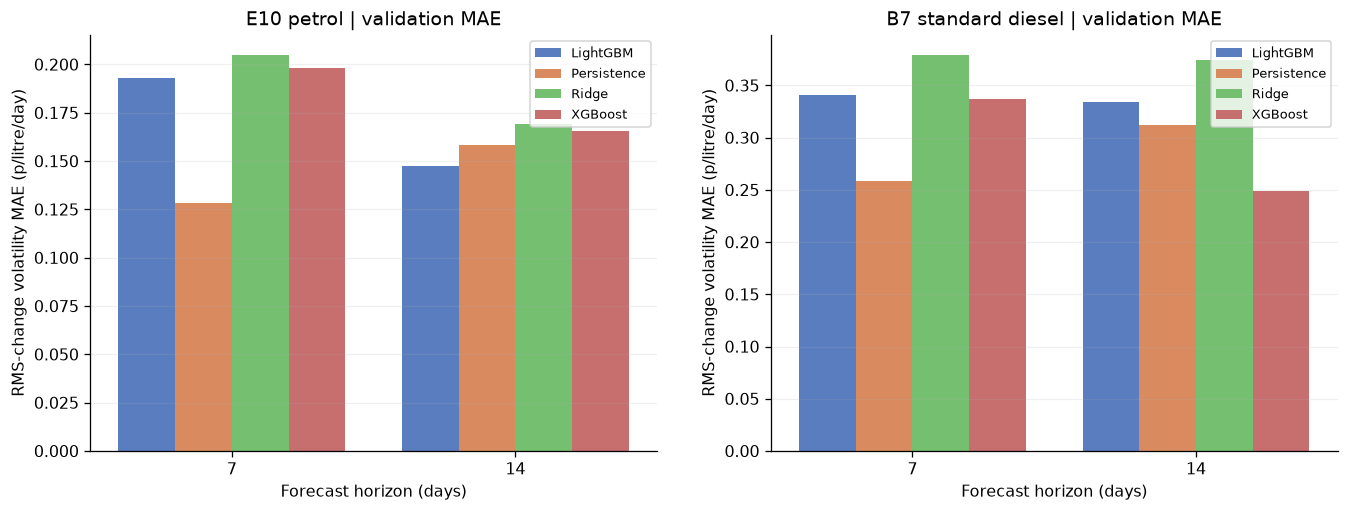

In [96]:
# Plotting the volatility validation MAE panels for each fuel
fig, axs = plt.subplots(1, 2, figsize=(14, 4.7), sharey=False)
for ax, fuel in zip(axs, FUELS):
    p = vol_val_scores[vol_val_scores.fuel_type == fuel]
    sns.barplot(
        data=p,
        x='horizon_days', y='MAE', hue='model',
        ax=ax, order=VOL_HORIZONS,
        palette='muted', errorbar=None
    )
    ax.set(
        title=f'{LABELS[fuel]} | validation MAE',
        xlabel='Forecast horizon (days)',
        ylabel='RMS-change volatility MAE (p/litre/day)'
    )
    ax.legend(fontsize=8)

In [97]:
# Generating and displaying the volatility validation comparison (Figure 16)
fig.suptitle(
    'Figure 16 | Which model best forecasts future measured volatility?',
    weight='bold', y=1.03
)
fig.tight_layout()
plt.show()

### 18.3. Inspecting held-out volatility forecasts

Figure 17 compares observed future RMS change with the validation-selected method and a transparent comparison model.

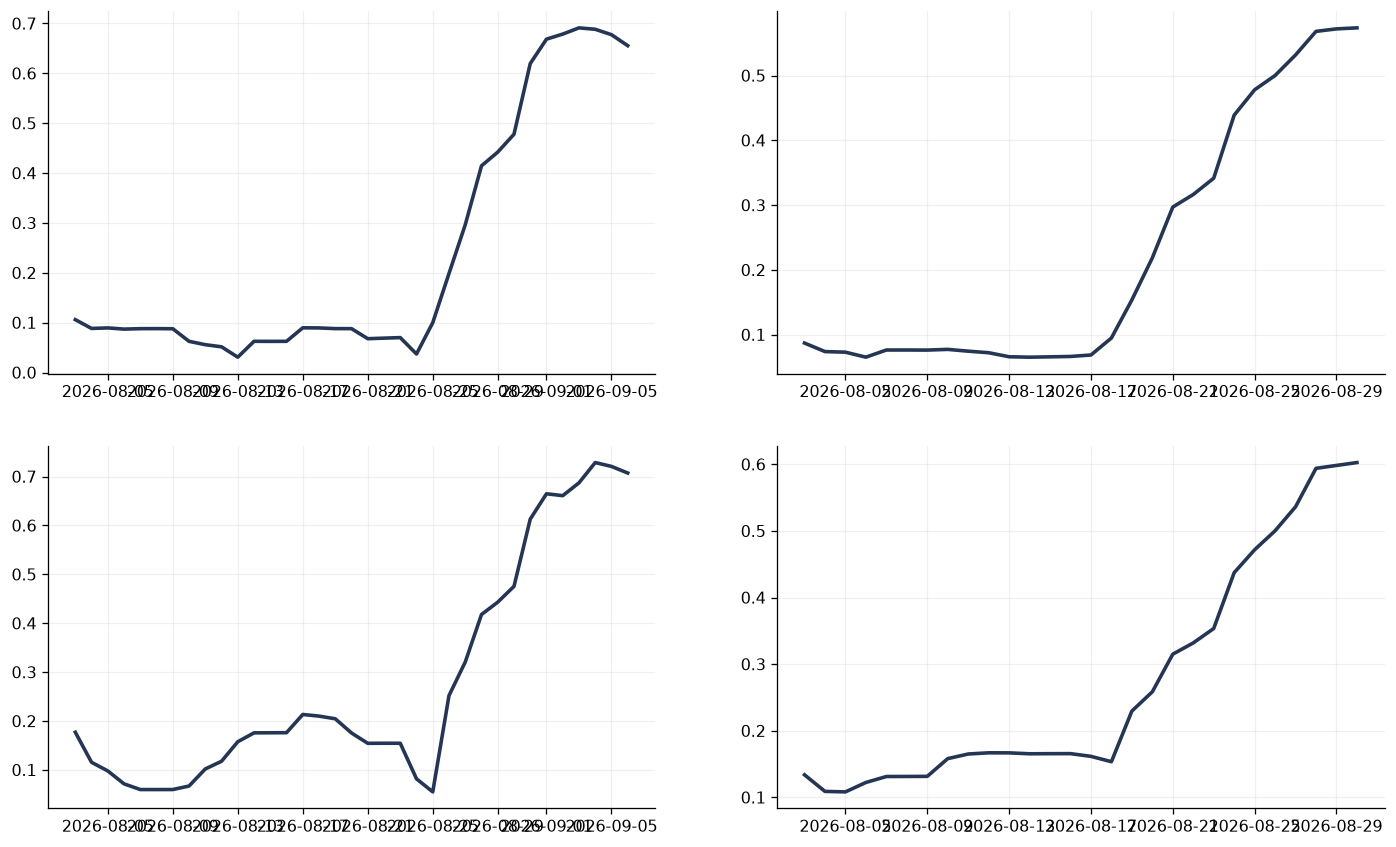

In [98]:
# Plotting held-out realised volatility and selected-model predictions
fig, axs = plt.subplots(2, 2, figsize=(15, 9), sharex=False)
for i, fuel in enumerate(FUELS):
    for j, h in enumerate(VOL_HORIZONS):
        ax = axs[i, j]
        g = vol_test_preds[
            (vol_test_preds.fuel_type == fuel)
            & (vol_test_preds.horizon_days == h)
        ]
        if len(g) == 0:
            continue
        observed = g[g.model == VOL_CHAMPION].sort_values('origin_date')
        ax.plot(
            observed.origin_date, observed.actual,
            color='#243653', lw=2.25,
            label='Future realised RMS change'
        )

In [99]:
# Overlaying validation-selected and comparison-model holdout predictions
comparison_model = (
    'Persistence' if VOL_CHAMPION != 'Persistence'
    else vol_league.loc[vol_league.model != 'Persistence', 'model'].iloc[0]
)
for i, fuel in enumerate(FUELS):
    for j, h in enumerate(VOL_HORIZONS):
        ax = axs[i, j]
        g = vol_test_preds[
            (vol_test_preds.fuel_type == fuel)
            & (vol_test_preds.horizon_days == h)
        ]
        if len(g) == 0:
            continue
        for name, color in [
            (VOL_CHAMPION, '#087F8C'),
            (comparison_model, '#C77944')
        ]:
            t = g[g.model == name].sort_values('origin_date')
            ax.plot(
                t.origin_date, t.prediction, color=color,
                ls='--' if name == 'Persistence' else '-',
                lw=1.65, label=name + ' forecast'
            )
        ax.set(
            title=f'{LABELS[fuel]} | next {h} days',
            ylabel='RMS daily Δprice (p/litre)'
        )
        ax.legend(fontsize=8)

In [100]:
# Generating and display observed-versus-predicted volatility (Figure 17)
fig.suptitle(
    'Figure 17 | Held-out volatility: observed future outcome vs predictions',
    weight='bold', y=1.01
)
fig.tight_layout()
plt.show()

## 19. Does adding Brent and FX help predict future volatility?

For the highest-ranked **trainable** volatility model, I repeat the forecasts twice on matched rows: first with price history and coverage, then with the same variables **plus lagged Brent/GBP and exchange-rate features**. The macro data are initially lagged by 21 calendar days. All preprocessing is fitted on training observations.

This tests **additional predictive information**, not causality. The FRED files are not release-vintage archives, and the short sample limits conclusions about how economic shocks affect the whole UK market.

### 19.1. Running matched economic-feature experiments

Fit the selected trainable volatility model with and without lagged Brent and currency features, always on matched origins.

In [101]:
# Generating matched volatility forecasts with and without lagged macro data
vol_macro_val_rows = []
vol_macro_test_rows = []
for fuel in FUELS:
    for h in VOL_HORIZONS:
        for k, start in enumerate(VAL_STARTS, 1):
            vol_macro_val_rows.extend(
                vol_split_predict(
                    fuel, h, pd.date_range(start, periods=14),
                    start - pd.Timedelta(days=1), f'V{k}',
                    trainable_macro=True,
                    macro_only_model=VOL_MACRO_FAMILY
                )
            )
        vol_macro_test_rows.extend(
            vol_split_predict(
                fuel, h,
                pd.date_range(TEST_START, INDEX_END - pd.Timedelta(days=h)),
                TEST_START - pd.Timedelta(days=1), 'TEST',
                trainable_macro=True,
                macro_only_model=VOL_MACRO_FAMILY
            )
        )

In [102]:
# Score matched economic-factor and price-history-only comparisons
vol_macro_val_preds = pd.DataFrame(vol_macro_val_rows)
vol_macro_test_preds = pd.DataFrame(vol_macro_test_rows)
vol_macro_val_scores = vol_score(vol_macro_val_preds)
vol_macro_test_scores = vol_score(vol_macro_test_preds)
base_name = f'{VOL_MACRO_FAMILY} (price-history matched)'
exog_name = f'{VOL_MACRO_FAMILY} + lagged Brent/FX'

In [103]:
# Displaying matched validation and final-holdout economic comparisons
display(Markdown('### Validation: equal-information-set, paired-origin macro ablation'))
display(
    vol_macro_val_scores
    .sort_values(['fuel_type', 'horizon_days', 'model'])
    .round(4)
)
display(Markdown('### Final test: paired-origin macro ablation'))
display(
    vol_macro_test_scores
    .sort_values(['fuel_type', 'horizon_days', 'model'])
    .round(4)
)

### Validation: equal-information-set, paired-origin macro ablation

,fuel_type,horizon_days,model,n,MAE,RMSE,R2,Bias
0,B7_STANDARD,7,LightGBM (price-history matched),42,0.3407,0.3653,-0.9109,-0.1289
1,B7_STANDARD,7,LightGBM + lagged Brent/FX,42,0.3251,0.3575,-0.8303,-0.1076
2,B7_STANDARD,14,LightGBM (price-history matched),42,0.3344,0.3575,-2.0609,-0.1616
3,B7_STANDARD,14,LightGBM + lagged Brent/FX,42,0.3028,0.3277,-1.5723,-0.1183
4,E10,7,LightGBM (price-history matched),42,0.1928,0.2090,-0.4129,-0.0655
5,E10,7,LightGBM + lagged Brent/FX,42,0.2029,0.2202,-0.5674,-0.0402
6,E10,14,LightGBM (price-history matched),42,0.1475,0.1649,-0.3778,-0.0848
7,E10,14,LightGBM + lagged Brent/FX,42,0.1533,0.1642,-0.3659,-0.0689


### Final test: paired-origin macro ablation

,fuel_type,horizon_days,model,n,MAE,RMSE,R2,Bias
0,B7_STANDARD,7,LightGBM (price-history matched),35,0.3168,0.3532,-1.4149,0.2074
1,B7_STANDARD,7,LightGBM + lagged Brent/FX,35,0.2805,0.3112,-0.8753,0.1627
2,B7_STANDARD,14,LightGBM (price-history matched),28,0.4302,0.4733,-7.0081,0.3641
3,B7_STANDARD,14,LightGBM + lagged Brent/FX,28,0.3975,0.4628,-6.6561,0.3970
4,E10,7,LightGBM (price-history matched),35,0.1956,0.2196,0.1791,0.0157
5,E10,7,LightGBM + lagged Brent/FX,35,0.2138,0.2270,0.1227,0.0845
6,E10,14,LightGBM (price-history matched),28,0.1580,0.1715,0.2067,0.0513
7,E10,14,LightGBM + lagged Brent/FX,28,0.2051,0.2334,-0.4688,0.1397


### 19.2. Quantifying the additional predictive value

Compare matched predictions using MAE, RMSE and R² differences. A positive MAE reduction means the macro-extended model made smaller errors.

In [104]:
# Calculating paired MAE, RMSE and R² improvements from macro inputs
comparison = []
for split, records in [
    ('Validation', vol_macro_val_preds),
    ('Test', vol_macro_test_preds)
]:
    for (fuel, h), grp in records.groupby(['fuel_type', 'horizon_days']):
        wide = grp.pivot(
            index='origin_date', columns='model',
            values=['actual', 'prediction']
        )
        assert np.allclose(wide[('actual', base_name)], wide[('actual', exog_name)])
        yy = wide[('actual', base_name)].to_numpy()
        p0 = wide[('prediction', base_name)].to_numpy()
        p1 = wide[('prediction', exog_name)].to_numpy()
        comparison.append({
            'split': split,
            'fuel_type': fuel,
            'horizon_days': h,
            'n_origins': len(yy),
            'MAE_without_macro': mean_absolute_error(yy, p0),
            'MAE_with_macro': mean_absolute_error(yy, p1),
            'MAE_reduction': mean_absolute_error(yy, p0) - mean_absolute_error(yy, p1),
            'RMSE_reduction': np.sqrt(mean_squared_error(yy, p0)) - np.sqrt(mean_squared_error(yy, p1)),
            'R2_increase': r2_score(yy, p1) - r2_score(yy, p0)
        })

In [105]:
# Displaying the per-fuel, per-horizon incremental macro accuracy
vol_macro_comparison = pd.DataFrame(comparison)
display(vol_macro_comparison.round(4))

,split,fuel_type,horizon_days,n_origins,MAE_without_macro,MAE_with_macro,MAE_reduction,RMSE_reduction,R2_increase
0,Validation,B7_STANDARD,7,42,0.3407,0.3251,0.0156,0.0078,0.0806
1,Validation,B7_STANDARD,14,42,0.3344,0.3028,0.0316,0.0298,0.4886
2,Validation,E10,7,42,0.1928,0.2029,-0.0101,-0.0111,-0.1545
3,Validation,E10,14,42,0.1475,0.1533,-0.0058,0.0007,0.0119
4,Test,B7_STANDARD,7,35,0.3168,0.2805,0.0363,0.0419,0.5396
5,Test,B7_STANDARD,14,28,0.4302,0.3975,0.0327,0.0105,0.3520
6,Test,E10,7,35,0.1956,0.2138,-0.0182,-0.0074,-0.0564
7,Test,E10,14,28,0.1580,0.2051,-0.0471,-0.0619,-0.6755


### 19.3. Visualising incremental forecasting gains

Figure 18 shows the scale and direction of the economic-feature effect in validation and holdout.

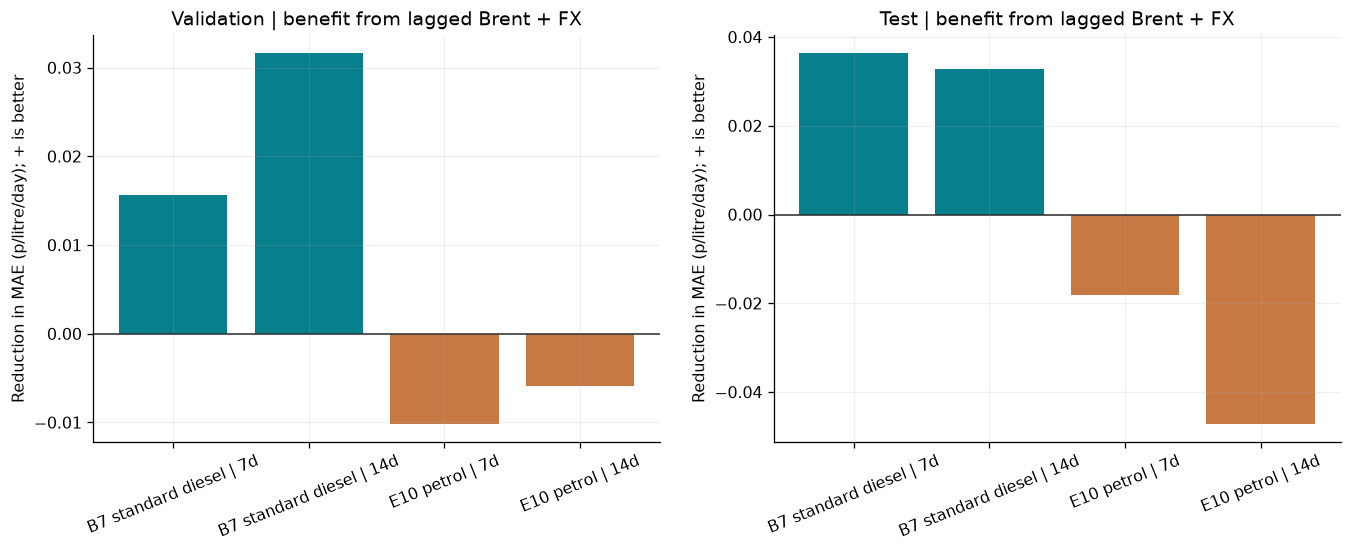

In [106]:
# Plotting paired validation and holdout MAE changes from economic predictors
fig, axs = plt.subplots(1, 2, figsize=(14, 4.6))
for ax, split in zip(axs, ['Validation', 'Test']):
    g = vol_macro_comparison[vol_macro_comparison.split.eq(split)].copy()
    g['task'] = g.fuel_type.map(LABELS) + ' | ' + g.horizon_days.astype(str) + 'd'
    ax.bar(
        g.task, g.MAE_reduction,
        color=['#087F8C' if x > 0 else '#C77944' for x in g.MAE_reduction]
    )
    ax.axhline(0, color='#333333', lw=1)
    ax.tick_params(axis='x', rotation=22)
    ax.set(
        title=f'{split} | benefit from lagged Brent + FX',
        ylabel='Reduction in MAE (p/litre/day); + is better'
    )

In [107]:
# Generating and display economic-feature accuracy changes (Figure 18)
fig.suptitle(
    'Figure 18 | Incremental value of observed economic drivers',
    weight='bold', y=1.02
)
fig.tight_layout()
plt.show()

## 20. Check uncertainty and reporting-coverage sensitivity

A moving-block bootstrap gives an exploratory interval for the difference in test MAE between the two volatility models. I use blocks rather than drawing individual test dates independently because nearby 7-/14-day forecast outcomes overlap.

I also calculate results for windows with at least **100 matched station pairs**. That threshold is a chosen sensitivity check, not a scientifically validated standard. If no windows are excluded, the comparison adds little evidence. These diagnostics do not turn a short series into a statistically representative national study.

### 20.1. Estimating exploratory moving-block uncertainty

Resample consecutive segments of paired forecast-error differences to reflect overlap between neighbouring seven- and fourteen-day targets.

In [108]:
# Checking whether any apparent benefit is robust to overlapping forecast errors and station coverage.
# These are exploratory checks, not a substitute for several years of independent tests.

rng=np.random.default_rng(SEED)

# Resampling short blocks of consecutive errors to retain some serial dependence.
def block_bootstrap_delta(y,p0,p1,block,replicates=500):
    # Positive improvement means the exogenous model has smaller MAE.
    diff=np.abs(np.asarray(y)-np.asarray(p0))-np.abs(np.asarray(y)-np.asarray(p1))
    n=len(diff)
    if n<block+3:return (float(np.mean(diff)),np.nan,np.nan)
    start_candidates=np.arange(0,n-block+1)
    outcomes=[]
    for _ in range(replicates):
        chosen=[]
        while len(chosen)<n:
            start=int(rng.choice(start_candidates))
            chosen.extend(range(start,start+block))
        outcomes.append(float(np.mean(diff[np.asarray(chosen[:n],dtype=int)])))
    return float(np.mean(diff)),float(np.quantile(outcomes,.025)),float(np.quantile(outcomes,.975))

### 20.2. Checking station-coverage sensitivity

Compare volatility forecasting improvements with and without a minimum of 100 matched future station pairs.

In [109]:
# Bootstrap and filter economic-comparison errors by matched-station coverage
robust_rows = []
for (fuel, h), g in vol_macro_test_preds.groupby(
    ['fuel_type', 'horizon_days']
):
    w = g.pivot(
        index='origin_date', columns='model',
        values=['actual', 'prediction', 'min_future_paired']
    )
    y = w[('actual', base_name)].to_numpy()
    p0 = w[('prediction', base_name)].to_numpy()
    p1 = w[('prediction', exog_name)].to_numpy()
    pairs = w[('min_future_paired', base_name)].to_numpy()
    delta, lo, hi = block_bootstrap_delta(
        y, p0, p1, block=min(h, max(3, len(y) // 3))
    )
    good = pairs >= 100
    robust_rows.append({
        'fuel_type': fuel,
        'horizon_days': h,
        'n_test_origins': len(y),
        'macro_MAE_reduction': delta,
        'block_bootstrap_95_low': lo,
        'block_bootstrap_95_high': hi,
        'test_windows_min100_matched_pairs': int(good.sum()),
        'coverage_restricted_MAE_reduction': (
            float(
                mean_absolute_error(y[good], p0[good])
                - mean_absolute_error(y[good], p1[good])
            ) if good.sum() > 5 else np.nan
        )
    })

In [110]:
# Displaying the station-coverage sensitivity and bootstrap intervals
vol_robustness = pd.DataFrame(robust_rows)
display(vol_robustness.round(4))

,fuel_type,horizon_days,n_test_origins,macro_MAE_reduction,block_bootstrap_95_low,block_bootstrap_95_high,test_windows_min100_matched_pairs,coverage_restricted_MAE_reduction
0,B7_STANDARD,7,35,0.0363,0.0091,0.0711,35,0.0363
1,B7_STANDARD,14,28,0.0327,-0.0134,0.0626,28,0.0327
2,E10,7,35,-0.0182,-0.0647,0.0267,35,-0.0182
3,E10,14,28,-0.0471,-0.1135,0.0143,28,-0.0471


### 20.3. Visualising coverage and realised volatility

Figure 19 plots reporting coverage against the following week’s measured RMS changes and closes the volatility analysis with its key limitations.

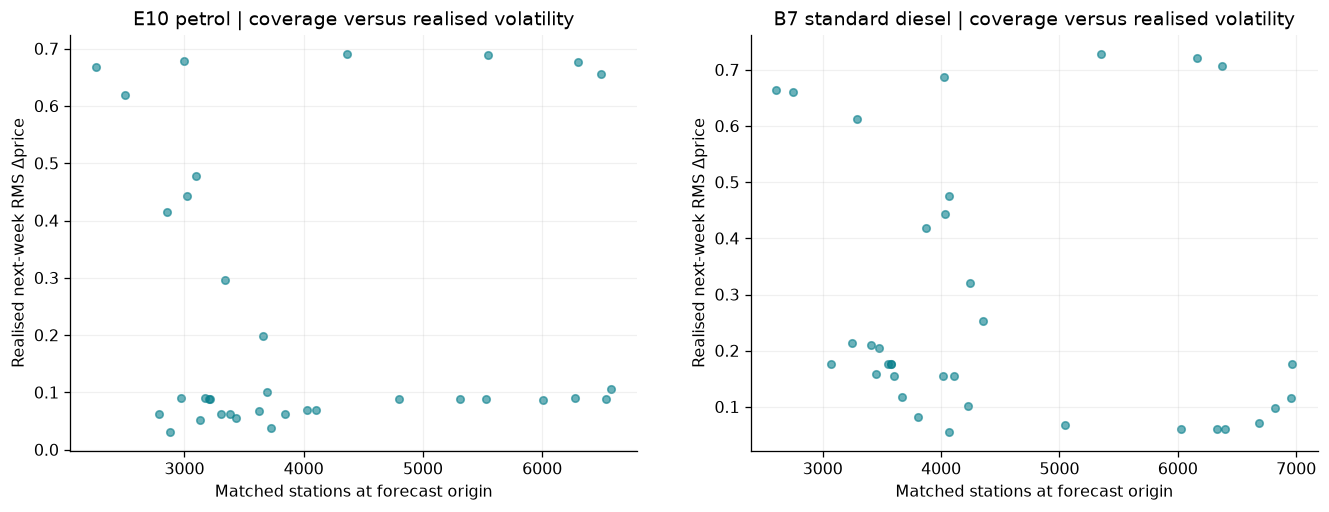

In [111]:
# Plotting reporting coverage against next-week realised volatility
fig, axs = plt.subplots(1, 2, figsize=(14, 4.7))
for ax, fuel in zip(axs, FUELS):
    d = vol_frames[(fuel, 7)].loc[TEST_START:INDEX_END]
    ax.scatter(
        d.paired_stations_t, d.future_rms_volatility,
        c='#087F8C', alpha=0.6, s=22
    )
    ax.set(
        xlabel='Matched stations at forecast origin',
        ylabel='Realised next-week RMS Δprice',
        title=LABELS[fuel] + ' | coverage versus realised volatility'
    )

In [112]:
# Generating Figure 19 and report the volatility research limitations
fig.suptitle(
    'Figure 19 | Price-index volatility may depend on reporting coverage',
    weight='bold', y=1.03
)
fig.tight_layout()
plt.show()

## 21. What these volatility experiments tell us

The extension provides a second, explicitly defined forecasting target: the **future RMS size of daily index changes**. Persistence, Ridge, XGBoost and LightGBM are compared on chronological validation and a later holdout using MAE, RMSE and R². The exogenous experiment then holds forecast dates constant while checking whether lagged Brent and exchange-rate observations help a learnable volatility model.

The current dataset remains a limited record of **February–September 2026 price-update events**, with possible export truncation, incomplete forecourt coverage, uncertain source timestamp freshness and no fuel-specific wholesale benchmark. The economic CSVs do not include their historical release vintages. None of the results establishes a causal effect or national transaction-weighted volatility.

Before submitting the work for publication, I would prioritise a complete event export, comparison with longer DESNZ weekly data, additional market periods, sensitivity tests for the index reconstruction and RMS-versus-standard-deviation target, and independently calibrated forecast uncertainty. Unexpected or unfavourable model results should remain part of the analysis.

**Useful reference sources:** [DESNZ weekly road-fuel prices](https://www.gov.uk/government/statistics/weekly-road-fuel-prices), [UK Fuel Finder](https://www.gov.uk/guidance/access-the-latest-fuel-prices-and-forecourt-data-via-api-or-email), [EIA Brent](https://www.eia.gov/dnav/pet/hist/RBRTED.htm), [FRED DEXUSUK](https://fred.stlouisfed.org/series/DEXUSUK), and [CMA road-fuel monitoring](https://www.gov.uk/government/collections/road-fuel-price-data-scheme).